<a href="https://colab.research.google.com/github/sabbirpuspo/breast-skin-brain-lesion-segmentation/blob/main/Breast_Skin_Brain_Lesion_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q -U kagglehub pandas pillow matplotlib scikit-learn

import kagglehub
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

DATASETS = {
    "busi": "aryashah2k/breast-ultrasound-images-dataset",
    "isic2016": "mahmudulhasantasin/isic-2016-original-dataset",
    "lgg": "mateuszbuda/lgg-mri-segmentation",
}

# Start with BUSI.
# Later choose "isic2016" or "lgg".
DATASET = "busi"

data_root = Path(
    kagglehub.dataset_download(DATASETS[DATASET])
)

print("Selected dataset:", DATASET)
print("Kaggle location:", data_root)
print("Dataset directory exists:", data_root.is_dir())

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 4.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 67.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 68.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 68.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 69.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
Using Colab cache for faster access to the 'breast-ultrasound-images

In [2]:
from collections import Counter

all_files = sorted(
    p for p in data_root.rglob("*")
    if p.is_file()
)

print("Total files:", len(all_files))

print("\nFile types:")
print(Counter(p.suffix.lower() for p in all_files))

print("\nFirst 25 files:")
for p in all_files[:25]:
    print(p.relative_to(data_root))

Total files: 1578

File types:
Counter({'.png': 1578})

First 25 files:
Dataset_BUSI_with_GT/benign/benign (1).png
Dataset_BUSI_with_GT/benign/benign (1)_mask.png
Dataset_BUSI_with_GT/benign/benign (10).png
Dataset_BUSI_with_GT/benign/benign (10)_mask.png
Dataset_BUSI_with_GT/benign/benign (100).png
Dataset_BUSI_with_GT/benign/benign (100)_mask.png
Dataset_BUSI_with_GT/benign/benign (100)_mask_1.png
Dataset_BUSI_with_GT/benign/benign (101).png
Dataset_BUSI_with_GT/benign/benign (101)_mask.png
Dataset_BUSI_with_GT/benign/benign (102).png
Dataset_BUSI_with_GT/benign/benign (102)_mask.png
Dataset_BUSI_with_GT/benign/benign (103).png
Dataset_BUSI_with_GT/benign/benign (103)_mask.png
Dataset_BUSI_with_GT/benign/benign (104).png
Dataset_BUSI_with_GT/benign/benign (104)_mask.png
Dataset_BUSI_with_GT/benign/benign (105).png
Dataset_BUSI_with_GT/benign/benign (105)_mask.png
Dataset_BUSI_with_GT/benign/benign (106).png
Dataset_BUSI_with_GT/benign/benign (106)_mask.png
Dataset_BUSI_with_GT/benign

In [3]:
import re
from collections import defaultdict

IMAGE_TYPES = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

def build_records(root, dataset):

    files = sorted(
        p for p in root.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_TYPES
    )

    records = []

    if dataset == "busi":

        categories = {"benign", "malignant", "normal"}

        def category(p):
            return next(
                (x.lower() for x in reversed(p.parent.parts)
                 if x.lower() in categories),
                None
            )

        mask_map = defaultdict(list)

        for p in files:
            if category(p) and "_mask" in p.stem.lower():
                key = (
                    p.parent,
                    p.stem.lower().split("_mask")[0]
                )
                mask_map[key].append(p)

        for p in files:

            label = category(p)

            if label and "_mask" not in p.stem.lower():

                masks = mask_map.get(
                    (p.parent, p.stem.lower()), []
                )

                if label != "normal" and not masks:
                    raise ValueError(
                        f"Missing BUSI mask: {p}"
                    )

                records.append({
                    "image": p,
                    "masks": masks,
                    "group": f"{label}:{p.stem}",
                    "label": label,
                    "partition": "unspecified"
                })

    elif dataset == "isic2016":

        image_map = {}
        mask_map = {}

        for p in files:

            if (
                p.suffix.lower() in {".jpg", ".jpeg"}
                and re.fullmatch(
                    r"ISIC_\d+", p.stem, flags=re.I
                )
            ):
                key = p.stem.upper()

                if key in image_map:
                    raise ValueError(
                        f"Duplicate ISIC image: {key}"
                    )

                image_map[key] = p

            elif (
                p.suffix.lower() == ".png"
                and re.fullmatch(
                    r"ISIC_\d+_segmentation",
                    p.stem,
                    flags=re.I
                )
            ):
                key = p.stem[:-len("_segmentation")].upper()

                if key in mask_map:
                    raise ValueError(
                        f"Duplicate ISIC mask: {key}"
                    )

                mask_map[key] = p

        for key, image in sorted(image_map.items()):

            if key not in mask_map:
                raise ValueError(
                    f"Missing ISIC mask: {key}"
                )

            parent = str(image.parent).lower()

            partition = (
                "test" if "test" in parent
                else "train" if "train" in parent
                else "unknown"
            )

            records.append({
                "image": image,
                "masks": [mask_map[key]],
                "group": key,
                "label": "lesion",
                "partition": partition
            })

    elif dataset == "lgg":

        for p in files:

            if p.suffix.lower() not in {".tif", ".tiff"}:
                continue

            if p.stem.lower().endswith("_mask"):
                continue

            mask = p.with_name(
                p.stem + "_mask" + p.suffix
            )

            if not mask.is_file():
                raise ValueError(
                    f"Missing LGG mask: {p}"
                )

            records.append({
                "image": p,
                "masks": [mask],
                "group": p.parent.name,
                "label": "lgg",
                "partition": "unspecified"
            })

    else:
        raise ValueError(f"Unknown dataset: {dataset}")

    if not records:
        raise ValueError(
            "No image-mask pairs found. "
            "Inspect the dataset folder structure."
        )

    return records


records = build_records(data_root, DATASET)

print("Matched images:", len(records))
print("First record:", records[0])

Matched images: 780
First record: {'image': PosixPath('/kaggle/input/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (1).png'), 'masks': [PosixPath('/kaggle/input/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (1)_mask.png')], 'group': 'benign:benign (1)', 'label': 'benign', 'partition': 'unspecified'}


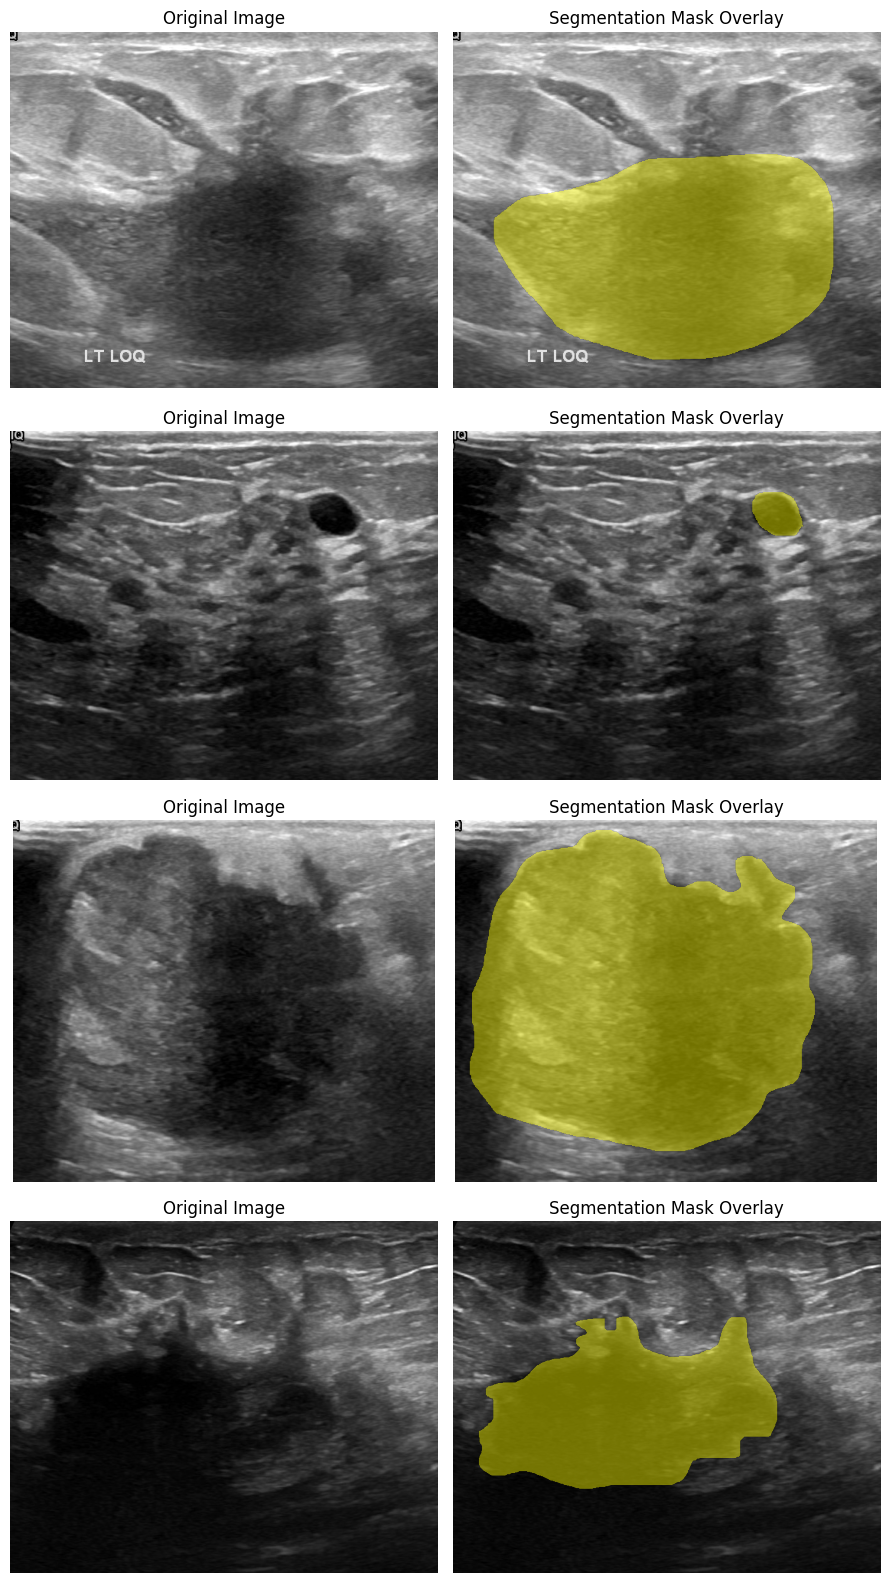

In [4]:
from PIL import Image

def load_image_and_mask(record):

    image = np.asarray(
        Image.open(record["image"]).convert("RGB")
    )

    mask = np.zeros(image.shape[:2], dtype=bool)

    for path in record["masks"]:

        current = np.asarray(
            Image.open(path).convert("L")
        )

        if current.shape != mask.shape:
            raise ValueError(
                f"Image-mask size mismatch: {path}"
            )

        mask |= current > 127

    return image, mask


rng = np.random.default_rng(42)

selected = rng.choice(
    len(records),
    size=min(4, len(records)),
    replace=False
)

fig, axes = plt.subplots(
    len(selected), 2,
    figsize=(9, 4 * len(selected)),
    squeeze=False
)

for row, index in enumerate(selected):

    record = records[int(index)]
    image, mask = load_image_and_mask(record)

    axes[row, 0].imshow(image)
    axes[row, 0].set_title("Original Image")

    axes[row, 1].imshow(image)

    overlay = np.ma.masked_where(~mask, mask)
    axes[row, 1].imshow(
        overlay,
        cmap="autumn",
        alpha=0.45,
        vmin=0,
        vmax=1
    )

    axes[row, 1].set_title("Segmentation Mask Overlay")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
from sklearn.model_selection import (
    train_test_split,
    GroupShuffleSplit
)

SEED = 42
indices = np.arange(len(records))

if DATASET == "busi":

    labels = np.array([r["label"] for r in records])

    train, remaining = train_test_split(
        indices,
        test_size=0.30,
        stratify=labels,
        random_state=SEED
    )

    val, test = train_test_split(
        remaining,
        test_size=0.50,
        stratify=labels[remaining],
        random_state=SEED
    )

elif DATASET == "isic2016":

    partitions = np.array([
        r["partition"] for r in records
    ])

    if "unknown" in partitions:
        raise ValueError(
            "Cannot verify the official ISIC train/test "
            "partition from these file paths."
        )

    official_train = indices[partitions == "train"]
    test = indices[partitions == "test"]

    if len(official_train) == 0:
        raise ValueError("No official ISIC training images found.")

    train, val = train_test_split(
        official_train,
        test_size=0.20,
        random_state=SEED
    )

    if len(test) == 0:
        print(
            "Warning: Official test masks are not available "
            "in this mirror. Do not report test results."
        )

elif DATASET == "lgg":

    groups = np.array([r["group"] for r in records])

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.30,
        random_state=SEED
    )

    train_pos, other_pos = next(
        splitter.split(indices, groups=groups)
    )

    train = indices[train_pos]
    remaining = indices[other_pos]

    splitter2 = GroupShuffleSplit(
        n_splits=1,
        test_size=0.50,
        random_state=SEED
    )

    val_pos, test_pos = next(
        splitter2.split(
            remaining,
            groups=groups[remaining]
        )
    )

    val = remaining[val_pos]
    test = remaining[test_pos]

    assert set(groups[train]).isdisjoint(groups[val])
    assert set(groups[train]).isdisjoint(groups[test])
    assert set(groups[val]).isdisjoint(groups[test])


for name, subset in [
    ("train", train),
    ("val", val),
    ("test", test)
]:
    for index in subset:
        records[int(index)]["split"] = name

print("Training images:", len(train))
print("Validation images:", len(val))
print("Test images:", len(test))

Training images: 546
Validation images: 117
Test images: 117


In [6]:
import json

manifest = []

for record in records:

    manifest.append({
        "dataset": DATASET,
        "image": str(
            record["image"].relative_to(data_root)
        ),
        "masks": json.dumps([
            str(p.relative_to(data_root))
            for p in record["masks"]
        ]),
        "group": record["group"],
        "split": record["split"]
    })

manifest_path = Path(
    f"/content/{DATASET}_split_manifest.csv"
)

pd.DataFrame(manifest).to_csv(
    manifest_path,
    index=False
)

print("Manifest saved:", manifest_path)

Manifest saved: /content/busi_split_manifest.csv


In [7]:
from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/"
    "IEEE_Medical_Lesion_Segmentation"
)

for folder in [
    "manifests",
    "checkpoints",
    "metrics",
    "figures",
    "logs"
]:
    (PROJECT_DIR / folder).mkdir(
        parents=True,
        exist_ok=True
    )

shutil.copy2(
    manifest_path,
    PROJECT_DIR / "manifests" / manifest_path.name
)

print("Project results directory:", PROJECT_DIR)

Mounted at /content/drive
Project results directory: /content/drive/MyDrive/IEEE_Medical_Lesion_Segmentation


In [11]:
from pathlib import Path
from datetime import datetime, timezone

RUN_NAME = (
    f"{DATASET}_pilot_"
    + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
)

RUN_DIR = Path("/content/Medical_Lesion_Segmentation_Research") / RUN_NAME

RUN_DIR.mkdir(parents=True, exist_ok=True)

print("Experiment directory:", RUN_DIR)

Experiment directory: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z


In [13]:
%pip install -q --force-reinstall --no-cache-dir --no-deps Pillow==11.3.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 107.2 MB/s eta 0:00:00


In [14]:
import PIL
import torch

from PIL import Image, ImageDraw, ImageFont
from torchvision.models import resnet18, ResNet18_Weights

print("Pillow version:", PIL.__version__)
print("PyTorch version:", torch.__version__)
print("Pillow import: SUCCESS")
print("Torchvision ResNet-18 import: SUCCESS")

Pillow version: 11.3.0
PyTorch version: 2.11.0+cu130
Pillow import: SUCCESS
Torchvision ResNet-18 import: SUCCESS


In [15]:
%pip install -q kagglehub pandas matplotlib scikit-learn

In [16]:
import math
import random
import numpy as np

import torch
import torch.nn as nn
import torch.nn.functional as F

from scipy import ndimage as ndi
from torchvision.models import resnet18, ResNet18_Weights

IMAGE_SIZE = 256

def adaptive_targets(y):
    """Create core, outer-support, and boundary-band targets."""

    y = np.asarray(y, dtype=bool)

    labels, n = ndi.label(
        y,
        structure=np.ones((3, 3), dtype=np.uint8)
    )

    core = np.zeros_like(y)
    outer = np.zeros_like(y)

    for k in range(1, n + 1):

        component = labels == k
        area = int(component.sum())

        radius = int(np.clip(
            math.floor(
                0.10 * math.sqrt(area / math.pi) + 0.5
            ),
            1, 8
        ))

        yy, xx = np.ogrid[
            -radius:radius + 1,
            -radius:radius + 1
        ]

        disk = (xx * xx + yy * yy) <= radius ** 2

        core |= ndi.binary_erosion(
            component, structure=disk, border_value=0
        )

        outer |= ndi.binary_dilation(
            component, structure=disk, border_value=0
        )

    band = outer & ~core

    return tuple(
        z.astype(np.float32)
        for z in (core, outer, band)
    )


class DecoderBlock(nn.Module):

    def __init__(self, channels, skip_channels, out_channels):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(
                channels + skip_channels,
                out_channels, 3, padding=1, bias=False
            ),
            nn.GroupNorm(8, out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels, out_channels,
                3, padding=1, bias=False
            ),
            nn.GroupNorm(8, out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x, skip):

        x = F.interpolate(
            x, size=skip.shape[-2:],
            mode="bilinear", align_corners=False
        )

        return self.net(torch.cat([x, skip], dim=1))


class RegionSeg(nn.Module):

    def __init__(self, variant="baseline", pretrained=True):
        super().__init__()

        assert variant in {"baseline", "proposed"}
        self.variant = variant

        weights = (
            ResNet18_Weights.DEFAULT if pretrained else None
        )

        encoder = resnet18(weights=weights)

        self.stem = nn.Sequential(
            encoder.conv1, encoder.bn1, encoder.relu
        )

        self.pool = encoder.maxpool
        self.l1 = encoder.layer1
        self.l2 = encoder.layer2
        self.l3 = encoder.layer3
        self.l4 = encoder.layer4

        self.up3 = DecoderBlock(512, 256, 128)
        self.up2 = DecoderBlock(128, 128, 96)
        self.up1 = DecoderBlock(96, 64, 64)
        self.up0 = DecoderBlock(64, 64, 32)
        self.high = DecoderBlock(32, 3, 24)

        if variant == "proposed":
            self.envelope = nn.Conv2d(64, 2, 1)
            self.head = nn.Conv2d(26, 1, 1)
        else:
            self.head = nn.Conv2d(24, 1, 1)

    def forward(self, x):

        s = self.stem(x)

        e1 = self.l1(self.pool(s))
        e2 = self.l2(e1)
        e3 = self.l3(e2)
        e4 = self.l4(e3)

        d3 = self.up3(e4, e3)
        d2 = self.up2(d3, e2)
        d1 = self.up1(d2, e1)
        d0 = self.up0(d1, s)

        features = self.high(d0, x)

        if self.variant == "baseline":
            return {"p": torch.sigmoid(self.head(features))}

        envelope = F.interpolate(
            self.envelope(d1),
            size=x.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        # Core probability
        c = torch.sigmoid(envelope[:, 0:1])

        # Outer-support probability
        o = c + (1 - c) * torch.sigmoid(
            envelope[:, 1:2]
        )

        # Fine allocation probability
        t = torch.sigmoid(
            self.head(torch.cat([features, c, o], dim=1))
        )

        # Final constrained prediction
        p = c + (o - c) * t

        return {"p": p, "c": c, "o": o, "t": t}


DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

for variant in ["baseline", "proposed"]:
    network = RegionSeg(variant, pretrained=False)
    print(
        variant,
        "parameters:",
        sum(p.numel() for p in network.parameters())
    )

Device: cuda
baseline parameters: 12702081
proposed parameters: 12702213


In [20]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader

class SegDataset(Dataset):

    def __init__(self, records, indices, augment=False):
        self.records = records
        self.indices = [int(i) for i in indices]
        self.augment = augment

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):

        record = self.records[self.indices[index]]
        image, mask = load_image_and_mask(record)

        image = np.asarray(
            Image.fromarray(image).resize(
                (IMAGE_SIZE, IMAGE_SIZE),
                Image.Resampling.BILINEAR
            )
        )

        mask = np.asarray(
            Image.fromarray(
                (mask.astype(np.uint8) * 255)
            ).resize(
                (IMAGE_SIZE, IMAGE_SIZE),
                Image.Resampling.NEAREST
            )
        ) > 127

        if self.augment and random.random() < 0.5:
            image = np.fliplr(image)
            mask = np.fliplr(mask)

        core, outer, band = adaptive_targets(mask)

        image = torch.from_numpy(
            np.ascontiguousarray(image.transpose(2, 0, 1))
        ).float() / 255.0

        mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
        std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]

        image = (image - mean) / std

        return (
            image,
            torch.from_numpy(mask[None].astype("float32")),
            torch.from_numpy(core[None]),
            torch.from_numpy(outer[None]),
            torch.from_numpy(band[None])
        )


def region_loss(probability, target):

    p = probability.clamp(1e-6, 1 - 1e-6)

    bce = F.binary_cross_entropy(p, target)

    axes = (1, 2, 3)
    foreground = target.sum(dim=axes) > 0

    intersection = (p * target).sum(dim=axes)

    dice_loss = 1 - (
        (2 * intersection + 1) /
        (p.sum(dim=axes) + target.sum(dim=axes) + 1)
    )

    if foreground.any():
        dice_term = dice_loss[foreground].mean()
    else:
        dice_term = bce.new_zeros(())

    return bce + dice_term


def combined_loss(prediction, batch, variant):

    _, y, core, outer, band = batch

    loss = region_loss(prediction["p"], y)

    if variant == "proposed":

        envelope_loss = (
            region_loss(prediction["c"], core) +
            region_loss(prediction["o"], outer)
        ) / 2

        band_ce = F.binary_cross_entropy(
            prediction["t"].clamp(1e-6, 1 - 1e-6),
            y,
            reduction="none"
        )

        axes = (1, 2, 3)
        band_area = band.sum(dim=axes)
        valid = band_area > 0

        if valid.any():

            per_image_band_loss = (
                (band_ce * band).sum(dim=axes) /
                band_area.clamp_min(1)
            )

            allocation_loss = per_image_band_loss[valid].mean()

        else:
            allocation_loss = loss.new_zeros(())

        loss = (
            loss +
            0.30 * envelope_loss +
            0.25 * allocation_loss
        )

    return loss


@torch.no_grad()
def evaluate(model, loader):

    model.eval()

    total_loss = 0
    dice_scores = []
    iou_scores = []

    empty_count = 0
    empty_false_positives = 0

    for batch in loader:

        batch = tuple(x.to(DEVICE) for x in batch)

        prediction = model(batch[0])
        loss = combined_loss(
            prediction, batch, model.variant
        )

        total_loss += loss.item() * batch[0].shape[0]

        predicted = (
            prediction["p"] >= 0.5
        ).cpu().numpy()

        ground_truth = (
            batch[1] >= 0.5
        ).cpu().numpy()

        for pred, truth in zip(predicted, ground_truth):

            if truth.any():

                tp = np.logical_and(pred, truth).sum()
                fp = np.logical_and(pred, ~truth).sum()
                fn = np.logical_and(~pred, truth).sum()

                dice_scores.append(
                    2 * tp / max(1, 2 * tp + fp + fn)
                )

                iou_scores.append(
                    tp / max(1, tp + fp + fn)
                )

            else:
                empty_count += 1
                empty_false_positives += int(pred.any())

    return {
        "val_loss": total_loss / len(loader.dataset),
        "val_dice": float(np.mean(dice_scores))
                    if dice_scores else float("nan"),
        "val_iou": float(np.mean(iou_scores))
                   if iou_scores else float("nan"),
        "empty_fp_rate": (
            empty_false_positives / empty_count
            if empty_count else float("nan")
        )
    }

In [22]:

# ============================================================
# CELL 11: CORRECTED MODEL TRAINING AND VALIDATION
# Breast, Skin, and Brain Lesion Medical Image Segmentation
# Models: Baseline vs Proposed Region-Guided Network
# ============================================================

import os
import json
import time
import random
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from datetime import datetime, timezone
from torch.utils.data import DataLoader

# ------------------------------------------------------------
# 1. EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

EPOCHS = 5
BATCH_SIZE = 8
SEED = 42
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4

EXPERIMENTS = ["baseline", "proposed"]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

USE_AMP = DEVICE.type == "cuda"

# Create experiment directory if not already defined
if "RUN_DIR" not in globals():

    RUN_NAME = (
        f"{DATASET}_pilot_" +
        datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    )

    RUN_DIR = (
        Path("/content/Medical_Lesion_Segmentation_Research")
        / RUN_NAME
    )
else:
    RUN_DIR = Path(RUN_DIR)
    RUN_NAME = RUN_DIR.name

RUN_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_dir = RUN_DIR / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

print("=" * 60)
print("MEDICAL IMAGE SEGMENTATION EXPERIMENT")
print("=" * 60)
print("Dataset:", DATASET)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Mixed precision:", USE_AMP)
print("Results directory:", RUN_DIR)
print("=" * 60)


# ------------------------------------------------------------
# 2. RANDOM SEED
# ------------------------------------------------------------

def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)


# ------------------------------------------------------------
# 3. DATASETS AND VALIDATION LOADER
# ------------------------------------------------------------

train_dataset = SegDataset(
    records,
    train,
    augment=True
)

val_dataset = SegDataset(
    records,
    val,
    augment=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=USE_AMP
)

print("\nTraining samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))


# ------------------------------------------------------------
# 4. SAVE EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

config = {
    "dataset": DATASET,
    "kaggle_dataset": DATASETS[DATASET],
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "image_size": IMAGE_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "seed": SEED,
    "models": EXPERIMENTS,
    "device": str(DEVICE),
    "mixed_precision": USE_AMP,
    "evaluation": "validation only; test set unused"
}

config_path = RUN_DIR / "config.json"

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)


# ------------------------------------------------------------
# 5. TRAINING STORAGE
# ------------------------------------------------------------

history = []
checkpoints = {}

history_path = RUN_DIR / "validation_history.csv"


# ------------------------------------------------------------
# 6. TRAIN BOTH MODELS
# ------------------------------------------------------------

for variant in EXPERIMENTS:

    print("\n" + "=" * 60)
    print("TRAINING MODEL:", variant.upper())
    print("=" * 60)

    # Same seed for a fair initial comparison
    set_seed(SEED)

    generator = torch.Generator()
    generator.manual_seed(SEED)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=2,
        pin_memory=USE_AMP
    )

    # Initialize model
    model = RegionSeg(
        variant=variant,
        pretrained=True
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    # Correct AMP GradScaler
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=USE_AMP
    )

    checkpoint_path = (
        checkpoint_dir / f"{variant}_best.pt"
    )

    checkpoints[variant] = checkpoint_path

    best_dice = -1.0
    best_epoch = 0

    cumulative_time = 0.0

    # --------------------------------------------------------
    # EPOCH LOOP
    # --------------------------------------------------------

    for epoch in range(1, EPOCHS + 1):

        epoch_start = time.perf_counter()

        model.train()

        total_train_loss = 0.0

        # ----------------------------------------------------
        # TRAINING LOOP
        # ----------------------------------------------------

        for batch in train_loader:

            batch = tuple(
                tensor.to(
                    DEVICE,
                    non_blocking=USE_AMP
                )
                for tensor in batch
            )

            optimizer.zero_grad(set_to_none=True)

            # ================================================
            # FIX 1:
            # Use autocast ONLY for model forward pass
            # ================================================

            with torch.autocast(
                device_type=DEVICE.type,
                enabled=USE_AMP
            ):

                prediction = model(batch[0])

            # ================================================
            # FIX 2:
            # Convert model outputs to float32
            # OUTSIDE autocast
            # ================================================

            prediction = {
                key: value.float()
                for key, value in prediction.items()
            }

            # ================================================
            # FIX 3:
            # Calculate BCE + Dice + auxiliary losses
            # OUTSIDE autocast
            # ================================================

            loss = combined_loss(
                prediction,
                batch,
                variant
            )

            # Check numerical stability
            if not torch.isfinite(loss):
                raise RuntimeError(
                    f"Non-finite loss detected. "
                    f"Model={variant}, Epoch={epoch}, "
                    f"Loss={loss.item()}"
                )

            # ================================================
            # FIX 4:
            # Backpropagation with gradient scaling
            # ================================================

            scaler.scale(loss).backward()

            scaler.step(optimizer)

            scaler.update()

            total_train_loss += (
                loss.detach().item() * batch[0].size(0)
            )

        # ----------------------------------------------------
        # TRAINING LOSS
        # ----------------------------------------------------

        train_loss = (
            total_train_loss / len(train_dataset)
        )

        # ----------------------------------------------------
        # VALIDATION
        # ----------------------------------------------------

        # evaluate() runs without autocast and computes
        # segmentation metrics on validation data.
        metrics = evaluate(
            model,
            val_loader
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        epoch_seconds = (
            time.perf_counter() - epoch_start
        )

        cumulative_time += epoch_seconds

        # ----------------------------------------------------
        # SAVE EPOCH RESULTS
        # ----------------------------------------------------

        row = {
            "model": variant,
            "epoch": epoch,
            "train_loss": float(train_loss),
            "epoch_seconds": float(epoch_seconds),
            "cumulative_seconds": float(cumulative_time),
            **metrics
        }

        history.append(row)

        # Save after every epoch
        pd.DataFrame(history).to_csv(
            history_path,
            index=False
        )

        # ----------------------------------------------------
        # SAVE BEST MODEL BASED ON VALIDATION DICE
        # ----------------------------------------------------

        current_dice = float(metrics["val_dice"])

        if (
            epoch == 1 or
            (
                np.isfinite(current_dice)
                and current_dice > best_dice
            )
        ):

            best_dice = current_dice
            best_epoch = epoch

            torch.save(
                {
                    "model": variant,
                    "epoch": epoch,
                    "state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "best_val_dice": best_dice,
                    "config": config
                },
                checkpoint_path
            )

        # ----------------------------------------------------
        # DISPLAY EPOCH RESULTS
        # ----------------------------------------------------

        print(
            f"Epoch [{epoch}/{EPOCHS}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {metrics['val_loss']:.4f} | "
            f"Val Dice: {metrics['val_dice']:.4f} | "
            f"Val IoU: {metrics['val_iou']:.4f} | "
            f"Time: {epoch_seconds:.1f}s"
        )

    # --------------------------------------------------------
    # MODEL TRAINING COMPLETED
    # --------------------------------------------------------

    print("\nModel training completed:", variant)
    print("Best validation Dice:", best_dice)
    print("Best epoch:", best_epoch)
    print("Checkpoint:", checkpoint_path)

    # Release model memory before training next model
    del model
    del optimizer
    del scaler

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 7. EXPERIMENT SUMMARY
# ------------------------------------------------------------

df = pd.DataFrame(history)

summary_rows = []

for variant in EXPERIMENTS:

    subset = df[df["model"] == variant].copy()

    best_idx = subset["val_dice"].idxmax()
    best_row = subset.loc[best_idx]

    summary_rows.append({
        "model": variant,
        "best_epoch": int(best_row["epoch"]),
        "best_val_dice": float(best_row["val_dice"]),
        "val_iou_at_best_dice": float(best_row["val_iou"]),
        "empty_fp_rate_at_best_dice": float(
            best_row["empty_fp_rate"]
        ),
        "total_training_seconds": float(
            subset["epoch_seconds"].sum()
        )
    })

summary = pd.DataFrame(summary_rows)

summary_path = RUN_DIR / "experiment_summary.csv"

summary.to_csv(
    summary_path,
    index=False
)

print("\n" + "=" * 60)
print("FINAL EXPERIMENT SUMMARY")
print("=" * 60)

print(summary.to_string(index=False))

print("\nSaved files:")
print("Training history:", history_path)
print("Experiment summary:", summary_path)
print("Configuration:", config_path)
print("Model checkpoints:", checkpoint_dir)

print("\nSUCCESS: Training and validation completed.")
print("Held-out test set has not been evaluated.")


MEDICAL IMAGE SEGMENTATION EXPERIMENT
Dataset: busi
Device: cuda
GPU: Tesla T4
Epochs: 5
Batch size: 8
Mixed precision: True
Results directory: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z

Training samples: 546
Validation samples: 117

TRAINING MODEL: BASELINE
Epoch [1/5] | Train Loss: 1.2303 | Val Loss: 1.0876 | Val Dice: 0.5593 | Val IoU: 0.4329 | Time: 16.8s
Epoch [2/5] | Train Loss: 1.0460 | Val Loss: 0.9945 | Val Dice: 0.6191 | Val IoU: 0.4922 | Time: 14.0s
Epoch [3/5] | Train Loss: 0.9465 | Val Loss: 0.9246 | Val Dice: 0.5966 | Val IoU: 0.4848 | Time: 14.0s
Epoch [4/5] | Train Loss: 0.8752 | Val Loss: 0.8718 | Val Dice: 0.6410 | Val IoU: 0.5224 | Time: 14.3s
Epoch [5/5] | Train Loss: 0.8002 | Val Loss: 0.7880 | Val Dice: 0.6906 | Val IoU: 0.5837 | Time: 14.2s

Model training completed: baseline
Best validation Dice: 0.6905804450517498
Best epoch: 5
Checkpoint: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z/checkpoints/basel

BUSI EXPERIMENTAL RESULTS

Experiment directory: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z

Training history:
   model  epoch  train_loss  epoch_seconds  cumulative_seconds  val_loss  val_dice  val_iou  empty_fp_rate
baseline      1    1.230317      16.775607           16.775607  1.087616  0.559272 0.432866           1.00
baseline      2    1.045963      13.987038           30.762645  0.994516  0.619086 0.492192           1.00
baseline      3    0.946535      13.989811           44.752456  0.924594  0.596598 0.484781           0.85
baseline      4    0.875189      14.281506           59.033961  0.871766  0.640977 0.522352           1.00
baseline      5    0.800201      14.221966           73.255927  0.788001  0.690580 0.583738           0.60
proposed      1    1.575180      14.363291           14.363291  1.331841  0.630108 0.525777           0.15
proposed      2    1.222644      14.309007           28.672298  1.113127  0.639851 0.516225           0.60
pr

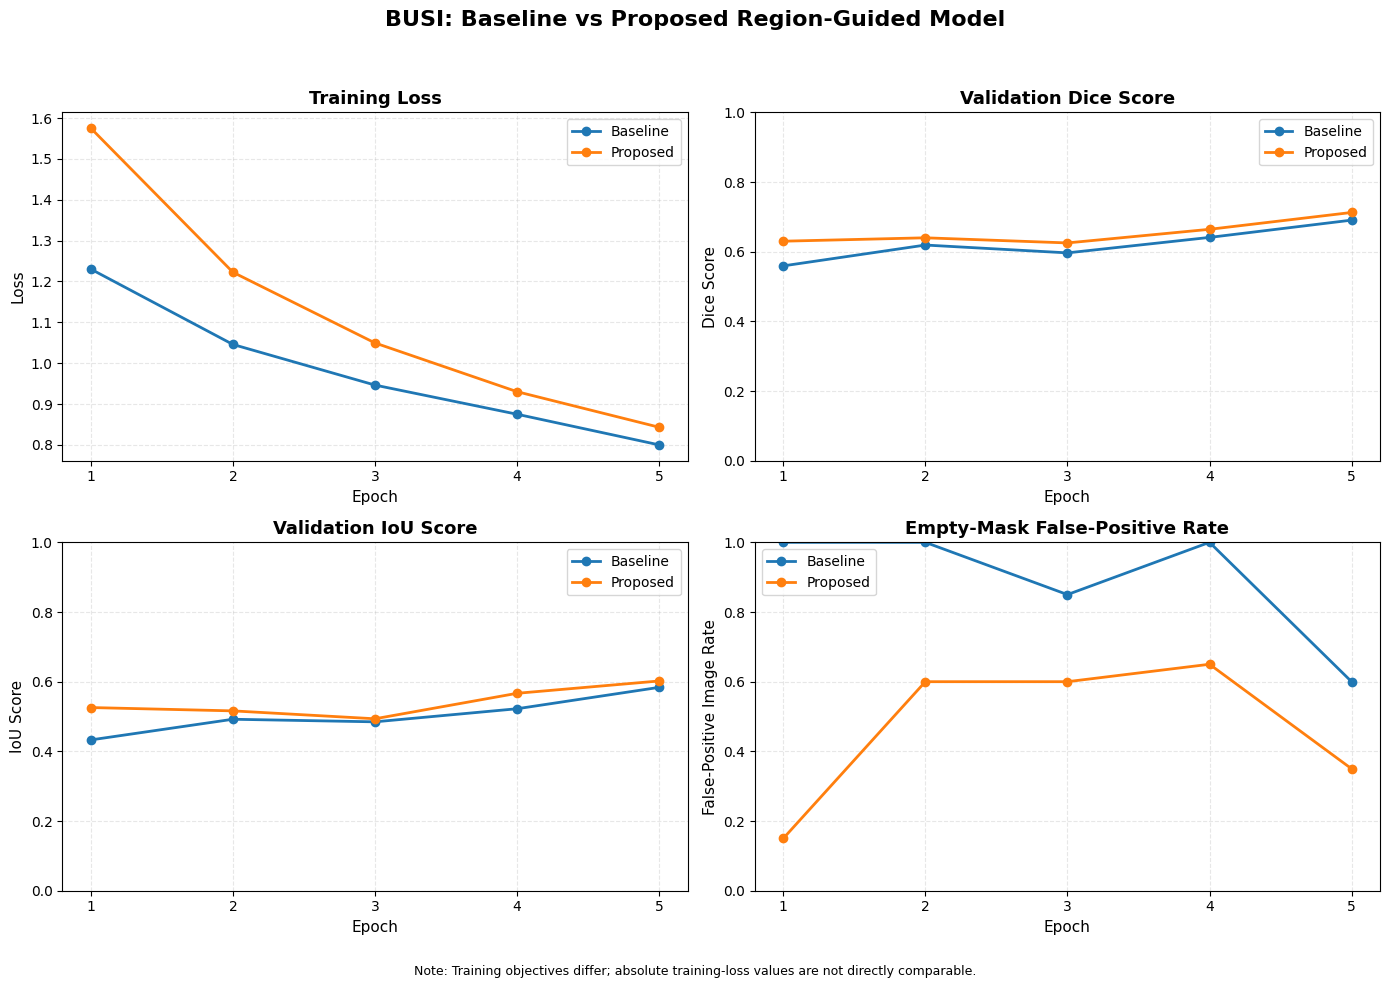


Experimental graph saved successfully!
File: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z/BUSI_Experimental_Graphs.png

BASELINE VS PROPOSED MODEL COMPARISON
   Model  Best Epoch  Validation Dice  Validation IoU  Empty FP Rate
Baseline           5           0.6906          0.5837         0.6000
Proposed           5           0.7126          0.6020         0.3500

PERFORMANCE DIFFERENCES
------------------------------------------------------------
Dice difference: +0.0220 (+2.20 percentage points)
IoU difference: +0.0183 (+1.83 percentage points)
Empty FP rate difference: -0.2500 (-25.00 percentage points)

ALL OUTPUTS SAVED SUCCESSFULLY
Graph: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z/BUSI_Experimental_Graphs.png
Comparison CSV: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z/BUSI_Model_Comparison.csv
PNG size: 449.15 KB

Cell 11 completed successfully.
You can now proceed to Cell 12.


In [24]:

# ============================================================
# CELL 11: EXPERIMENTAL GRAPHS AND MODEL COMPARISON
# Breast, Skin, and Brain Lesion Medical Image Segmentation
#
# Dataset: BUSI
# Models: Baseline vs Proposed Region-Guided Model
#
# FIX: PNG output only; SVG export removed.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. LOAD SAVED EXPERIMENTAL RESULTS
# ------------------------------------------------------------

RUN_DIR = Path(RUN_DIR)

history_path = RUN_DIR / "validation_history.csv"

if not history_path.is_file():
    raise FileNotFoundError(
        f"Training history not found: {history_path}"
    )

df = pd.read_csv(history_path)

print("=" * 60)
print("BUSI EXPERIMENTAL RESULTS")
print("=" * 60)

print("\nExperiment directory:", RUN_DIR)
print("\nTraining history:")
print(df.to_string(index=False))

# ------------------------------------------------------------
# 2. VALIDATE REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "model",
    "epoch",
    "train_loss",
    "val_loss",
    "val_dice",
    "val_iou",
    "empty_fp_rate"
]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(
        f"Missing columns in CSV: {missing}"
    )

for column in required_columns[1:]:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

models = ["baseline", "proposed"]

for model_name in models:
    if df[df["model"] == model_name].empty:
        raise ValueError(
            f"No results found for {model_name}"
        )

# ------------------------------------------------------------
# 3. CREATE FOUR EXPERIMENTAL GRAPHS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

graphs = [
    (
        "train_loss",
        "Training Loss",
        "Loss"
    ),
    (
        "val_dice",
        "Validation Dice Score",
        "Dice Score"
    ),
    (
        "val_iou",
        "Validation IoU Score",
        "IoU Score"
    ),
    (
        "empty_fp_rate",
        "Empty-Mask False-Positive Rate",
        "False-Positive Image Rate"
    )
]

for ax, (metric, title, ylabel) in zip(
    axes.flatten(), graphs
):

    for model_name in models:

        subset = df[
            df["model"] == model_name
        ].sort_values("epoch")

        ax.plot(
            subset["epoch"],
            subset[metric],
            marker="o",
            linewidth=2,
            markersize=6,
            label=model_name.capitalize()
        )

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Epoch", fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)

    ax.set_xticks(
        sorted(df["epoch"].dropna().unique())
    )

    if metric in [
        "val_dice",
        "val_iou",
        "empty_fp_rate"
    ]:
        ax.set_ylim(0, 1.0)

    ax.grid(
        True,
        linestyle="--",
        alpha=0.3
    )

    ax.legend(fontsize=10)

fig.suptitle(
    "BUSI: Baseline vs Proposed Region-Guided Model",
    fontsize=16,
    fontweight="bold"
)

fig.text(
    0.5,
    0.015,
    "Note: Training objectives differ; "
    "absolute training-loss values are not directly comparable.",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.04, 1, 0.95])

# ------------------------------------------------------------
# 4. SAVE PNG IMAGE (NO SVG)
# ------------------------------------------------------------

figure_path = RUN_DIR / "BUSI_Experimental_Graphs.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
    format="png"
)

plt.show()
plt.close(fig)

print("\nExperimental graph saved successfully!")
print("File:", figure_path)

# ------------------------------------------------------------
# 5. CREATE MODEL COMPARISON TABLE
# ------------------------------------------------------------

comparison = []

for model_name in models:

    subset = df[
        df["model"] == model_name
    ].copy()

    subset = subset.dropna(
        subset=["val_dice"]
    )

    if subset.empty:
        raise ValueError(
            f"No valid Dice results for {model_name}"
        )

    best_row = subset.loc[
        subset["val_dice"].idxmax()
    ]

    comparison.append({
        "Model": model_name.capitalize(),
        "Best Epoch": int(best_row["epoch"]),
        "Validation Dice": float(
            best_row["val_dice"]
        ),
        "Validation IoU": float(
            best_row["val_iou"]
        ),
        "Empty FP Rate": float(
            best_row["empty_fp_rate"]
        )
    })

comparison_df = pd.DataFrame(comparison)

print("\n" + "=" * 60)
print("BASELINE VS PROPOSED MODEL COMPARISON")
print("=" * 60)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 6. CALCULATE PERFORMANCE DIFFERENCES
# ------------------------------------------------------------

baseline = comparison_df.iloc[0]
proposed = comparison_df.iloc[1]

dice_gain = (
    proposed["Validation Dice"]
    - baseline["Validation Dice"]
)

iou_gain = (
    proposed["Validation IoU"]
    - baseline["Validation IoU"]
)

fp_change = (
    proposed["Empty FP Rate"]
    - baseline["Empty FP Rate"]
)

print("\nPERFORMANCE DIFFERENCES")
print("-" * 60)

print(
    f"Dice difference: {dice_gain:+.4f} "
    f"({dice_gain * 100:+.2f} percentage points)"
)

print(
    f"IoU difference: {iou_gain:+.4f} "
    f"({iou_gain * 100:+.2f} percentage points)"
)

print(
    f"Empty FP rate difference: {fp_change:+.4f} "
    f"({fp_change * 100:+.2f} percentage points)"
)

# ------------------------------------------------------------
# 7. SAVE COMPARISON TABLE
# ------------------------------------------------------------

comparison_path = (
    RUN_DIR / "BUSI_Model_Comparison.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

print("\n" + "=" * 60)
print("ALL OUTPUTS SAVED SUCCESSFULLY")
print("=" * 60)

print("Graph:", figure_path)
print("Comparison CSV:", comparison_path)

if figure_path.is_file():
    print(
        "PNG size:",
        round(
            figure_path.stat().st_size / 1024,
            2
        ),
        "KB"
    )

print("\nCell 11 completed successfully.")
print("You can now proceed to Cell 12.")


Loaded baseline: best checkpoint from epoch 5
Loaded proposed: best checkpoint from epoch 5
Foreground validation images: 97
Empty-mask validation images: 20


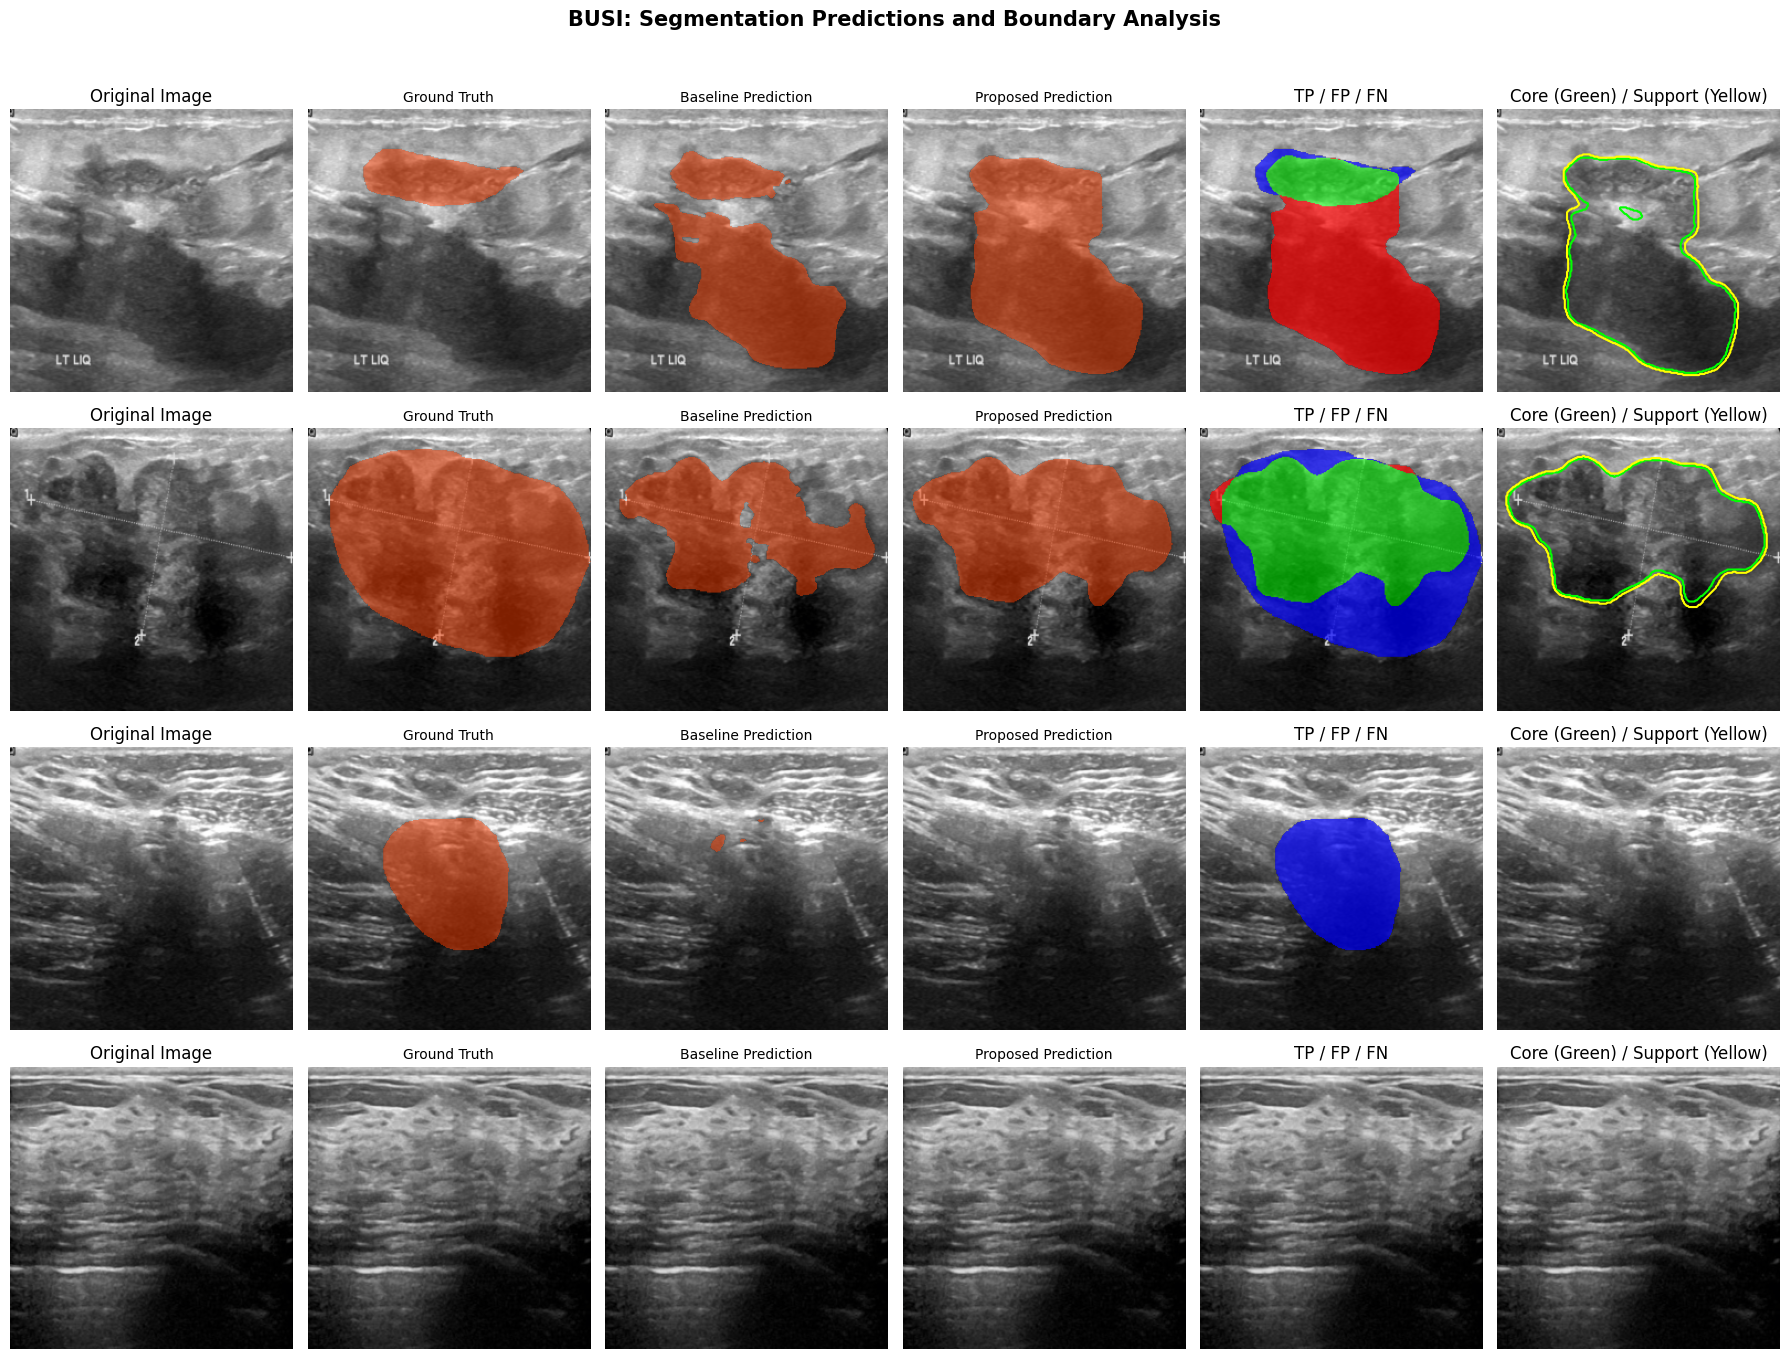


SEGMENTATION VISUALIZATION COMPLETED
           image  foreground_pixels  baseline_dice  proposed_dice  baseline_fp_pixels  proposed_fp_pixels  proposed_fn_pixels
benign (408).png               4940       0.292050       0.294674               13891               18226                 937
benign (141).png              33613       0.656676       0.770328                 136                 452               12273
benign (233).png              10768       0.030364       0.000000                   0                   0               10768
 normal (47).png                  0            NaN            NaN                   0                   0                   0

Saved figure: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z/BUSI_Segmentation_Comparison.png
Saved sample metrics: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z/BUSI_Visual_Sample_Metrics.csv

Cell 12 completed successfully.


In [25]:

# ============================================================
# CELL 12: SEGMENTATION VISUALIZATION AND ERROR ANALYSIS
# Dataset: BUSI
# Models: Baseline vs Proposed Region-Guided Model
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from pathlib import Path

RUN_DIR = Path(RUN_DIR)

# ------------------------------------------------------------
# 1. LOAD TRAINED MODELS
# ------------------------------------------------------------

models = {}

for variant in ["baseline", "proposed"]:

    checkpoint_path = (
        RUN_DIR / "checkpoints" / f"{variant}_best.pt"
    )

    if not checkpoint_path.exists():
        raise FileNotFoundError(checkpoint_path)

    network = RegionSeg(
        variant=variant,
        pretrained=False
    ).to(DEVICE)

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    network.load_state_dict(checkpoint["state_dict"])
    network.eval()

    models[variant] = network

    print(
        f"Loaded {variant}: "
        f"best checkpoint from epoch {checkpoint['epoch']}"
    )

# ------------------------------------------------------------
# 2. VALIDATION DATASET
# ------------------------------------------------------------

val_dataset = SegDataset(
    records,
    val,
    augment=False
)

positive_indices = []
empty_indices = []

for i, source_index in enumerate(val_dataset.indices):

    _, mask = load_image_and_mask(records[source_index])

    if mask.any():
        positive_indices.append(i)
    else:
        empty_indices.append(i)

print("Foreground validation images:", len(positive_indices))
print("Empty-mask validation images:", len(empty_indices))

# Deterministic sample selection (not based on model scores)
rng = np.random.default_rng(42)

selected = []

if positive_indices:
    selected.extend(
        rng.choice(
            positive_indices,
            size=min(3, len(positive_indices)),
            replace=False
        ).tolist()
    )

if empty_indices:
    selected.append(int(rng.choice(empty_indices)))

if not selected:
    raise RuntimeError("No validation samples available.")

# ------------------------------------------------------------
# 3. HELPER FUNCTIONS
# ------------------------------------------------------------

def denormalize_image(x):

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    img = x.permute(1, 2, 0).cpu().numpy()
    return np.clip(img * std + mean, 0, 1)


def calculate_dice(pred, truth):

    if not truth.any():
        return float("nan")

    intersection = np.logical_and(pred, truth).sum()

    return (
        2 * intersection /
        max(1, pred.sum() + truth.sum())
    )


def draw_overlay(ax, image, mask, title):

    ax.imshow(image)

    overlay = np.zeros(
        (*mask.shape, 4), dtype=np.float32
    )

    overlay[mask] = [1, 0.25, 0, 0.50]

    ax.imshow(overlay)
    ax.set_title(title, fontsize=10)
    ax.axis("off")


# ------------------------------------------------------------
# 4. CREATE SEGMENTATION COMPARISON FIGURE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    len(selected),
    6,
    figsize=(18, 3.5 * len(selected)),
    squeeze=False
)

result_rows = []

for row, sample_index in enumerate(selected):

    x, y, _, _, _ = val_dataset[sample_index]

    image = denormalize_image(x)
    truth = y[0].numpy() >= 0.5

    predictions = {}

    with torch.no_grad():

        for variant, network in models.items():

            output = network(
                x.unsqueeze(0).to(DEVICE)
            )

            predictions[variant] = {
                key: value[0, 0].cpu().numpy()
                for key, value in output.items()
            }

    baseline = predictions["baseline"]["p"] >= 0.5
    proposed = predictions["proposed"]["p"] >= 0.5

    # Original image
    axes[row, 0].imshow(image)
    axes[row, 0].set_title("Original Image")
    axes[row, 0].axis("off")

    # Ground-truth overlay
    draw_overlay(
        axes[row, 1],
        image,
        truth,
        "Ground Truth"
    )

    # Baseline overlay
    draw_overlay(
        axes[row, 2],
        image,
        baseline,
        "Baseline Prediction"
    )

    # Proposed overlay
    draw_overlay(
        axes[row, 3],
        image,
        proposed,
        "Proposed Prediction"
    )

    # Error map
    tp = proposed & truth
    fp = proposed & ~truth
    fn = ~proposed & truth

    error_rgba = np.zeros(
        (*truth.shape, 4), dtype=np.float32
    )

    error_rgba[tp] = [0, 1, 0, 0.55]  # Green = correct
    error_rgba[fp] = [1, 0, 0, 0.70]  # Red = false positive
    error_rgba[fn] = [0, 0, 1, 0.70]  # Blue = missed lesion

    axes[row, 4].imshow(image)
    axes[row, 4].imshow(error_rgba)
    axes[row, 4].set_title("TP / FP / FN")
    axes[row, 4].axis("off")

    # Proposed core and outer-support contours
    core = predictions["proposed"]["c"] >= 0.5
    outer = predictions["proposed"]["o"] >= 0.5

    axes[row, 5].imshow(image)

    if core.any() and not core.all():
        axes[row, 5].contour(
            core.astype(float),
            levels=[0.5],
            colors=["lime"],
            linewidths=1.5
        )

    if outer.any() and not outer.all():
        axes[row, 5].contour(
            outer.astype(float),
            levels=[0.5],
            colors=["yellow"],
            linewidths=1.5
        )

    axes[row, 5].set_title(
        "Core (Green) / Support (Yellow)"
    )
    axes[row, 5].axis("off")

    baseline_dice = calculate_dice(baseline, truth)
    proposed_dice = calculate_dice(proposed, truth)

    source_index = val_dataset.indices[sample_index]

    result_rows.append({
        "image": records[source_index]["image"].name,
        "foreground_pixels": int(truth.sum()),
        "baseline_dice": baseline_dice,
        "proposed_dice": proposed_dice,
        "baseline_fp_pixels": int(
            np.logical_and(baseline, ~truth).sum()
        ),
        "proposed_fp_pixels": int(fp.sum()),
        "proposed_fn_pixels": int(fn.sum())
    })

fig.suptitle(
    "BUSI: Segmentation Predictions and Boundary Analysis",
    fontsize=15,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0, 1, 0.96])

# ------------------------------------------------------------
# 5. SAVE FIGURE
# ------------------------------------------------------------

figure_path = RUN_DIR / "BUSI_Segmentation_Comparison.png"

fig.savefig(
    figure_path,
    dpi=250,
    bbox_inches="tight",
    facecolor="white",
    format="png"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. SAVE SAMPLE-LEVEL RESULTS
# ------------------------------------------------------------

sample_results = pd.DataFrame(result_rows)

csv_path = RUN_DIR / "BUSI_Visual_Sample_Metrics.csv"

sample_results.to_csv(csv_path, index=False)

print("\n" + "=" * 60)
print("SEGMENTATION VISUALIZATION COMPLETED")
print("=" * 60)

print(sample_results.to_string(index=False))

print("\nSaved figure:", figure_path)
print("Saved sample metrics:", csv_path)

print("\nCell 12 completed successfully.")


In [26]:
from google.colab import drive
import shutil

drive.mount("/content/drive")

destination = (
    Path("/content/drive/MyDrive")
    / "Medical_Lesion_Segmentation_Research"
    / RUN_DIR.name
)

destination.parent.mkdir(parents=True, exist_ok=True)

shutil.copytree(
    RUN_DIR,
    destination,
    dirs_exist_ok=True
)

print("Experiment backed up to:", destination)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Experiment backed up to: /content/drive/MyDrive/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z


In [27]:

# ============================================================
# CELL 13: FULL VALIDATION-SET ERROR ANALYSIS
# Dataset: BUSI
# Models: Baseline and Proposed
# No retraining; held-out test set remains unused.
# ============================================================

import numpy as np
import pandas as pd
import torch
from scipy import ndimage as ndi
from pathlib import Path

RUN_DIR = Path(RUN_DIR)
BOUNDARY_TOLERANCE = 2  # Pixels on 256 x 256 evaluation grid

# Models must already be loaded by Cell 12.
assert "models" in globals(), "Run Cell 12 first."
assert "val_dataset" in globals(), "Run Cell 12 first."

def extract_boundary(mask):
    mask = np.asarray(mask, dtype=bool)
    eroded = ndi.binary_erosion(
        mask,
        structure=np.ones((3, 3), dtype=bool),
        border_value=0
    )
    return mask & ~eroded


def boundary_metrics(pred, truth, tolerance=2):

    # No foreground reference: report separately.
    if not truth.any():
        return np.nan, np.nan

    # Complete miss: boundary F1 = 0, HD95 undefined.
    if not pred.any():
        return 0.0, np.nan

    pb = extract_boundary(pred)
    tb = extract_boundary(truth)

    distance_to_truth = ndi.distance_transform_edt(~tb)
    distance_to_pred = ndi.distance_transform_edt(~pb)

    d_pred_to_truth = distance_to_truth[pb]
    d_truth_to_pred = distance_to_pred[tb]

    boundary_precision = np.mean(
        d_pred_to_truth <= tolerance
    )

    boundary_recall = np.mean(
        d_truth_to_pred <= tolerance
    )

    if boundary_precision + boundary_recall == 0:
        bf1 = 0.0
    else:
        bf1 = (
            2 * boundary_precision * boundary_recall
            / (boundary_precision + boundary_recall)
        )

    hd95 = max(
        np.percentile(d_pred_to_truth, 95),
        np.percentile(d_truth_to_pred, 95)
    )

    return float(bf1), float(hd95)


def compute_case_metrics(pred, truth):

    pred = np.asarray(pred, dtype=bool)
    truth = np.asarray(truth, dtype=bool)

    tp = int((pred & truth).sum())
    fp = int((pred & ~truth).sum())
    fn = int((~pred & truth).sum())

    gt_pixels = int(truth.sum())
    pred_pixels = int(pred.sum())

    if gt_pixels > 0:

        dice = 2 * tp / max(1, 2 * tp + fp + fn)
        iou = tp / max(1, tp + fp + fn)

        precision = tp / max(1, tp + fp)
        recall = tp / max(1, tp + fn)

        bf1, hd95 = boundary_metrics(
            pred, truth, BOUNDARY_TOLERANCE
        )

    else:
        # Empty masks are evaluated through FP measurements.
        dice = np.nan
        iou = np.nan
        precision = np.nan
        recall = np.nan
        bf1 = np.nan
        hd95 = np.nan

    return {
        "gt_pixels": gt_pixels,
        "pred_pixels": pred_pixels,
        "tp_pixels": tp,
        "fp_pixels": fp,
        "fn_pixels": fn,
        "dice": dice,
        "iou": iou,
        "precision": precision,
        "recall": recall,
        "boundary_f1": bf1,
        "hd95_px": hd95,
        "complete_miss": int(
            gt_pixels > 0 and pred_pixels == 0
        ),
        "empty_fp_image": int(
            gt_pixels == 0 and pred_pixels > 0
        )
    }


# ------------------------------------------------------------
# EVALUATE EVERY VALIDATION IMAGE
# ------------------------------------------------------------

rows = []

for network in models.values():
    network.eval()

for i in range(len(val_dataset)):

    x, y, _, _, _ = val_dataset[i]

    truth = y[0].numpy() >= 0.5

    source_index = val_dataset.indices[i]
    record = records[source_index]

    for name, network in models.items():

        with torch.inference_mode():
            output = network(
                x.unsqueeze(0).to(DEVICE)
            )

        probability = (
            output["p"][0, 0]
            .float()
            .cpu()
            .numpy()
        )

        pred = probability >= 0.5

        metrics = compute_case_metrics(pred, truth)

        rows.append({
            "sample_index": i,
            "image": record["image"].name,
            "category": record["label"],
            "model": name,
            **metrics,
            "max_probability": float(probability.max()),
            "mean_probability": float(probability.mean())
        })


results = pd.DataFrame(rows)

case_path = RUN_DIR / "BUSI_Validation_Per_Image.csv"
results.to_csv(case_path, index=False)

print("Evaluated images:", len(val_dataset))
print("Model predictions:", len(results))


# ------------------------------------------------------------
# SUMMARIZE EACH MODEL
# ------------------------------------------------------------

summary = []

for name in ["baseline", "proposed"]:

    subset = results[results["model"] == name]

    positive = subset[subset["gt_pixels"] > 0]
    empty = subset[subset["gt_pixels"] == 0]

    summary.append({
        "model": name,
        "foreground_images": len(positive),
        "empty_images": len(empty),
        "mean_dice": positive["dice"].mean(),
        "mean_iou": positive["iou"].mean(),
        "mean_precision": positive["precision"].mean(),
        "mean_recall": positive["recall"].mean(),
        "mean_boundary_f1": positive["boundary_f1"].mean(),
        "mean_finite_hd95_px": positive["hd95_px"].mean(),
        "hd95_undefined_count": int(
            positive["hd95_px"].isna().sum()
        ),
        "complete_misses": int(
            positive["complete_miss"].sum()
        ),
        "empty_fp_rate": (
            empty["empty_fp_image"].mean()
            if len(empty) else np.nan
        ),
        "mean_fp_pixels_on_empty": (
            empty["fp_pixels"].mean()
            if len(empty) else np.nan
        )
    })

summary_df = pd.DataFrame(summary)

summary_path = RUN_DIR / "BUSI_Full_Validation_Summary.csv"
summary_df.to_csv(summary_path, index=False)

print("\nFULL VALIDATION SUMMARY")
print(summary_df.T.to_string())


# ------------------------------------------------------------
# PAIRED PER-IMAGE DICE ANALYSIS
# ------------------------------------------------------------

positive_results = results[results["gt_pixels"] > 0]

paired = positive_results.pivot(
    index="sample_index",
    columns="model",
    values="dice"
).dropna()

paired["dice_difference"] = (
    paired["proposed"] - paired["baseline"]
)

print("\nPAIRED DICE COMPARISON")
print("Improved images:",
      int((paired["dice_difference"] > 0).sum()))
print("Worsened images:",
      int((paired["dice_difference"] < 0).sum()))
print("Tied images:",
      int((paired["dice_difference"] == 0).sum()))
print("Mean paired Dice difference:",
      round(paired["dice_difference"].mean(), 4))

# Find cases where the proposed model performs worse.
worst = paired.nsmallest(10, "dice_difference")

image_names = (
    positive_results[positive_results["model"] == "proposed"]
    .set_index("sample_index")["image"]
)

worst = worst.join(image_names)

print("\nTEN LARGEST DICE DECREASES")
print(worst.to_string())


# ------------------------------------------------------------
# INSPECT THE KNOWN COMPLETE-MISS EXAMPLE
# ------------------------------------------------------------

print("\nBENIGN (233) PREDICTION DIAGNOSTICS")

diagnostic = results[
    results["image"].str.lower() == "benign (233).png"
]

print(
    diagnostic[
        [
            "model",
            "gt_pixels",
            "pred_pixels",
            "max_probability",
            "mean_probability",
            "dice"
        ]
    ].to_string(index=False)
)

print("\nSaved per-image results:", case_path)
print("Saved validation summary:", summary_path)
print("\nCell 13 completed.")


Evaluated images: 117
Model predictions: 234

FULL VALIDATION SUMMARY
                                 0          1
model                     baseline   proposed
foreground_images               97         97
empty_images                    20         20
mean_dice                  0.69058   0.712586
mean_iou                  0.583738   0.602044
mean_precision            0.685691   0.687693
mean_recall                0.77676   0.819706
mean_boundary_f1          0.286641   0.310513
mean_finite_hd95_px      35.787035  36.658955
hd95_undefined_count             3          3
complete_misses                  3          3
empty_fp_rate                  0.6       0.35
mean_fp_pixels_on_empty     1226.0      521.1

PAIRED DICE COMPARISON
Improved images: 49
Worsened images: 46
Tied images: 2
Mean paired Dice difference: 0.022

TEN LARGEST DICE DECREASES
              baseline  proposed  dice_difference                image
sample_index                                                          
70

PAIRED VALIDATION COMPARISON
     metric  paired_images  mean_difference  median_difference  bootstrap_low  bootstrap_high
       dice             97         0.022006           0.000635      -0.012722        0.058425
        iou             97         0.018306           0.000959      -0.012819        0.049054
boundary_f1             97         0.023872           0.012235      -0.011611        0.061382
    hd95_px             91        -0.653436           0.269070      -4.353096        2.838267

LESION-OMISSION ANALYSIS
baseline | Empty predictions: 3 | Zero-overlap predictions: 5
proposed | Empty predictions: 3 | Zero-overlap predictions: 6

DICE DIFFERENCES BY CATEGORY
benign | Images: 65 | Mean difference: 0.0013 | Improved: 34 | Worsened: 29
malignant | Images: 32 | Mean difference: 0.064 | Improved: 15 | Worsened: 17


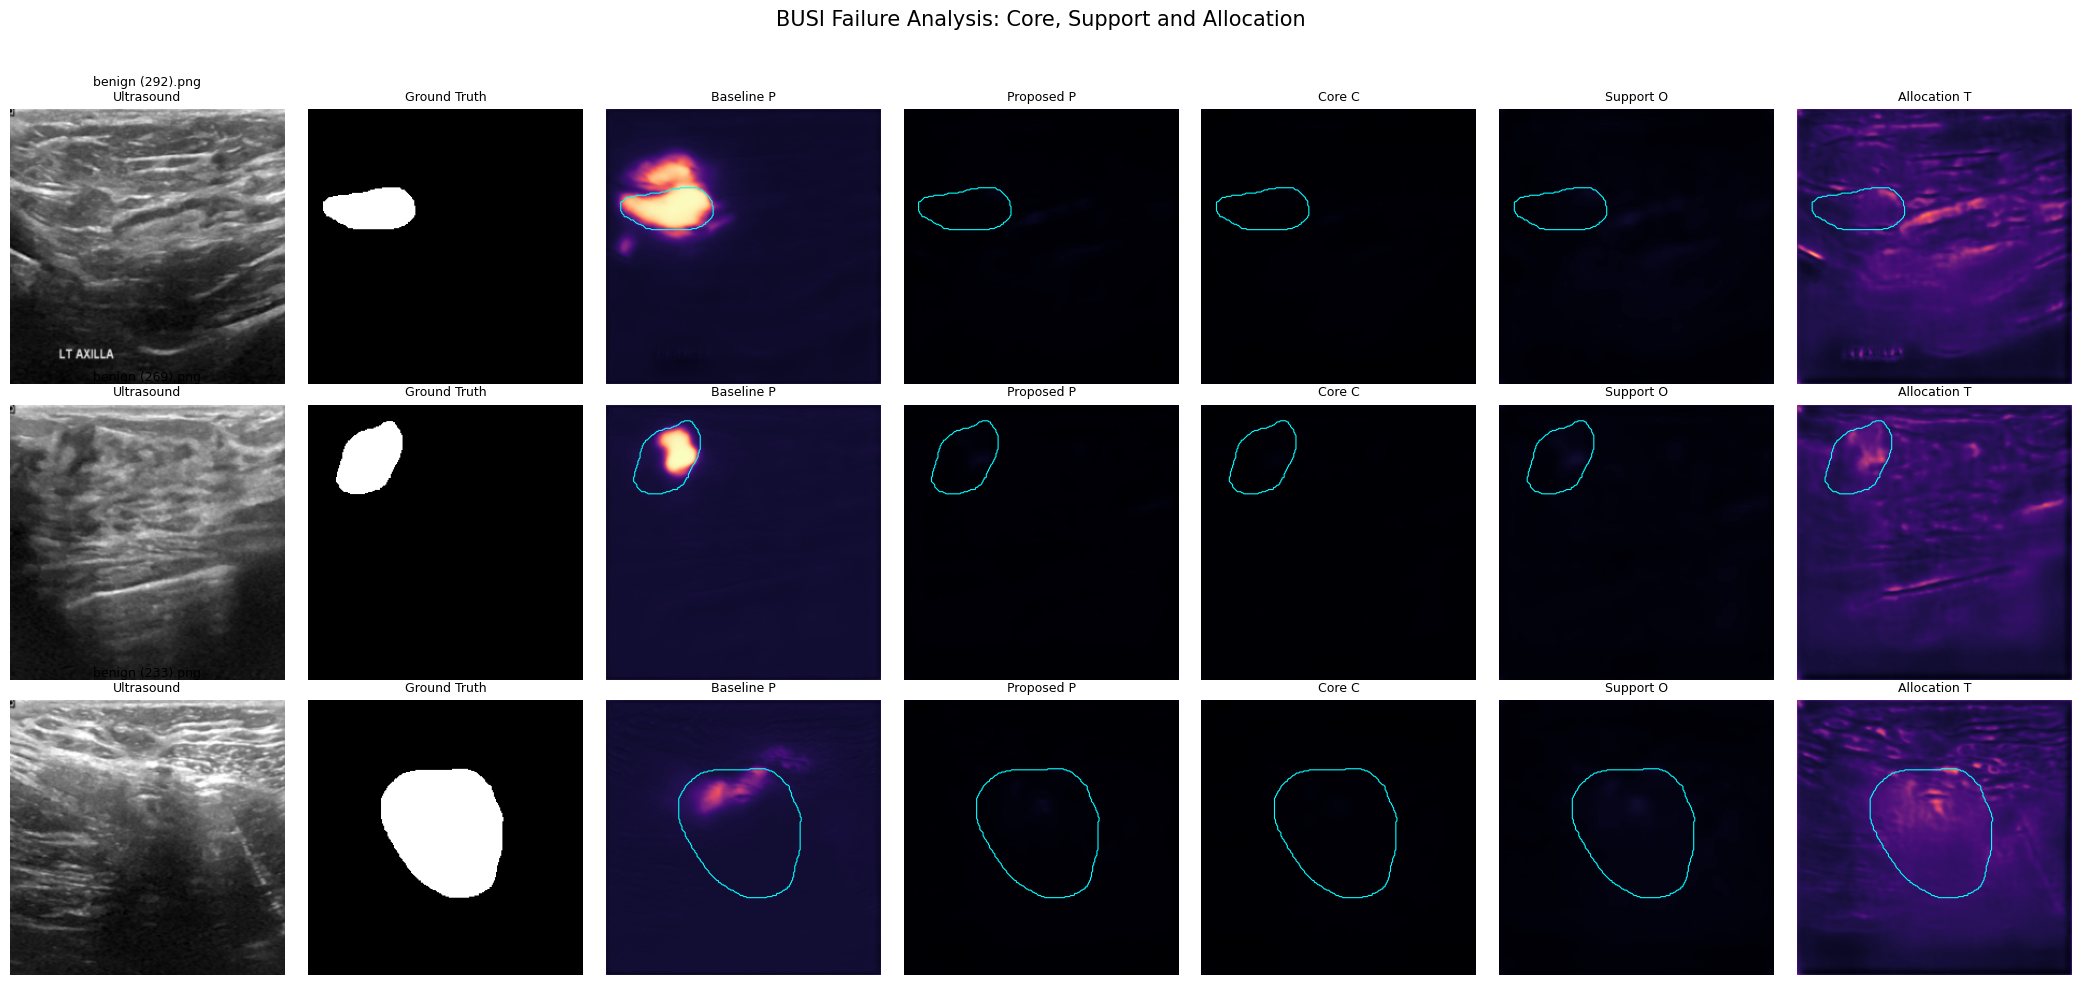


FAILURE DIAGNOSTICS
           image  baseline_max_probability  proposed_max_probability  proposed_max_core  proposed_max_support  proposed_mean_probability_on_lesion  support_coverage_at_0_5
benign (292).png                  0.993948                  0.056898           0.026550              0.080114                             0.011365                      0.0
benign (269).png                  0.999105                  0.060018           0.030126              0.090183                             0.016408                      0.0
benign (233).png                  0.633375                  0.063779           0.027805              0.084131                             0.018151                      0.0

All diagnostic outputs saved in: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z


In [28]:
# ============================================================
# CELL 14: PAIRED COMPARISON AND FAILURE DIAGNOSIS
# Uses existing BUSI validation results and loaded models.
# Does not access the test partition.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from pathlib import Path

RUN_DIR = Path(RUN_DIR)

results = pd.read_csv(
    RUN_DIR / "BUSI_Validation_Per_Image.csv"
)

positive = results[results["gt_pixels"] > 0].copy()

# ------------------------------------------------------------
# 1. PAIRED METRIC COMPARISON
# ------------------------------------------------------------

rng = np.random.default_rng(42)
comparison_rows = []

for metric in ["dice", "iou", "boundary_f1", "hd95_px"]:

    wide = positive.pivot(
        index="sample_index",
        columns="model",
        values=metric
    ).dropna()

    differences = (
        wide["proposed"] - wide["baseline"]
    ).to_numpy()

    if len(differences) == 0:
        continue

    # Image-level descriptive bootstrap.
    boot_means = rng.choice(
        differences,
        size=(5000, len(differences)),
        replace=True
    ).mean(axis=1)

    low, high = np.percentile(boot_means, [2.5, 97.5])

    comparison_rows.append({
        "metric": metric,
        "paired_images": len(differences),
        "mean_difference": differences.mean(),
        "median_difference": np.median(differences),
        "bootstrap_low": low,
        "bootstrap_high": high
    })

paired_summary = pd.DataFrame(comparison_rows)

print("PAIRED VALIDATION COMPARISON")
print(paired_summary.to_string(index=False))

paired_summary.to_csv(
    RUN_DIR / "BUSI_Paired_Metric_Analysis.csv",
    index=False
)

# ------------------------------------------------------------
# 2. ZERO-OVERLAP AND EMPTY-PREDICTION COUNTS
# ------------------------------------------------------------

print("\nLESION-OMISSION ANALYSIS")

for name in ["baseline", "proposed"]:

    subset = positive[positive["model"] == name]

    print(
        name,
        "| Empty predictions:",
        int((subset["pred_pixels"] == 0).sum()),
        "| Zero-overlap predictions:",
        int((subset["tp_pixels"] == 0).sum())
    )

# ------------------------------------------------------------
# 3. CATEGORY-LEVEL DICE COMPARISON
# ------------------------------------------------------------

print("\nDICE DIFFERENCES BY CATEGORY")

for category, group in positive.groupby("category"):

    wide = group.pivot(
        index="sample_index",
        columns="model",
        values="dice"
    ).dropna()

    if wide.empty:
        continue

    difference = wide["proposed"] - wide["baseline"]

    print(
        category,
        "| Images:", len(wide),
        "| Mean difference:", round(difference.mean(), 4),
        "| Improved:", int((difference > 0).sum()),
        "| Worsened:", int((difference < 0).sum())
    )

# ------------------------------------------------------------
# 4. VISUALIZE THE THREE KNOWN FAILURE CASES
# ------------------------------------------------------------

assert "models" in globals(), "Run Cell 12 to load models."
assert "val_dataset" in globals(), "Run Cell 12 first."

case_names = [
    "benign (292).png",
    "benign (269).png",
    "benign (233).png"
]

fig, axes = plt.subplots(
    len(case_names), 7,
    figsize=(21, 10),
    squeeze=False
)

diagnostics = []

for row, filename in enumerate(case_names):

    matches = [
        i for i, source_index
        in enumerate(val_dataset.indices)
        if records[source_index]["image"].name == filename
    ]

    if not matches:
        print("Not found in validation:", filename)
        for ax in axes[row]:
            ax.axis("off")
        continue

    x, y, _, _, _ = val_dataset[matches[0]]

    truth = y[0].numpy() >= 0.5

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    image = np.clip(
        x.permute(1, 2, 0).numpy() * std + mean,
        0, 1
    )

    output_maps = {}

    with torch.inference_mode():

        for name, network in models.items():

            output = network(
                x.unsqueeze(0).to(DEVICE)
            )

            output_maps[name] = {
                key: value[0, 0].float().cpu().numpy()
                for key, value in output.items()
            }

    b = output_maps["baseline"]
    p = output_maps["proposed"]

    panels = [
        ("Ultrasound", image),
        ("Ground Truth", truth.astype(float)),
        ("Baseline P", b["p"]),
        ("Proposed P", p["p"]),
        ("Core C", p["c"]),
        ("Support O", p["o"]),
        ("Allocation T", p["t"])
    ]

    for col, (title, content) in enumerate(panels):

        ax = axes[row, col]

        if col == 0:
            ax.imshow(content)
        else:
            ax.imshow(
                content,
                cmap="gray" if col == 1 else "magma",
                vmin=0, vmax=1
            )

            if col >= 2 and truth.any():
                ax.contour(
                    truth.astype(float),
                    levels=[0.5],
                    colors="cyan",
                    linewidths=0.8
                )

        ax.set_title(
            f"{filename}\n{title}" if col == 0 else title,
            fontsize=9
        )
        ax.axis("off")

    diagnostics.append({
        "image": filename,
        "baseline_max_probability": float(b["p"].max()),
        "proposed_max_probability": float(p["p"].max()),
        "proposed_max_core": float(p["c"].max()),
        "proposed_max_support": float(p["o"].max()),
        "proposed_mean_probability_on_lesion":
            float(p["p"][truth].mean()),
        "support_coverage_at_0_5":
            float((p["o"][truth] >= 0.5).mean())
    })

fig.suptitle(
    "BUSI Failure Analysis: Core, Support and Allocation",
    fontsize=15
)

fig.tight_layout(rect=[0, 0, 1, 0.95])

failure_figure = RUN_DIR / "BUSI_Failure_Diagnostics.png"

fig.savefig(
    failure_figure,
    dpi=250,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

diagnostic_df = pd.DataFrame(diagnostics)

diagnostic_df.to_csv(
    RUN_DIR / "BUSI_Failure_Diagnostics.csv",
    index=False
)

print("\nFAILURE DIAGNOSTICS")
print(diagnostic_df.to_string(index=False))

print("\nAll diagnostic outputs saved in:", RUN_DIR)

In [29]:

# ============================================================
# CELL 15: AUXILIARY MODEL ABLATION EXPERIMENT
# BUSI: Test the effect of removing the nested constraint
# Uses existing training/validation splits.
# Does NOT evaluate the test set.
# ============================================================

import json
import random
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from torch.utils.data import DataLoader

# ------------------------------------------------------------
# 1. DEFINE PARAMETER-MATCHED AUXILIARY MODEL
# ------------------------------------------------------------

class AuxiliaryRegionSeg(RegionSeg):
    """
    Same architecture as the proposed model.

    Difference:
        Proposed: P = C + (O-C)*T
        Auxiliary: P = T

    Core/support predictions and auxiliary losses remain.

    The internal variant stays 'proposed' so that the
    existing combined_loss() and evaluate() functions
    include envelope and band supervision.
    """

    def __init__(self, pretrained=True):
        super().__init__(
            variant="proposed",
            pretrained=pretrained
        )

    def forward(self, x):
        output = super().forward(x)
        output["p"] = output["t"]
        return output


# ------------------------------------------------------------
# 2. CONFIGURATION
# ------------------------------------------------------------

AUX_EPOCHS = 5
AUX_BATCH_SIZE = 8
AUX_SEED = 42

AUX_DIR = Path(RUN_DIR) / "auxiliary_ablation"
AUX_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

USE_AMP = DEVICE.type == "cuda"

random.seed(AUX_SEED)
np.random.seed(AUX_SEED)
torch.manual_seed(AUX_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(AUX_SEED)

model = AuxiliaryRegionSeg(
    pretrained=True
).to(DEVICE)

parameter_count = sum(
    p.numel() for p in model.parameters()
)

print("Auxiliary model parameters:", parameter_count)

# Verify exact architectural parameter matching.
reference = RegionSeg(
    variant="proposed",
    pretrained=False
)

reference_count = sum(
    p.numel() for p in reference.parameters()
)

assert parameter_count == reference_count

del reference

print("Parameter matching: PASSED")

# ------------------------------------------------------------
# 3. DATA LOADERS
# ------------------------------------------------------------

train_dataset_aux = SegDataset(
    records, train, augment=True
)

val_dataset_aux = SegDataset(
    records, val, augment=False
)

generator = torch.Generator().manual_seed(AUX_SEED)

train_loader_aux = DataLoader(
    train_dataset_aux,
    batch_size=AUX_BATCH_SIZE,
    shuffle=True,
    generator=generator,
    num_workers=2,
    pin_memory=USE_AMP
)

val_loader_aux = DataLoader(
    val_dataset_aux,
    batch_size=AUX_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=USE_AMP
)

# ------------------------------------------------------------
# 4. OPTIMIZER AND AMP
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

config = {
    "model": "auxiliary",
    "dataset": DATASET,
    "epochs": AUX_EPOCHS,
    "batch_size": AUX_BATCH_SIZE,
    "seed": AUX_SEED,
    "learning_rate": 3e-4,
    "weight_decay": 1e-4,
    "parameters": parameter_count,
    "prediction": "P=T (unconstrained)",
    "envelope_loss_weight": 0.30,
    "band_loss_weight": 0.25,
    "test_set_used": False
}

(AUX_DIR / "config.json").write_text(
    json.dumps(config, indent=2)
)

# ------------------------------------------------------------
# 5. TRAINING
# ------------------------------------------------------------

history_aux = []
best_dice = -float("inf")

checkpoint_path = AUX_DIR / "auxiliary_best.pt"

print("\nTRAINING AUXILIARY MODEL")
print("=" * 60)

for epoch in range(1, AUX_EPOCHS + 1):

    model.train()
    total_loss = 0.0

    for batch in train_loader_aux:

        batch = tuple(
            tensor.to(DEVICE)
            for tensor in batch
        )

        optimizer.zero_grad(set_to_none=True)

        # Mixed precision only for model forward pass.
        with torch.autocast(
            device_type=DEVICE.type,
            enabled=USE_AMP
        ):
            output = model(batch[0])

        # Float32 loss computation outside autocast.
        output = {
            key: value.float()
            for key, value in output.items()
        }

        # Keep all original auxiliary loss terms.
        loss = combined_loss(
            output, batch, "proposed"
        )

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss at epoch {epoch}"
            )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += (
            loss.detach().item() * batch[0].size(0)
        )

    train_loss = total_loss / len(train_dataset_aux)

    metrics = evaluate(model, val_loader_aux)

    row = {
        "model": "auxiliary",
        "epoch": epoch,
        "train_loss": train_loss,
        **metrics
    }

    history_aux.append(row)

    pd.DataFrame(history_aux).to_csv(
        AUX_DIR / "auxiliary_history.csv",
        index=False
    )

    current_dice = float(metrics["val_dice"])

    if np.isfinite(current_dice) and current_dice > best_dice:

        best_dice = current_dice

        torch.save({
            "model": "auxiliary",
            "epoch": epoch,
            "state_dict": model.state_dict(),
            "best_val_dice": best_dice,
            "config": config
        }, checkpoint_path)

    print(
        f"Epoch {epoch}/{AUX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Dice: {metrics['val_dice']:.4f} | "
        f"Val IoU: {metrics['val_iou']:.4f} | "
        f"Empty FP: {metrics['empty_fp_rate']:.4f}"
    )

if not checkpoint_path.exists():
    raise RuntimeError("No valid auxiliary checkpoint saved.")

# ------------------------------------------------------------
# 6. RELOAD BEST MODEL
# ------------------------------------------------------------

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(checkpoint["state_dict"])
model.eval()

print("\nBest auxiliary validation Dice:", best_dice)

# ------------------------------------------------------------
# 7. PER-IMAGE VALIDATION EVALUATION
# ------------------------------------------------------------

aux_rows = []

for i in range(len(val_dataset_aux)):

    x, y, _, _, _ = val_dataset_aux[i]

    truth = y[0].numpy() >= 0.5

    with torch.inference_mode():

        output = model(
            x.unsqueeze(0).to(DEVICE)
        )

    probability = (
        output["p"][0, 0]
        .float().cpu().numpy()
    )

    pred = probability >= 0.5

    tp = int(np.logical_and(pred, truth).sum())
    fp = int(np.logical_and(pred, ~truth).sum())
    fn = int(np.logical_and(~pred, truth).sum())

    dice = (
        2 * tp / max(1, 2 * tp + fp + fn)
        if truth.any() else np.nan
    )

    source_index = val_dataset_aux.indices[i]

    aux_rows.append({
        "sample_index": i,
        "image": records[source_index]["image"].name,
        "category": records[source_index]["label"],
        "gt_pixels": int(truth.sum()),
        "pred_pixels": int(pred.sum()),
        "dice": dice,
        "zero_overlap": int(truth.any() and tp == 0),
        "max_probability": float(probability.max())
    })

aux_results = pd.DataFrame(aux_rows)

aux_results.to_csv(
    AUX_DIR / "auxiliary_per_image.csv",
    index=False
)

# ------------------------------------------------------------
# 8. COMPARE ALL THREE MODELS
# ------------------------------------------------------------

original_path = (
    Path(RUN_DIR) / "BUSI_Validation_Per_Image.csv"
)

if original_path.exists():

    previous = pd.read_csv(original_path)

    previous_positive = previous[
        previous["gt_pixels"] > 0
    ]

    wide = previous_positive.pivot(
        index="sample_index",
        columns="model",
        values="dice"
    )

    aux_positive = aux_results[
        aux_results["gt_pixels"] > 0
    ].set_index("sample_index")

    wide["auxiliary"] = aux_positive["dice"]

    print("\nTHREE-MODEL VALIDATION COMPARISON")
    print("=" * 60)

    print(wide.mean().to_string())

    print("\nPAIRED MEAN DICE DIFFERENCES")

    print(
        "Auxiliary - Proposed:",
        round(
            (wide["auxiliary"] - wide["proposed"]).mean(),
            4
        )
    )

    print(
        "Auxiliary - Baseline:",
        round(
            (wide["auxiliary"] - wide["baseline"]).mean(),
            4
        )
    )

    print("\nKNOWN FAILURE CASES")

    failure_names = [
        "benign (292).png",
        "benign (269).png",
        "benign (233).png"
    ]

    print(
        aux_results[
            aux_results["image"].isin(failure_names)
        ][
            [
                "image",
                "dice",
                "pred_pixels",
                "max_probability"
            ]
        ].to_string(index=False)
    )

    wide.to_csv(
        AUX_DIR / "three_model_paired_dice.csv"
    )

print("\nAuxiliary experiment completed.")
print("Results saved in:", AUX_DIR)


Auxiliary model parameters: 12702213
Parameter matching: PASSED

TRAINING AUXILIARY MODEL
Epoch 1/5 | Train Loss: 1.6794 | Val Dice: 0.6559 | Val IoU: 0.5582 | Empty FP: 0.3500
Epoch 2/5 | Train Loss: 1.4467 | Val Dice: 0.6011 | Val IoU: 0.4679 | Empty FP: 1.0000
Epoch 3/5 | Train Loss: 1.3241 | Val Dice: 0.6465 | Val IoU: 0.5270 | Empty FP: 0.7500
Epoch 4/5 | Train Loss: 1.2265 | Val Dice: 0.6982 | Val IoU: 0.5999 | Empty FP: 0.9000
Epoch 5/5 | Train Loss: 1.1251 | Val Dice: 0.6759 | Val IoU: 0.5628 | Empty FP: 0.9000

Best auxiliary validation Dice: 0.6982324150537702

THREE-MODEL VALIDATION COMPARISON
model
baseline     0.690580
proposed     0.712586
auxiliary    0.698233

PAIRED MEAN DICE DIFFERENCES
Auxiliary - Proposed: -0.0144
Auxiliary - Baseline: 0.0077

KNOWN FAILURE CASES
           image     dice  pred_pixels  max_probability
benign (269).png 0.451411         8224         0.958063
benign (292).png 0.160332         4582         0.908357
benign (233).png 0.000000            0

Image alignment verified.
Total model predictions: 351

THREE-MODEL VALIDATION SUMMARY
    model  mean_dice  mean_iou  empty_predictions_on_lesions  zero_overlap_lesions  normal_fp_rate  normal_mean_fp_pixels
 baseline   0.690580  0.583738                             3                     5            0.60                1226.00
auxiliary   0.698233  0.599942                             1                     5            0.90                4605.45
 proposed   0.712586  0.602044                             3                     6            0.35                 521.10

PAIRED DICE ANALYSIS
          comparison  mean_difference  median_difference  improved  worsened  ties  bootstrap_low  bootstrap_high
 proposed - baseline         0.022006           0.000635        49        46     2      -0.012722        0.058425
proposed - auxiliary         0.014353          -0.012891        36        57     4      -0.020825        0.051462
auxiliary - baseline         0.007653           0.010246     

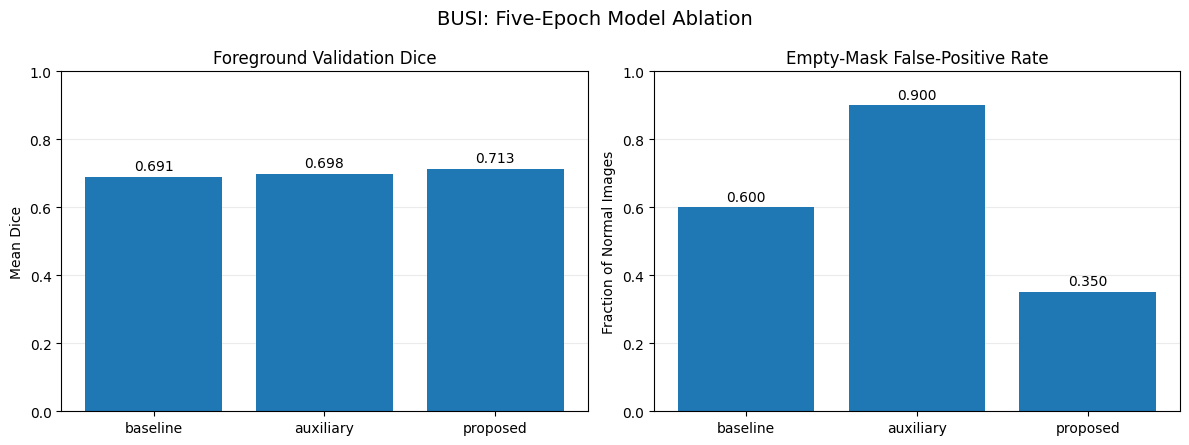


Cell 16 completed successfully.
Results saved to: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z


In [30]:

# ============================================================
# CELL 16: THREE-MODEL ABLATION ANALYSIS
# BUSI | 5 Epochs | Validation only
# No training and no test-set evaluation
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RUN_DIR = Path(RUN_DIR)

# ------------------------------------------------------------
# 1. LOAD SAVED PER-IMAGE RESULTS
# ------------------------------------------------------------

main_path = RUN_DIR / "BUSI_Validation_Per_Image.csv"

aux_path = (
    RUN_DIR / "auxiliary_ablation"
    / "auxiliary_per_image.csv"
)

main = pd.read_csv(main_path)
aux = pd.read_csv(aux_path)

main = main[
    main["model"].isin(["baseline", "proposed"])
].copy()

aux = aux.copy()
aux["model"] = "auxiliary"

required = [
    "sample_index",
    "image",
    "category",
    "gt_pixels",
    "pred_pixels",
    "dice",
    "model"
]

# Verify that comparisons refer to the same images.
reference = (
    main[main["model"] == "baseline"][
        ["sample_index", "image", "gt_pixels"]
    ]
)

check = reference.merge(
    aux[["sample_index", "image", "gt_pixels"]],
    on="sample_index",
    suffixes=("_reference", "_aux"),
    validate="one_to_one"
)

assert len(check) == len(reference) == len(aux)

assert (
    check["image_reference"] == check["image_aux"]
).all(), "Image identity mismatch"

assert (
    check["gt_pixels_reference"]
    == check["gt_pixels_aux"]
).all(), "Ground-truth mismatch"

all_results = pd.concat(
    [main[required], aux[required]],
    ignore_index=True
)

assert not all_results.duplicated(
    ["model", "sample_index"]
).any()

print("Image alignment verified.")
print("Total model predictions:", len(all_results))

# ------------------------------------------------------------
# 2. FULL MODEL SUMMARY
# ------------------------------------------------------------

summary_rows = []

for model_name in [
    "baseline",
    "auxiliary",
    "proposed"
]:

    subset = all_results[
        all_results["model"] == model_name
    ]

    lesion = subset[subset["gt_pixels"] > 0]
    normal = subset[subset["gt_pixels"] == 0]

    # Per-image Dice-to-IoU relationship.
    dice_values = lesion["dice"].to_numpy()
    iou_values = dice_values / (2.0 - dice_values)

    summary_rows.append({
        "model": model_name,
        "mean_dice": lesion["dice"].mean(),
        "mean_iou": np.nanmean(iou_values),
        "empty_predictions_on_lesions": int(
            (lesion["pred_pixels"] == 0).sum()
        ),
        "zero_overlap_lesions": int(
            (lesion["dice"] == 0).sum()
        ),
        "normal_fp_rate": float(
            (normal["pred_pixels"] > 0).mean()
        ),
        "normal_mean_fp_pixels": float(
            normal["pred_pixels"].mean()
        )
    })

summary = pd.DataFrame(summary_rows)

print("\nTHREE-MODEL VALIDATION SUMMARY")
print(summary.to_string(index=False))

summary.to_csv(
    RUN_DIR / "BUSI_Three_Model_Summary.csv",
    index=False
)

# ------------------------------------------------------------
# 3. PAIRED DICE COMPARISONS
# ------------------------------------------------------------

wide = (
    all_results[all_results["gt_pixels"] > 0]
    .pivot(
        index="sample_index",
        columns="model",
        values="dice"
    )
    .dropna()
)

rng = np.random.default_rng(42)

comparisons = [
    ("proposed", "baseline"),
    ("proposed", "auxiliary"),
    ("auxiliary", "baseline")
]

paired_rows = []

for first, second in comparisons:

    differences = (
        wide[first] - wide[second]
    ).to_numpy()

    indices = rng.integers(
        0,
        len(differences),
        size=(5000, len(differences))
    )

    bootstrap = differences[indices].mean(axis=1)
    low, high = np.percentile(bootstrap, [2.5, 97.5])

    paired_rows.append({
        "comparison": f"{first} - {second}",
        "mean_difference": differences.mean(),
        "median_difference": np.median(differences),
        "improved": int((differences > 0).sum()),
        "worsened": int((differences < 0).sum()),
        "ties": int((differences == 0).sum()),
        "bootstrap_low": low,
        "bootstrap_high": high
    })

paired_df = pd.DataFrame(paired_rows)

print("\nPAIRED DICE ANALYSIS")
print(paired_df.to_string(index=False))

paired_df.to_csv(
    RUN_DIR / "BUSI_Three_Model_Paired_Analysis.csv",
    index=False
)

# ------------------------------------------------------------
# 4. CHECK THE THREE FAILURE IMAGES
# ------------------------------------------------------------

failure_names = [
    "benign (269).png",
    "benign (292).png",
    "benign (233).png"
]

failures = all_results[
    all_results["image"].isin(failure_names)
]

print("\nFAILURE CASES")

print(
    failures.pivot(
        index="image",
        columns="model",
        values="dice"
    ).to_string()
)

# ------------------------------------------------------------
# 5. PUBLICATION-STYLE COMPARISON GRAPHS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.5)
)

labels = summary["model"].tolist()

axes[0].bar(
    labels,
    summary["mean_dice"]
)

axes[0].set_title("Foreground Validation Dice")
axes[0].set_ylabel("Mean Dice")
axes[0].set_ylim(0, 1)

axes[1].bar(
    labels,
    summary["normal_fp_rate"]
)

axes[1].set_title("Empty-Mask False-Positive Rate")
axes[1].set_ylabel("Fraction of Normal Images")
axes[1].set_ylim(0, 1)

for ax, column in zip(
    axes,
    ["mean_dice", "normal_fp_rate"]
):

    for i, value in enumerate(summary[column]):
        ax.text(
            i,
            min(float(value) + 0.02, 0.97),
            f"{value:.3f}",
            ha="center"
        )

    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle(
    "BUSI: Five-Epoch Model Ablation",
    fontsize=14
)

fig.tight_layout()

figure_path = (
    RUN_DIR / "BUSI_Three_Model_Comparison.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("\nCell 16 completed successfully.")
print("Results saved to:", RUN_DIR)



Evaluating: baseline

Evaluating: proposed

Evaluating: auxiliary

THRESHOLD = 0.50 RESULTS
    model  threshold  mean_dice  mean_iou  zero_overlap_count  empty_lesion_predictions  normal_fp_rate  mean_normal_fp_pixels
auxiliary        0.5   0.698232  0.599942                   5                         1            0.90                4605.45
 baseline        0.5   0.690580  0.583738                   5                         3            0.60                1226.00
 proposed        0.5   0.712586  0.602044                   6                         3            0.35                 521.10


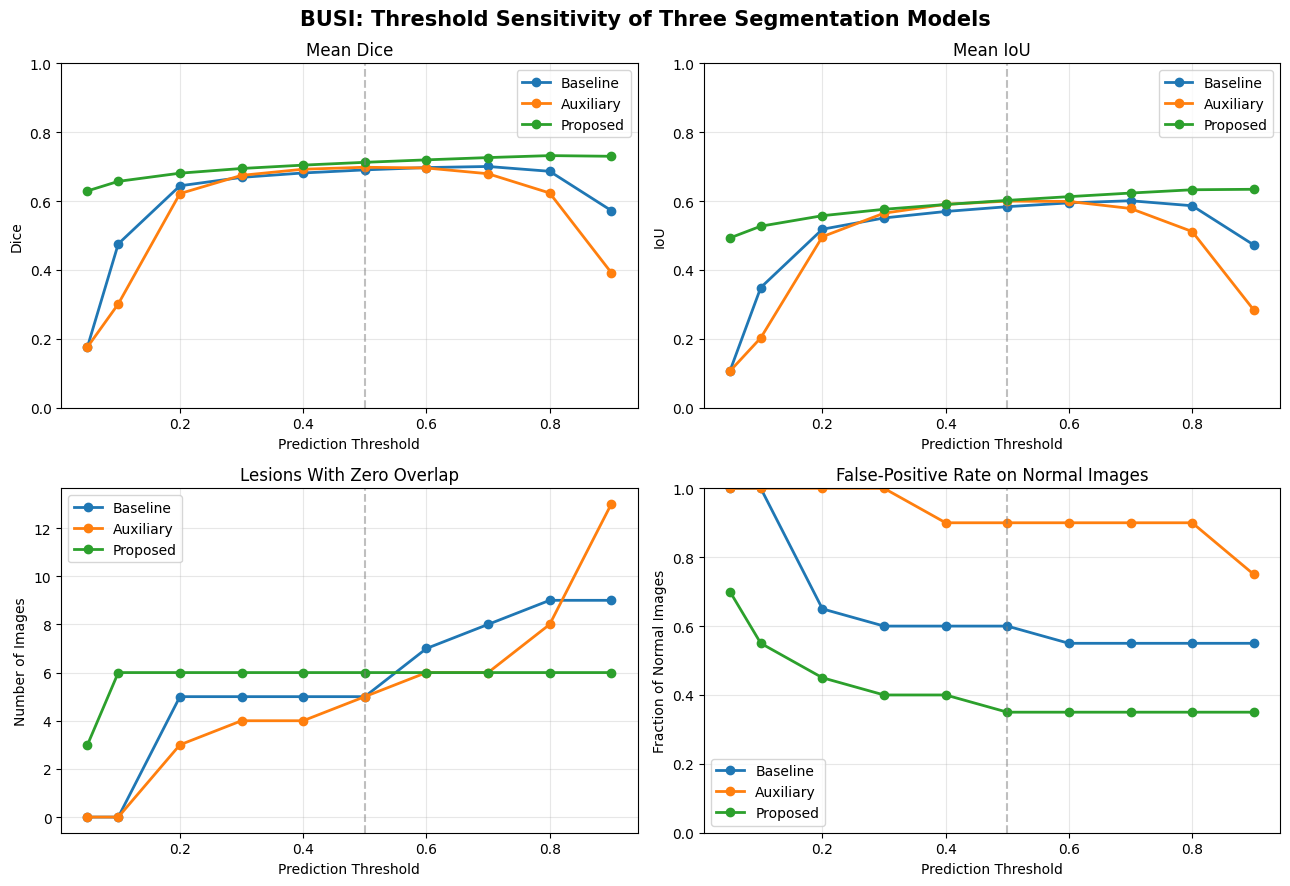


KNOWN FAILURE CASES ACROSS THRESHOLDS
model                       auxiliary  baseline  proposed
image            threshold                               
benign (233).png 0.05        0.282239  0.282239  0.012000
                 0.10        0.389900  0.352659  0.000000
                 0.50        0.000000  0.030364  0.000000
benign (269).png 0.05        0.086786  0.086764  0.034392
                 0.10        0.211681  0.471701  0.000000
                 0.50        0.451411  0.537042  0.000000
benign (292).png 0.05        0.077873  0.077813  0.000000
                 0.10        0.177411  0.342743  0.000000
                 0.50        0.160332  0.733333  0.000000

CELL 17 COMPLETED
Per-image CSV: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z/BUSI_Threshold_Per_Image.csv
Summary CSV: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014T182826Z/BUSI_Threshold_Summary.csv
Graph: /content/Medical_Lesion_Segmentation_Research/busi_pilot_20261014

In [31]:

# ============================================================
# CELL 17: THREE-MODEL THRESHOLD SENSITIVITY ANALYSIS
# Dataset: BUSI
# Models: Baseline, Auxiliary, Proposed
# Validation only - NO retraining
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from pathlib import Path
from torch.utils.data import DataLoader

RUN_DIR = Path(RUN_DIR)

THRESHOLDS = [
    0.05, 0.10, 0.20, 0.30, 0.40,
    0.50, 0.60, 0.70, 0.80, 0.90
]

# ------------------------------------------------------------
# 1. LOAD VALIDATION DATA
# ------------------------------------------------------------

validation_data = SegDataset(
    records, val, augment=False
)

loader = DataLoader(
    validation_data,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

# ------------------------------------------------------------
# 2. REGISTER SAVED MODEL CHECKPOINTS
# ------------------------------------------------------------

model_configs = {
    "baseline": (
        RegionSeg(variant="baseline", pretrained=False),
        RUN_DIR / "checkpoints" / "baseline_best.pt"
    ),
    "proposed": (
        RegionSeg(variant="proposed", pretrained=False),
        RUN_DIR / "checkpoints" / "proposed_best.pt"
    ),
    "auxiliary": (
        AuxiliaryRegionSeg(pretrained=False),
        RUN_DIR / "auxiliary_ablation" / "auxiliary_best.pt"
    )
}

all_rows = []

# ------------------------------------------------------------
# 3. EVALUATE EVERY THRESHOLD
# ------------------------------------------------------------

for model_name, (network, checkpoint_path) in model_configs.items():

    print("\nEvaluating:", model_name)

    if not checkpoint_path.exists():
        raise FileNotFoundError(checkpoint_path)

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    network.load_state_dict(checkpoint["state_dict"])
    network = network.to(DEVICE)
    network.eval()

    position = 0

    with torch.inference_mode():

        for batch in loader:

            images = batch[0].to(DEVICE)

            truth = (
                batch[1][:, 0].numpy() >= 0.5
            )

            output = network(images)

            probabilities = (
                output["p"][:, 0]
                .float()
                .cpu()
                .numpy()
            )

            batch_size = len(images)

            for threshold in THRESHOLDS:

                predicted = probabilities >= threshold

                tp = np.logical_and(
                    predicted, truth
                ).sum(axis=(1, 2))

                fp = np.logical_and(
                    predicted, ~truth
                ).sum(axis=(1, 2))

                fn = np.logical_and(
                    ~predicted, truth
                ).sum(axis=(1, 2))

                for j in range(batch_size):

                    sample_index = position + j

                    record_index = validation_data.indices[
                        sample_index
                    ]

                    record = records[record_index]

                    gt_pixels = int(truth[j].sum())
                    pred_pixels = int(predicted[j].sum())

                    if gt_pixels > 0:

                        dice = (
                            2 * tp[j] /
                            max(1, 2 * tp[j] + fp[j] + fn[j])
                        )

                        iou = (
                            tp[j] /
                            max(1, tp[j] + fp[j] + fn[j])
                        )

                        zero_overlap = int(tp[j] == 0)
                        empty_prediction = int(pred_pixels == 0)

                    else:

                        dice = np.nan
                        iou = np.nan
                        zero_overlap = 0
                        empty_prediction = 0

                    all_rows.append({
                        "model": model_name,
                        "threshold": threshold,
                        "sample_index": sample_index,
                        "image": record["image"].name,
                        "category": record["label"],
                        "gt_pixels": gt_pixels,
                        "pred_pixels": pred_pixels,
                        "dice": dice,
                        "iou": iou,
                        "zero_overlap": zero_overlap,
                        "empty_prediction": empty_prediction,
                        "fp_pixels": int(fp[j])
                    })

            position += batch_size

    network = network.cpu()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ------------------------------------------------------------
# 4. SAVE PER-IMAGE THRESHOLD RESULTS
# ------------------------------------------------------------

results = pd.DataFrame(all_rows)

results_path = (
    RUN_DIR / "BUSI_Threshold_Per_Image.csv"
)

results.to_csv(results_path, index=False)

# ------------------------------------------------------------
# 5. SUMMARIZE EACH MODEL AND THRESHOLD
# ------------------------------------------------------------

summary_rows = []

for (model_name, threshold), group in results.groupby(
    ["model", "threshold"]
):

    lesion = group[group["gt_pixels"] > 0]
    normal = group[group["gt_pixels"] == 0]

    summary_rows.append({
        "model": model_name,
        "threshold": threshold,
        "mean_dice": lesion["dice"].mean(),
        "mean_iou": lesion["iou"].mean(),
        "zero_overlap_count": int(
            lesion["zero_overlap"].sum()
        ),
        "empty_lesion_predictions": int(
            lesion["empty_prediction"].sum()
        ),
        "normal_fp_rate": float(
            (normal["pred_pixels"] > 0).mean()
        ) if len(normal) else np.nan,
        "mean_normal_fp_pixels": (
            normal["fp_pixels"].mean()
            if len(normal) else np.nan
        )
    })

summary = pd.DataFrame(summary_rows)

summary_path = (
    RUN_DIR / "BUSI_Threshold_Summary.csv"
)

summary.to_csv(summary_path, index=False)

print("\nTHRESHOLD = 0.50 RESULTS")
print(
    summary[
        np.isclose(summary["threshold"], 0.50)
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 6. GENERATE COMPARISON FIGURES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9)
)

graph_info = [
    ("mean_dice", "Mean Dice", "Dice"),
    ("mean_iou", "Mean IoU", "IoU"),
    (
        "zero_overlap_count",
        "Lesions With Zero Overlap",
        "Number of Images"
    ),
    (
        "normal_fp_rate",
        "False-Positive Rate on Normal Images",
        "Fraction of Normal Images"
    )
]

for ax, (column, title, ylabel) in zip(
    axes.flatten(), graph_info
):

    for model_name in [
        "baseline", "auxiliary", "proposed"
    ]:

        subset = summary[
            summary["model"] == model_name
        ].sort_values("threshold")

        ax.plot(
            subset["threshold"],
            subset[column],
            marker="o",
            linewidth=2,
            label=model_name.capitalize()
        )

    ax.axvline(
        0.50,
        linestyle="--",
        alpha=0.5,
        color="gray"
    )

    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Prediction Threshold")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.legend()

    if column in [
        "mean_dice", "mean_iou", "normal_fp_rate"
    ]:
        ax.set_ylim(0, 1)

fig.suptitle(
    "BUSI: Threshold Sensitivity of Three Segmentation Models",
    fontsize=15,
    fontweight="bold"
)

fig.tight_layout()

figure_path = (
    RUN_DIR / "BUSI_Threshold_Analysis.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 7. INSPECT THREE KNOWN FAILURE CASES
# ------------------------------------------------------------

failure_names = [
    "benign (233).png",
    "benign (269).png",
    "benign (292).png"
]

failure_results = results[
    results["image"].isin(failure_names)
    & results["threshold"].isin([0.05, 0.10, 0.50])
]

print("\nKNOWN FAILURE CASES ACROSS THRESHOLDS")

print(
    failure_results.pivot_table(
        index=["image", "threshold"],
        columns="model",
        values="dice"
    ).to_string()
)

print("\nCELL 17 COMPLETED")
print("Per-image CSV:", results_path)
print("Summary CSV:", summary_path)
print("Graph:", figure_path)


In [32]:
# ============================================================
# CELL 18: THRESHOLD TRADE-OFF ANALYSIS
# Uses existing Cell 17 results.
# No retraining; no test-set access.
# ============================================================

import pandas as pd
from pathlib import Path

RUN_DIR = Path(RUN_DIR)

df = pd.read_csv(
    RUN_DIR / "BUSI_Threshold_Summary.csv"
)

FP_LIMIT = 0.35

selected_rows = []

for model_name in ["baseline", "auxiliary", "proposed"]:

    subset = df[
        df["model"] == model_name
    ].sort_values("threshold")

    print("\n" + "=" * 60)
    print("MODEL:", model_name.upper())
    print("=" * 60)

    print(
        subset[
            [
                "threshold",
                "mean_dice",
                "mean_iou",
                "zero_overlap_count",
                "normal_fp_rate",
                "mean_normal_fp_pixels"
            ]
        ].round(4).to_string(index=False)
    )

    # Restrict threshold selection by normal-image FP rate.
    eligible = subset[
        subset["normal_fp_rate"] <= FP_LIMIT
    ].copy()

    if eligible.empty:

        print(
            f"\nNo threshold satisfies "
            f"normal FP rate <= {FP_LIMIT:.2f}"
        )

        continue

    best = eligible.sort_values(
        ["mean_dice", "zero_overlap_count"],
        ascending=[False, True]
    ).iloc[0]

    selected_rows.append({
        "model": model_name,
        "threshold": best["threshold"],
        "validation_dice": best["mean_dice"],
        "validation_iou": best["mean_iou"],
        "zero_overlap_count": best["zero_overlap_count"],
        "normal_fp_rate": best["normal_fp_rate"]
    })

comparison = pd.DataFrame(selected_rows)

print("\n" + "=" * 60)
print("THRESHOLDS SATISFYING THE FP CONSTRAINT")
print("=" * 60)

if not comparison.empty:
    print(comparison.to_string(index=False))

    comparison.to_csv(
        RUN_DIR / "BUSI_Constrained_Threshold_Analysis.csv",
        index=False
    )

print("\nCell 18 completed.")


MODEL: BASELINE
 threshold  mean_dice  mean_iou  zero_overlap_count  normal_fp_rate  mean_normal_fp_pixels
      0.05     0.1768    0.1069                   0            1.00               65535.90
      0.10     0.4758    0.3490                   0            1.00               29095.45
      0.20     0.6443    0.5183                   5            0.65                1833.30
      0.30     0.6689    0.5510                   5            0.60                1505.40
      0.40     0.6817    0.5698                   5            0.60                1346.90
      0.50     0.6906    0.5837                   5            0.60                1226.00
      0.60     0.6974    0.5948                   7            0.55                1106.65
      0.70     0.7005    0.6010                   8            0.55                 981.20
      0.80     0.6865    0.5865                   9            0.55                 828.35
      0.90     0.5724    0.4725                   9            0.55      

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

15-EPOCH BUSI EXPERIMENT
Models: ('baseline', 'auxiliary', 'proposed')
Device: cuda
GPU: Tesla T4
Epochs per model: 15
Training images: 546
Validation images: 117
Local results: /content/Medical_Lesion_Segmentation_Research/extended_runs/busi_15ep_20261014T193459Z_8492e471
Google Drive: /content/drive/MyDrive/Medical_Lesion_Segmentation_Research/extended_runs/busi_15ep_20261014T193459Z_8492e471

TRAINING: BASELINE
Parameters: 12,702,081
 baseline | Epoch 01/15 | Train Loss: 1.2358 | Val Dice: 0.5891 | Val IoU: 0.4632 | Normal FP: 1.00 | Zero-overlap: 4 | Time: 14.2s | Drive backup complete
 baseline | Epoch 02/15 | Train Loss: 1.0436 | Val Dice: 0.5747 | Val IoU: 0.4495 | Normal FP: 1.00 | Zero-overlap: 6 | Time: 15.2s | Drive backup complete
 baseline | Epoch 03/15 | Train Loss: 0.9520 | Val Dice: 0.6752 | Val IoU: 0.5716 | Normal FP: 0.15 | Zero-overlap: 7

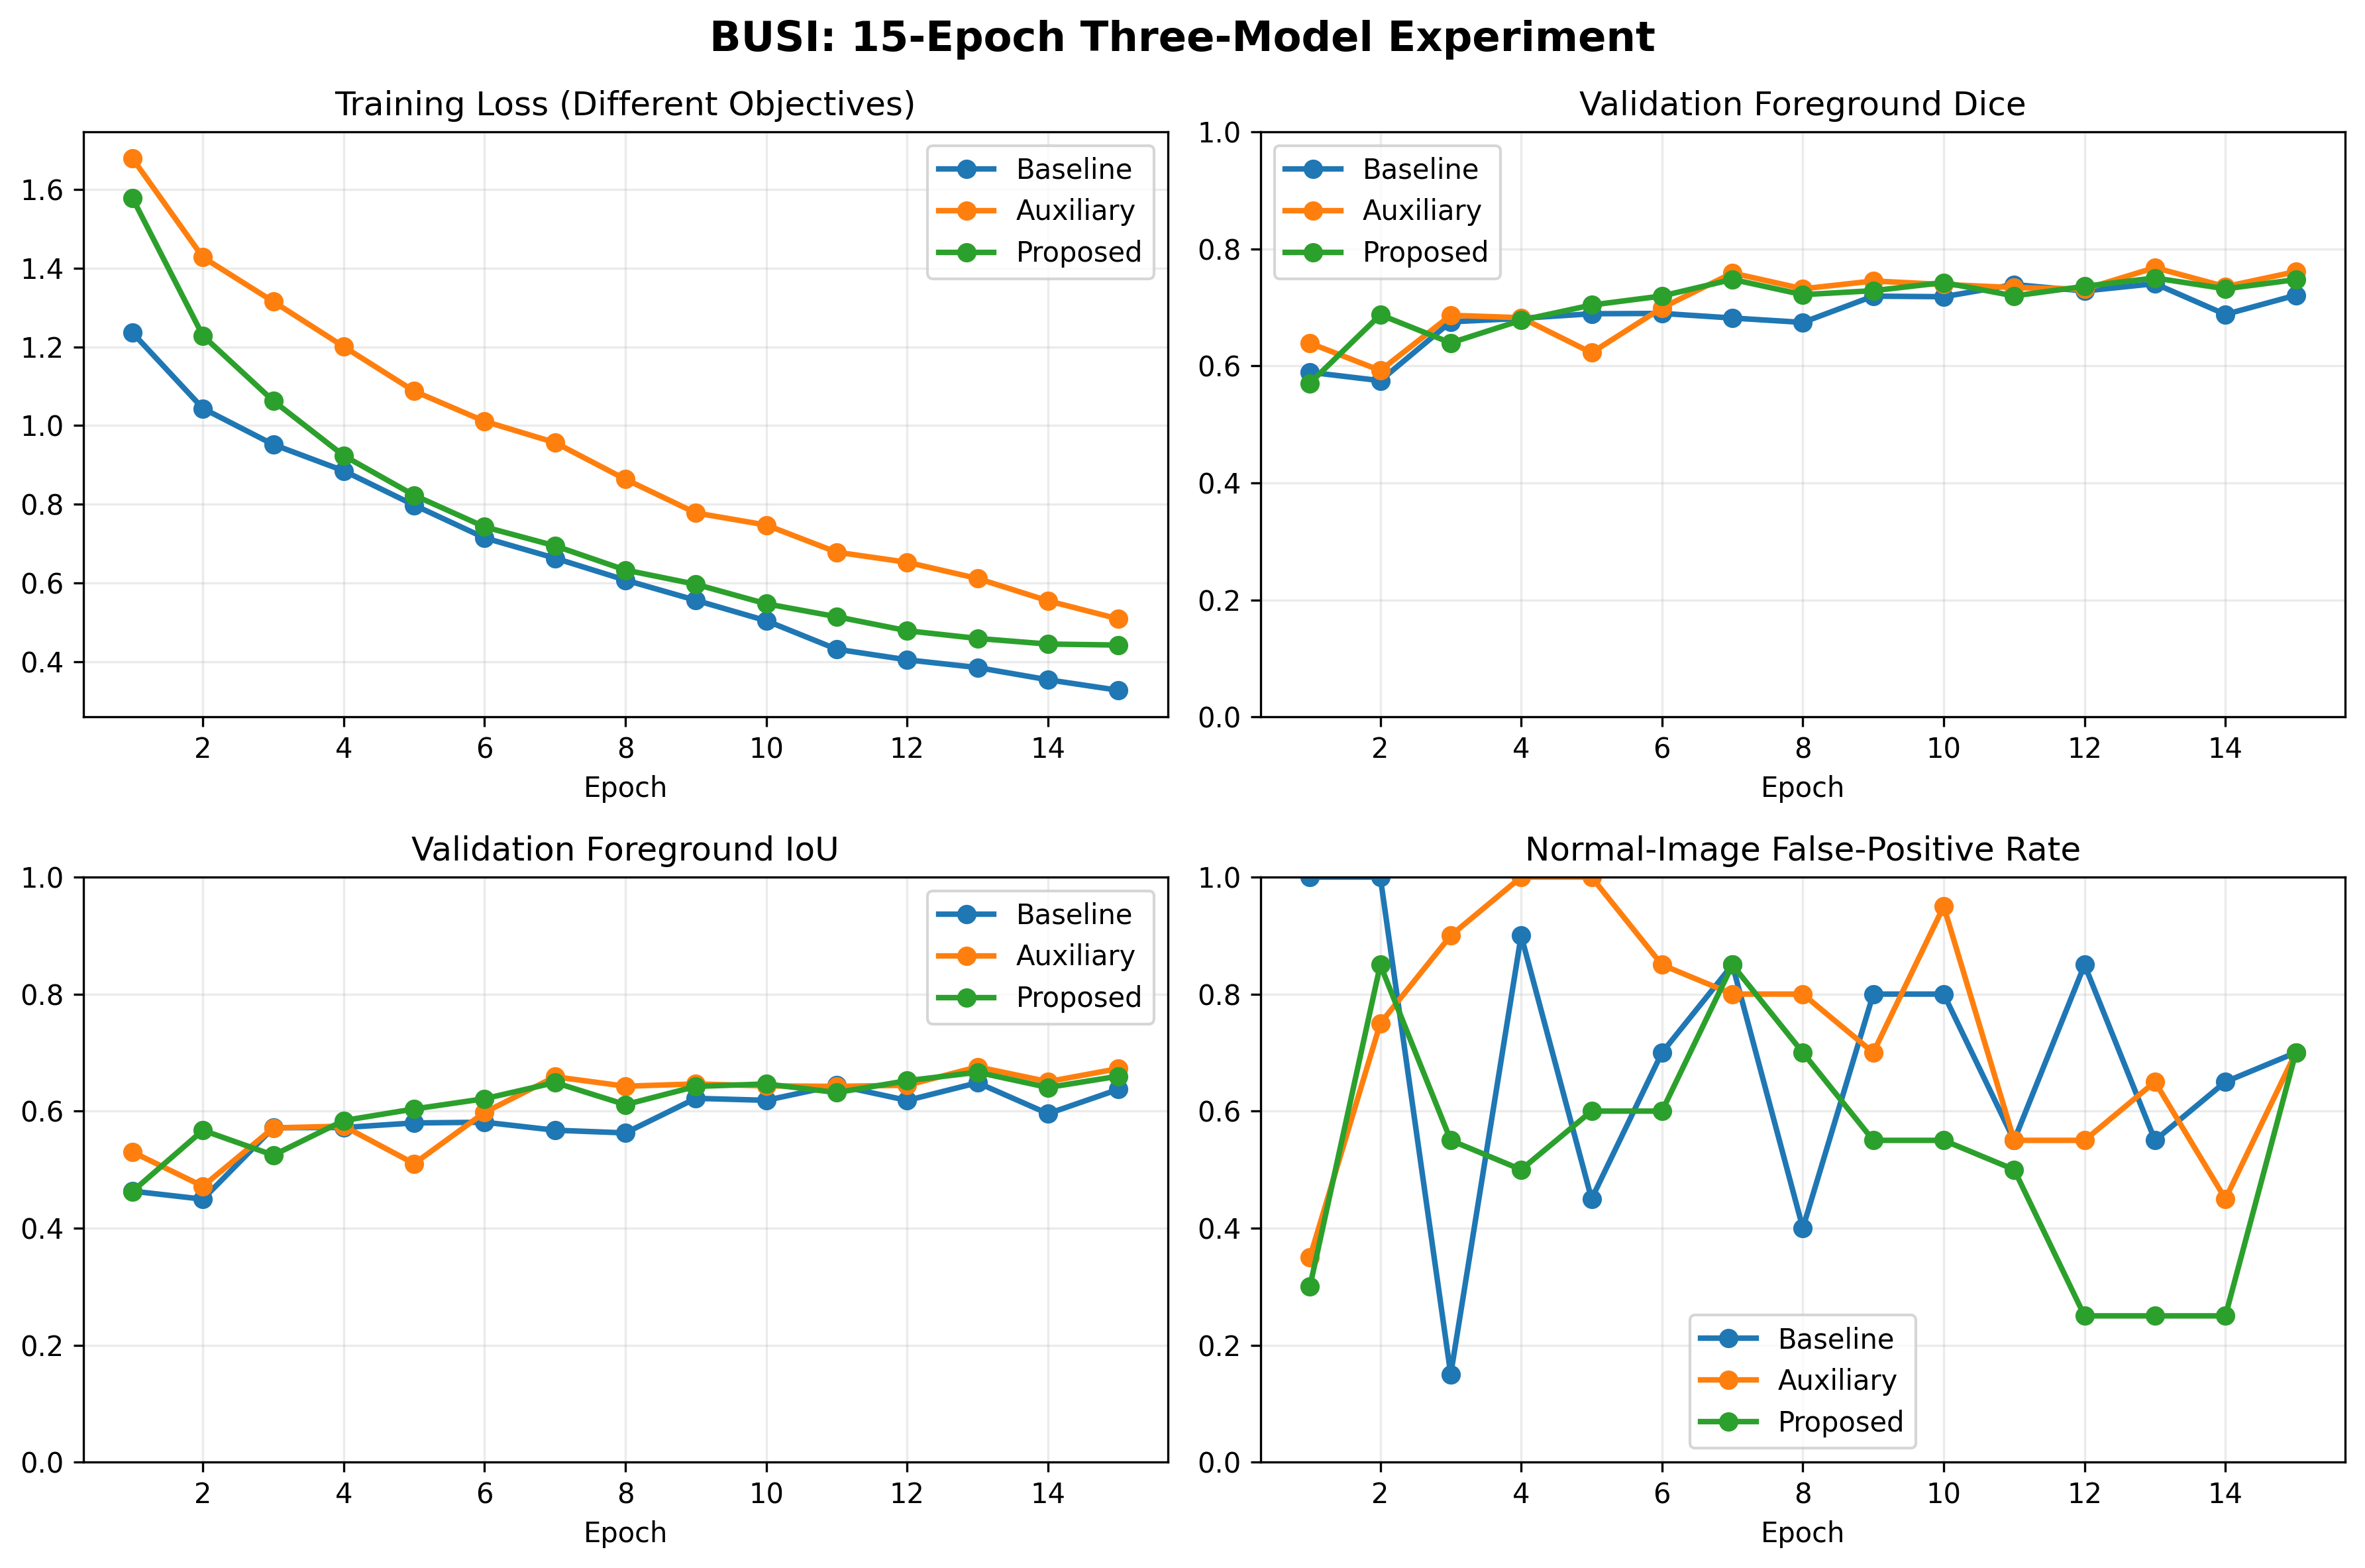


CELL 19 COMPLETED SUCCESSFULLY.


In [33]:

# ============================================================
# CELL 19: 15-EPOCH THREE-MODEL BUSI EXPERIMENT
#
# Models:
#   1. Baseline
#   2. Auxiliary (unconstrained)
#   3. Proposed (nested region-guided)
#
# Features:
#   - Fresh training runs with pretrained ResNet-18
#   - CUDA mixed precision
#   - Correct float32 BCE loss computation
#   - Validation after every epoch
#   - Best and last checkpoints
#   - PNG training graphs
#   - Automatic Google Drive backup
#   - Unique experiment directory
#   - Test partition remains unused
#
# Requires the previous definitions:
# RegionSeg, SegDataset, combined_loss,
# records, train, val, DATASET, DATASETS, IMAGE_SIZE
# ============================================================

import os
import json
import time
import uuid
import random
import shutil
import hashlib

from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torch.utils.data import DataLoader
from google.colab import drive


# ============================================================
# PART 1: EXPERIMENT CONFIGURATION
# ============================================================

RUN19_EPOCHS = 15
RUN19_BATCH_SIZE = 8
RUN19_SEED = 42

RUN19_LR = 3e-4
RUN19_WEIGHT_DECAY = 1e-4

RUN19_WORKERS = 2

RUN19_MODELS = (
    "baseline",
    "auxiliary",
    "proposed"
)

RUN19_DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

RUN19_AMP = RUN19_DEVICE.type == "cuda"


# ============================================================
# PART 2: CHECK PREVIOUS CELLS AND DATA SPLITS
# ============================================================

required_names = (
    "RegionSeg",
    "SegDataset",
    "combined_loss",
    "records",
    "train",
    "val",
    "DATASET",
    "DATASETS",
    "IMAGE_SIZE"
)

missing_names = [
    name for name in required_names
    if name not in globals()
]

if missing_names:
    raise RuntimeError(
        "Rerun earlier cells first. Missing: "
        + ", ".join(missing_names)
    )

if DATASET != "busi":
    raise ValueError(
        "Cell 19 is for BUSI. Set DATASET='busi' "
        "and rerun the data preparation cells."
    )

train_ids = [int(i) for i in train]
val_ids = [int(i) for i in val]

if (
    not train_ids
    or not val_ids
    or set(train_ids) & set(val_ids)
):
    raise ValueError(
        "Training and validation splits are empty or overlap."
    )

if (
    len(train_ids) != len(set(train_ids))
    or len(val_ids) != len(set(val_ids))
):
    raise ValueError(
        "Duplicate image indices found in a split."
    )

if "test" in globals():

    if set(test) & (set(train_ids) | set(val_ids)):
        raise ValueError(
            "Test images overlap training or validation."
        )


# ============================================================
# PART 3: AUXILIARY MODEL
# ============================================================

class AuxiliaryRegionSeg(RegionSeg):
    """
    Parameter-matched control for the proposed model.

    Proposed:
        P = C + (O - C) * T

    Auxiliary:
        P = T

    Both retain the core/support supervision
    and band-specific loss.
    """

    def __init__(self, pretrained=True):

        super().__init__(
            variant="proposed",
            pretrained=pretrained
        )

    def forward(self, x):

        result = super().forward(x)

        # Remove the nested output constraint.
        result["p"] = result["t"]

        return result


# ============================================================
# PART 4: CONNECT GOOGLE DRIVE
# ============================================================

drive.mount("/content/drive")

# Every execution creates a new unique directory.
run19_id = (
    f"busi_15ep_"
    f"{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}_"
    f"{uuid.uuid4().hex[:8]}"
)

RUN19_LOCAL_DIR = (
    Path("/content/Medical_Lesion_Segmentation_Research")
    / "extended_runs"
    / run19_id
)

RUN19_DRIVE_DIR = (
    Path(
        "/content/drive/MyDrive/"
        "Medical_Lesion_Segmentation_Research"
    )
    / "extended_runs"
    / run19_id
)

for folder in [RUN19_LOCAL_DIR, RUN19_DRIVE_DIR]:

    folder.mkdir(
        parents=True,
        exist_ok=False
    )

# Verify Drive write access before training.
(
    RUN19_DRIVE_DIR / "drive_write_test.txt"
).write_text("Drive backup enabled.\n")


# ============================================================
# PART 5: AUTOMATIC DRIVE BACKUP HELPER
# ============================================================

def backup(local_path):
    """
    Copy a result into this run's unique Drive folder.

    Files within the current run are updated.
    Previous experiment directories remain untouched.
    """

    local_path = Path(local_path)

    relative = local_path.relative_to(
        RUN19_LOCAL_DIR
    )

    destination = RUN19_DRIVE_DIR / relative

    destination.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temporary = destination.with_name(
        destination.name + ".partial"
    )

    shutil.copy2(local_path, temporary)

    os.replace(temporary, destination)


# ============================================================
# PART 6: REPRODUCIBILITY
# ============================================================

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def seed_worker(worker_id):

    worker_seed = (
        torch.initial_seed() % (2 ** 32)
    )

    np.random.seed(worker_seed)
    random.seed(worker_seed)


torch.backends.cudnn.benchmark = False

set_seed(RUN19_SEED)


# ============================================================
# PART 7: SAVE TRAINING/VALIDATION SPLIT RECORD
# ============================================================

def image_id(index):

    path = Path(records[index]["image"])

    try:
        return str(
            path.relative_to(Path(data_root))
        )

    except (NameError, ValueError):
        return path.name


split_rows = (
    [
        {"split": "train", "image": image_id(i)}
        for i in train_ids
    ]
    +
    [
        {"split": "val", "image": image_id(i)}
        for i in val_ids
    ]
)

manifest_file = (
    RUN19_LOCAL_DIR / "split_manifest_train_val.csv"
)

pd.DataFrame(split_rows).to_csv(
    manifest_file,
    index=False
)

manifest_sha = hashlib.sha256(
    manifest_file.read_bytes()
).hexdigest()


# ============================================================
# PART 8: SAVE EXPERIMENT CONFIGURATION
# ============================================================

config = {

    "study": "BUSI 15-epoch exploratory validation",

    "dataset": DATASETS[DATASET],

    "epochs": RUN19_EPOCHS,

    "batch_size": RUN19_BATCH_SIZE,

    "image_size": IMAGE_SIZE,

    "training_seed": RUN19_SEED,

    "learning_rate": RUN19_LR,

    "weight_decay": RUN19_WEIGHT_DECAY,

    "optimizer": "AdamW",

    "initialization":
        "Fresh training with ImageNet-pretrained ResNet18",

    "models": list(RUN19_MODELS),

    "checkpoint_selection":
        "Validation Dice at threshold 0.5",

    "metric_threshold": 0.5,

    "amp": RUN19_AMP,

    "torch_version": str(torch.__version__),

    "device": str(RUN19_DEVICE),

    "split_manifest_sha256": manifest_sha,

    "n_train": len(train_ids),

    "n_val": len(val_ids),

    "test_set_used": False,

    "note":
        "BUSI split is not verified patient-independent."
}

config_file = RUN19_LOCAL_DIR / "config.json"

config_file.write_text(
    json.dumps(config, indent=2)
)

backup(config_file)
backup(manifest_file)


# ============================================================
# PART 9: PREPARE DATASETS
# ============================================================

train_data = SegDataset(
    records,
    train_ids,
    augment=True
)

val_data = SegDataset(
    records,
    val_ids,
    augment=False
)

val_loader = DataLoader(

    val_data,

    batch_size=RUN19_BATCH_SIZE,

    shuffle=False,

    num_workers=RUN19_WORKERS,

    pin_memory=RUN19_AMP
)


# ============================================================
# PART 10: VALIDATION FUNCTION
# ============================================================

def evaluate19(net):

    """
    Full validation on the existing validation split.

    Dice/IoU:
        Average over foreground-containing images.

    Normal images:
        Report false-positive image rate and pixels.

    All predictions use threshold 0.5.
    """

    net.eval()

    case_rows = []

    total_loss = 0.0
    position = 0

    with torch.inference_mode():

        for batch in val_loader:

            batch = tuple(
                x.to(
                    RUN19_DEVICE,
                    non_blocking=RUN19_AMP
                )
                for x in batch
            )

            # Full float32 validation.
            output = net(batch[0])

            loss = combined_loss(
                output,
                batch,
                net.variant
            )

            total_loss += (
                float(loss.item()) * len(batch[0])
            )

            prediction = (
                output["p"]
                .float()
                .cpu()
                .numpy() >= 0.5
            )

            target = (
                batch[1]
                .cpu()
                .numpy() >= 0.5
            )

            for j, (pred, truth) in enumerate(
                zip(prediction, target)
            ):

                tp = int(
                    np.logical_and(pred, truth).sum()
                )

                fp = int(
                    np.logical_and(pred, ~truth).sum()
                )

                fn = int(
                    np.logical_and(~pred, truth).sum()
                )

                gt_pixels = int(truth.sum())
                pred_pixels = int(pred.sum())

                positive = gt_pixels > 0

                case_rows.append({

                    "image": image_id(
                        val_ids[position + j]
                    ),

                    "gt_pixels": gt_pixels,

                    "pred_pixels": pred_pixels,

                    "dice": (
                        2 * tp / max(1, 2 * tp + fp + fn)
                        if positive else np.nan
                    ),

                    "iou": (
                        tp / max(1, tp + fp + fn)
                        if positive else np.nan
                    ),

                    "precision": (
                        tp / max(1, tp + fp)
                        if positive else np.nan
                    ),

                    "recall": (
                        tp / max(1, tp + fn)
                        if positive else np.nan
                    ),

                    "zero_overlap": int(
                        positive and tp == 0
                    ),

                    "empty_prediction_on_lesion": int(
                        positive and pred_pixels == 0
                    ),

                    "false_positive_on_empty": int(
                        (not positive) and pred_pixels > 0
                    ),

                    "fp_pixels": fp
                })

            position += len(batch[0])

    cases = pd.DataFrame(case_rows)

    positive = cases[
        cases["gt_pixels"] > 0
    ]

    normal = cases[
        cases["gt_pixels"] == 0
    ]

    if positive.empty:
        raise RuntimeError(
            "No foreground validation images found."
        )

    metrics = {

        "val_loss":
            total_loss / len(val_data),

        "val_dice":
            float(positive["dice"].mean()),

        "val_iou":
            float(positive["iou"].mean()),

        "val_precision":
            float(positive["precision"].mean()),

        "val_recall":
            float(positive["recall"].mean()),

        "zero_overlap_count":
            int(positive["zero_overlap"].sum()),

        "empty_prediction_lesions":
            int(
                positive[
                    "empty_prediction_on_lesion"
                ].sum()
            ),

        "empty_fp_rate": (
            float(
                normal[
                    "false_positive_on_empty"
                ].mean()
            )
            if not normal.empty
            else float("nan")
        ),

        "normal_mean_fp_pixels": (
            float(normal["fp_pixels"].mean())
            if not normal.empty
            else float("nan")
        )
    }

    return metrics, cases


# ============================================================
# PART 11: AUTOMATIC TRAINING GRAPH FUNCTION
# ============================================================

def plot_progress19(rows, destination, dpi=170):

    df = pd.DataFrame(rows)

    fig, axes = plt.subplots(
        2, 2,
        figsize=(12, 8)
    )

    graphs = [

        (
            "train_loss",
            "Training Loss (Different Objectives)"
        ),

        (
            "val_dice",
            "Validation Foreground Dice"
        ),

        (
            "val_iou",
            "Validation Foreground IoU"
        ),

        (
            "empty_fp_rate",
            "Normal-Image False-Positive Rate"
        )
    ]

    for ax, (column, title) in zip(
        axes.flat, graphs
    ):

        for name in RUN19_MODELS:

            subset = df[
                df["model"] == name
            ].sort_values("epoch")

            if len(subset):

                ax.plot(
                    subset["epoch"],
                    subset[column],
                    marker="o",
                    linewidth=2,
                    label=name.capitalize()
                )

        ax.set_title(title)

        ax.set_xlabel("Epoch")

        ax.grid(alpha=0.25)

        if column != "train_loss":
            ax.set_ylim(0, 1)

        ax.legend()

    fig.suptitle(
        "BUSI: 15-Epoch Three-Model Experiment",
        fontsize=15,
        fontweight="bold"
    )

    fig.tight_layout()

    # PNG ONLY: avoids previous SVG export error.
    fig.savefig(
        destination,
        dpi=dpi,
        bbox_inches="tight",
        facecolor="white",
        format="png"
    )

    plt.close(fig)


# ============================================================
# PART 12: MAIN TRAINING LOOP
# ============================================================

history19 = []
parameter_counts = {}

history_file = (
    RUN19_LOCAL_DIR / "validation_history.csv"
)

progress_file = (
    RUN19_LOCAL_DIR / "progress.png"
)

print("\n" + "=" * 65)
print("15-EPOCH BUSI EXPERIMENT")
print("=" * 65)

print("Models:", RUN19_MODELS)

print("Device:", RUN19_DEVICE)

if RUN19_AMP:
    print("GPU:", torch.cuda.get_device_name(0))

print("Epochs per model:", RUN19_EPOCHS)

print("Training images:", len(train_data))

print("Validation images:", len(val_data))

print("Local results:", RUN19_LOCAL_DIR)

print("Google Drive:", RUN19_DRIVE_DIR)

print("=" * 65)


# ------------------------------------------------------------
# TRAIN EACH MODEL SEPARATELY
# ------------------------------------------------------------

for name in RUN19_MODELS:

    # Fresh initialization for every model.
    set_seed(RUN19_SEED)

    loader_generator = (
        torch.Generator().manual_seed(RUN19_SEED)
    )

    train_loader = DataLoader(

        train_data,

        batch_size=RUN19_BATCH_SIZE,

        shuffle=True,

        generator=loader_generator,

        worker_init_fn=seed_worker,

        num_workers=RUN19_WORKERS,

        pin_memory=RUN19_AMP
    )

    if name == "auxiliary":

        net = AuxiliaryRegionSeg(
            pretrained=True
        ).to(RUN19_DEVICE)

    else:

        net = RegionSeg(
            variant=name,
            pretrained=True
        ).to(RUN19_DEVICE)

    parameter_counts[name] = sum(
        p.numel() for p in net.parameters()
    )

    # Check exact matching between the two
    # region-guided architecture variants.
    if name == "proposed":

        assert (
            parameter_counts["proposed"]
            == parameter_counts["auxiliary"]
        ), "Auxiliary/proposed parameter mismatch"

    optimizer = torch.optim.AdamW(

        net.parameters(),

        lr=RUN19_LR,

        weight_decay=RUN19_WEIGHT_DECAY
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=RUN19_AMP
    )

    model_dir = RUN19_LOCAL_DIR / name

    model_dir.mkdir()

    best_file = model_dir / "best.pt"
    last_file = model_dir / "last.pt"

    best_cases_file = (
        model_dir / "best_validation_cases.csv"
    )

    best_dice = -float("inf")
    best_epoch = None

    print("\n" + "=" * 65)

    print("TRAINING:", name.upper())

    print(
        "Parameters:",
        f"{parameter_counts[name]:,}"
    )

    print("=" * 65)

    # --------------------------------------------------------
    # EPOCH LOOP
    # --------------------------------------------------------

    for epoch in range(1, RUN19_EPOCHS + 1):

        if RUN19_AMP:
            torch.cuda.synchronize()
            torch.cuda.reset_peak_memory_stats()

        epoch_start = time.perf_counter()

        net.train()

        total_train_loss = 0.0

        # ----------------------------------------------------
        # MINIBATCH TRAINING
        # ----------------------------------------------------

        for batch in train_loader:

            batch = tuple(

                x.to(
                    RUN19_DEVICE,
                    non_blocking=RUN19_AMP
                )

                for x in batch
            )

            optimizer.zero_grad(set_to_none=True)

            # Mixed precision: forward pass only.
            with torch.autocast(
                device_type=RUN19_DEVICE.type,
                enabled=RUN19_AMP
            ):

                prediction = net(batch[0])

            # Critical correction:
            # BCE probability losses run outside autocast.
            prediction = {

                key: value.float()

                for key, value in prediction.items()
            }

            loss = combined_loss(
                prediction,
                batch,
                net.variant
            )

            if not torch.isfinite(loss):

                raise RuntimeError(
                    f"Non-finite loss: {name}, epoch {epoch}"
                )

            scaler.scale(loss).backward()

            scaler.step(optimizer)

            scaler.update()

            total_train_loss += (
                float(loss.detach().item())
                * len(batch[0])
            )

        train_loss = (
            total_train_loss / len(train_data)
        )

        # ----------------------------------------------------
        # VALIDATION
        # ----------------------------------------------------

        metrics, case_df = evaluate19(net)

        if RUN19_AMP:
            torch.cuda.synchronize()

        epoch_seconds = (
            time.perf_counter() - epoch_start
        )

        peak_gb = (
            torch.cuda.max_memory_allocated()
            / (1024 ** 3)
            if RUN19_AMP
            else float("nan")
        )

        current_dice = float(
            metrics["val_dice"]
        )

        if not np.isfinite(current_dice):

            raise RuntimeError(
                f"Invalid validation Dice: {name}, "
                f"epoch {epoch}"
            )

        # ----------------------------------------------------
        # SAVE METRICS
        # ----------------------------------------------------

        history19.append({

            "model": name,

            "epoch": epoch,

            "train_loss": train_loss,

            "epoch_seconds": epoch_seconds,

            "gpu_peak_gb": peak_gb,

            **metrics
        })

        pd.DataFrame(history19).to_csv(
            history_file,
            index=False
        )

        # ----------------------------------------------------
        # SAVE BEST CHECKPOINT
        # ----------------------------------------------------

        improved = current_dice > best_dice

        if improved:

            best_dice = current_dice
            best_epoch = epoch

            torch.save({

                "model": name,

                "epoch": epoch,

                "state_dict": net.state_dict(),

                "best_val_dice": best_dice,

                "config": config

            }, best_file)

            case_df.to_csv(
                best_cases_file,
                index=False
            )

        # ----------------------------------------------------
        # SAVE LAST CHECKPOINT FOR POSSIBLE RESUME
        # ----------------------------------------------------

        torch.save({

            "model": name,

            "epoch": epoch,

            "state_dict": net.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "scaler_state_dict":
                scaler.state_dict(),

            "best_val_dice": best_dice,

            "best_epoch": best_epoch,

            "config": config

        }, last_file)

        # ----------------------------------------------------
        # AUTOMATIC DRIVE BACKUP AFTER EVERY EPOCH
        # ----------------------------------------------------

        backup(history_file)

        backup(last_file)

        if improved:
            backup(best_file)
            backup(best_cases_file)

        # Save and back up current progress graphs.
        plot_progress19(
            history19,
            progress_file,
            dpi=170
        )

        backup(progress_file)

        # ----------------------------------------------------
        # DISPLAY PROGRESS
        # ----------------------------------------------------

        print(

            f"{name:>9} | "

            f"Epoch {epoch:02d}/{RUN19_EPOCHS} | "

            f"Train Loss: {train_loss:.4f} | "

            f"Val Dice: {metrics['val_dice']:.4f} | "

            f"Val IoU: {metrics['val_iou']:.4f} | "

            f"Normal FP: {metrics['empty_fp_rate']:.2f} | "

            f"Zero-overlap: {metrics['zero_overlap_count']} | "

            f"Time: {epoch_seconds:.1f}s | "

            "Drive backup complete"
        )

    # --------------------------------------------------------
    # MODEL COMPLETED
    # --------------------------------------------------------

    print("\nModel completed:", name.upper())

    print("Best validation Dice:", best_dice)

    print("Best epoch:", best_epoch)

    print("Checkpoint:", best_file)

    del net
    del optimizer
    del scaler

    if RUN19_AMP:
        torch.cuda.empty_cache()


# ============================================================
# PART 13: FINAL THREE-MODEL COMPARISON
# ============================================================

df19 = pd.DataFrame(history19)

summary_rows = []

for name in RUN19_MODELS:

    model_history = df19[
        df19["model"] == name
    ]

    best_row = model_history.loc[
        model_history["val_dice"].idxmax()
    ]

    summary_rows.append({

        "model": name,

        "parameters": parameter_counts[name],

        "best_epoch": int(best_row["epoch"]),

        "val_dice_at_0_5":
            float(best_row["val_dice"]),

        "val_iou_at_0_5":
            float(best_row["val_iou"]),

        "val_precision":
            float(best_row["val_precision"]),

        "val_recall":
            float(best_row["val_recall"]),

        "empty_fp_rate_at_0_5":
            float(best_row["empty_fp_rate"]),

        "zero_overlap_count_at_0_5":
            int(best_row["zero_overlap_count"]),

        "train_val_time_seconds":
            float(model_history["epoch_seconds"].sum())
    })

summary19 = pd.DataFrame(summary_rows)

summary_file = (
    RUN19_LOCAL_DIR / "three_model_summary.csv"
)

summary19.to_csv(
    summary_file,
    index=False
)

# Final high-resolution experimental figure.
plot_progress19(
    history19,
    progress_file,
    dpi=300
)

backup(summary_file)
backup(progress_file)


# ============================================================
# PART 14: DISPLAY FINAL RESULTS
# ============================================================

print("\n" + "=" * 70)
print("15-EPOCH BUSI EXPERIMENT COMPLETED")
print("=" * 70)

print("\nBEST-CHECKPOINT VALIDATION RESULTS")
print("(All models evaluated at threshold 0.50)\n")

print(
    summary19.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nGoogle Drive results:")
print(RUN19_DRIVE_DIR)

print("\nPrevious five-epoch results were not overwritten.")

print("\nThe held-out test set has NOT been evaluated.")

# Display final experimental graphs.
from IPython.display import display, Image as DisplayImage

display(
    DisplayImage(
        filename=str(progress_file)
    )
)

print("\nCELL 19 COMPLETED SUCCESSFULLY.")


In [34]:

# ============================================================
# CELL 20: 15-EPOCH PAIRED MODEL COMPARISON
# Validation only - no training or test-set evaluation
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
import shutil

root = Path(RUN19_LOCAL_DIR)
drive_root = Path(RUN19_DRIVE_DIR)

names = ["baseline", "auxiliary", "proposed"]
cases = {}

# ------------------------------------------------------------
# 1. Load best-checkpoint validation predictions
# ------------------------------------------------------------

for name in names:

    path = root / name / "best_validation_cases.csv"

    df = pd.read_csv(path)

    if df["image"].duplicated().any():
        raise ValueError(f"Duplicate image IDs in {name}")

    cases[name] = df.set_index("image").sort_index()

reference = cases["baseline"]

for name in names[1:]:

    other = cases[name]

    assert reference.index.equals(other.index), (
        f"Image mismatch: {name}"
    )

    assert (
        reference["gt_pixels"].to_numpy()
        == other["gt_pixels"].to_numpy()
    ).all(), f"Ground-truth mismatch: {name}"

print("All validation image identities verified.")

# ------------------------------------------------------------
# 2. Compare only images containing annotated lesions
# ------------------------------------------------------------

lesion_ids = reference.index[
    reference["gt_pixels"] > 0
]

normal_ids = reference.index[
    reference["gt_pixels"] == 0
]

paired = pd.DataFrame({
    name: cases[name].loc[lesion_ids, "dice"]
    for name in names
})

comparisons = [
    ("auxiliary", "proposed"),
    ("auxiliary", "baseline"),
    ("proposed", "baseline")
]

rng = np.random.default_rng(42)
reports = []

for first, second in comparisons:

    diff = (
        paired[first] - paired[second]
    ).to_numpy()

    samples = rng.integers(
        0, len(diff),
        size=(5000, len(diff))
    )

    boot = diff[samples].mean(axis=1)

    low, high = np.percentile(boot, [2.5, 97.5])

    reports.append({
        "comparison": f"{first} - {second}",
        "mean_dice_difference": diff.mean(),
        "median_difference": np.median(diff),
        "improved_images": int((diff > 0).sum()),
        "worsened_images": int((diff < 0).sum()),
        "tied_images": int((diff == 0).sum()),
        "bootstrap_low": low,
        "bootstrap_high": high
    })

report = pd.DataFrame(reports)

print("\nPAIRED DICE ANALYSIS")
print(report.round(4).to_string(index=False))

# ------------------------------------------------------------
# 3. Normal-image and lesion-omission analysis
# ------------------------------------------------------------

summary = []

for name in names:

    lesion = cases[name].loc[lesion_ids]
    normal = cases[name].loc[normal_ids]

    summary.append({
        "model": name,
        "mean_lesion_dice": lesion["dice"].mean(),
        "zero_overlap_lesions": int(
            lesion["zero_overlap"].sum()
        ),
        "normal_fp_images": int(
            (normal["pred_pixels"] > 0).sum()
        ),
        "normal_images": len(normal),
        "normal_mean_fp_pixels": float(
            normal["fp_pixels"].mean()
        )
    })

summary = pd.DataFrame(summary)

print("\nLESION AND NORMAL-IMAGE ANALYSIS")
print(summary.round(4).to_string(index=False))

# ------------------------------------------------------------
# 4. Identify the largest proposed-model failures
# ------------------------------------------------------------

paired["proposed_minus_auxiliary"] = (
    paired["proposed"] - paired["auxiliary"]
)

worst = paired.nsmallest(
    10, "proposed_minus_auxiliary"
)

print("\n10 WORST CASES: PROPOSED VS AUXILIARY")
print(worst.round(4).to_string())

# ------------------------------------------------------------
# 5. Save and back up results
# ------------------------------------------------------------

outputs = {
    "BUSI_15ep_Paired_Dice.csv": paired,
    "BUSI_15ep_Paired_Statistics.csv": report,
    "BUSI_15ep_Lesion_Normal_Summary.csv": summary,
    "BUSI_15ep_Worst_Cases.csv": worst
}

for filename, frame in outputs.items():

    local_path = root / filename
    destination = drive_root / filename

    frame.to_csv(local_path, index=True)

    destination.parent.mkdir(
        parents=True, exist_ok=True
    )

    shutil.copy2(local_path, destination)

    print("Saved:", destination)

print("\nCELL 20 COMPLETED.")
print("Held-out test set remains unused.")


All validation image identities verified.

PAIRED DICE ANALYSIS
          comparison  mean_dice_difference  median_difference  improved_images  worsened_images  tied_images  bootstrap_low  bootstrap_high
auxiliary - proposed                0.0177             0.0000               48               48            1        -0.0160          0.0537
auxiliary - baseline                0.0274             0.0184               61               35            1        -0.0092          0.0644
 proposed - baseline                0.0097             0.0145               64               29            4        -0.0190          0.0367

LESION AND NORMAL-IMAGE ANALYSIS
    model  mean_lesion_dice  zero_overlap_lesions  normal_fp_images  normal_images  normal_mean_fp_pixels
 baseline            0.7405                     7                11             20                1093.45
auxiliary            0.7679                     2                13             20                2340.85
 proposed            0.7

BUSI CELL 21: CHECKPOINT ANALYSIS
Validation split verification: PASSED
Validation images: 117
Checkpoints: 3
Thresholds: 22
Device: cuda
Output directory: /content/drive/MyDrive/Medical_Lesion_Segmentation_Research/extended_runs/busi_15ep_20261014T193459Z_8492e471/cell21_validation_diagnostics/20261014T201239Z_b11732
Foreground images: 97
Empty-mask images: 20

Loading saved checkpoint: baseline

Loading saved checkpoint: auxiliary

Loading saved checkpoint: proposed

Nested model ordering C <= P <= O: PASSED

Evaluating thresholds for: baseline

Evaluating thresholds for: auxiliary

Evaluating thresholds for: proposed

Per-image threshold evaluations: 7722
baseline: maximum saved Dice difference = 1.11022e-16
auxiliary: maximum saved Dice difference = 1.11022e-16
proposed: maximum saved Dice difference = 1.11022e-16

THRESHOLD 0.50 RESULTS
    model  threshold  n_lesions  n_normal  mean_dice  mean_iou  mean_precision  mean_recall  zero_overlap_count  empty_lesion_predictions  normal_

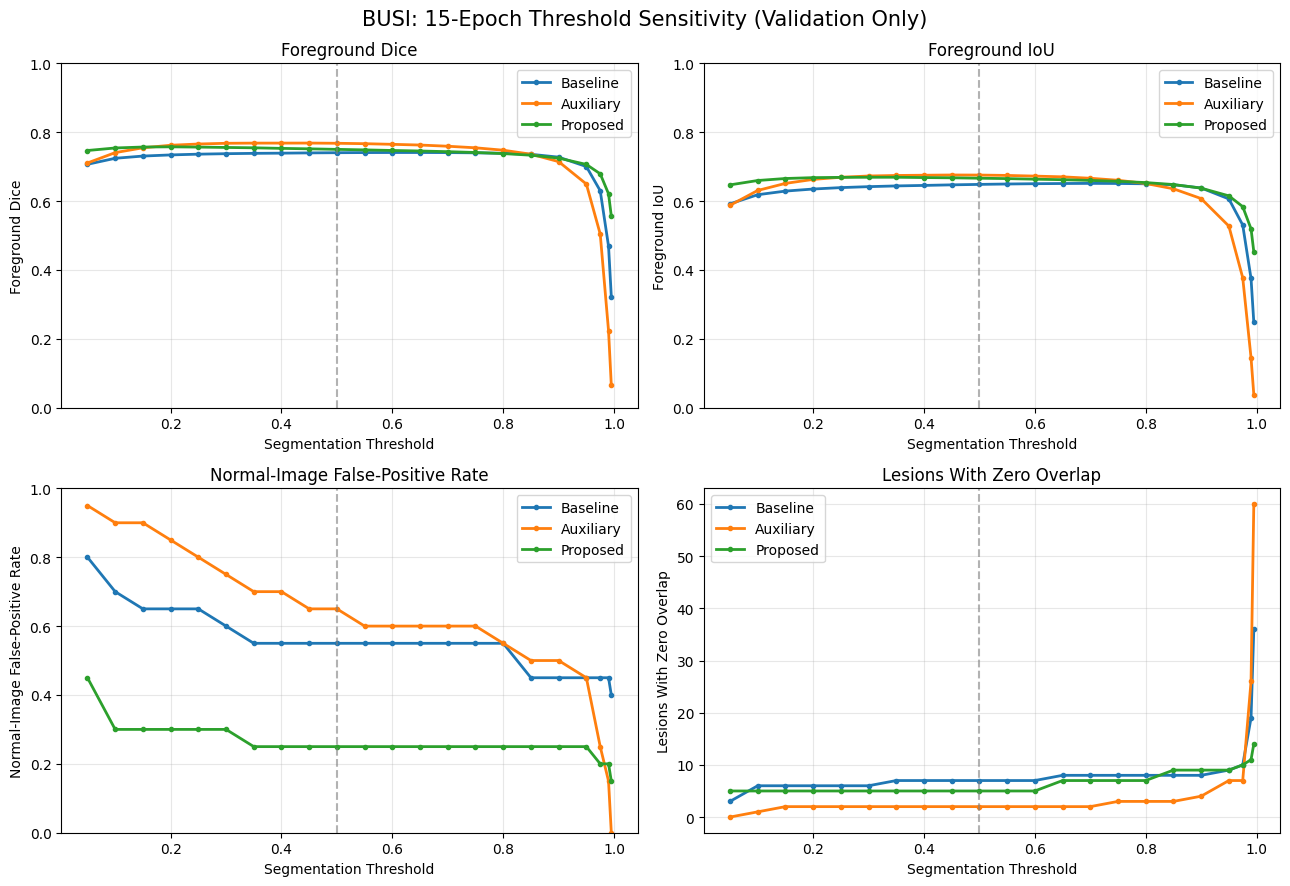

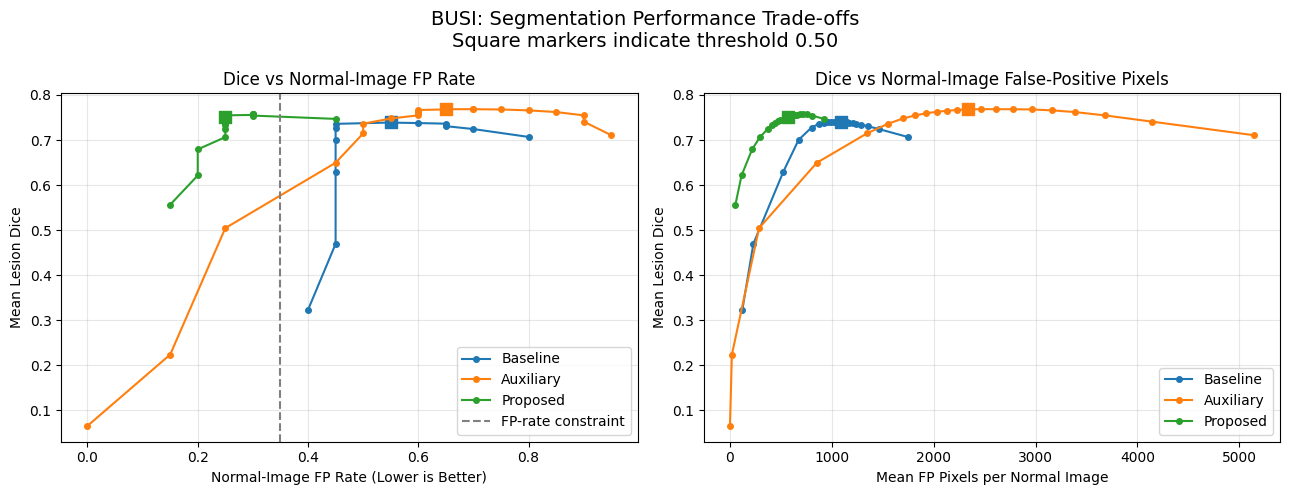


FIVE WORST NESTED VS AUXILIARY CASES
model                                               auxiliary  baseline  proposed  nested_minus_auxiliary
image                                                                                                    
Dataset_BUSI_with_GT/malignant/malignant (109).png     0.6700    0.3615    0.0000                 -0.6700
Dataset_BUSI_with_GT/benign/benign (408).png           0.8881    0.8228    0.3219                 -0.5662
Dataset_BUSI_with_GT/benign/benign (233).png           0.5878    0.0000    0.0274                 -0.5604
Dataset_BUSI_with_GT/malignant/malignant (160).png     0.7364    0.6035    0.2317                 -0.5047
Dataset_BUSI_with_GT/malignant/malignant (165).png     0.8318    0.8443    0.4004                 -0.4314


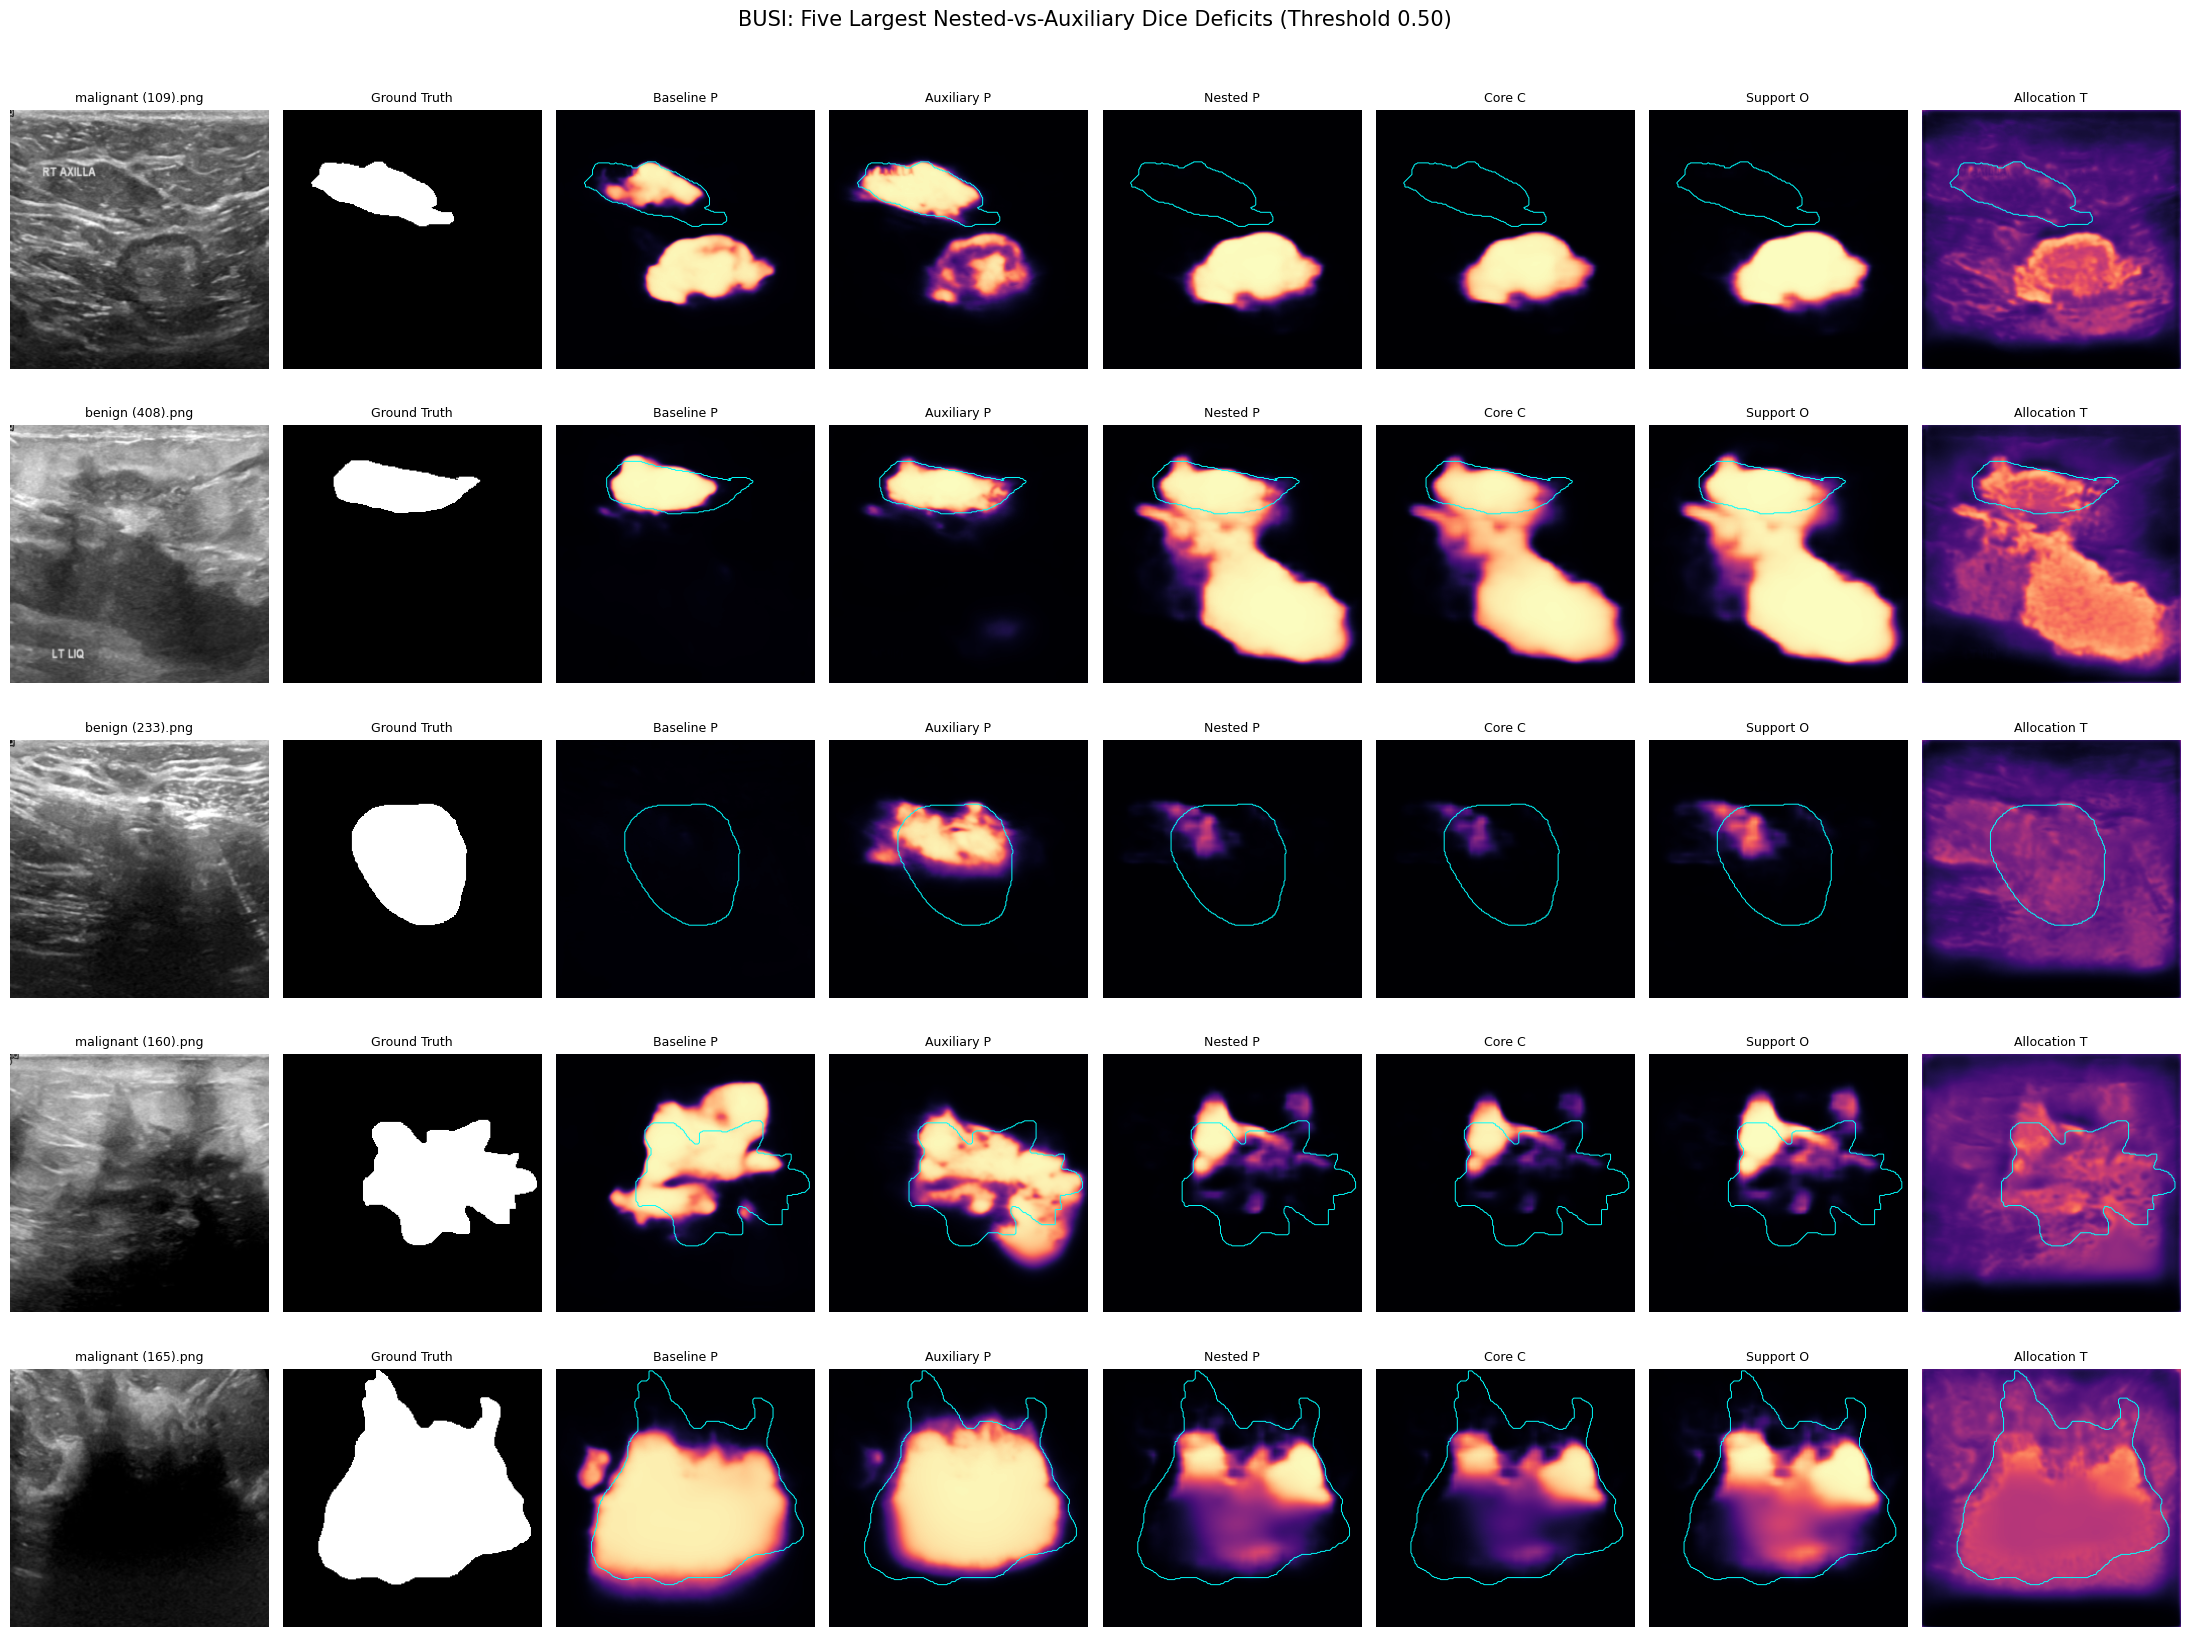


WORST-CASE CORE/SUPPORT DIAGNOSTICS
                                             image  baseline_dice_0_5  auxiliary_dice_0_5  nested_dice_0_5  nested_max_probability  nested_max_core  nested_max_support  support_coverage_on_gt_at_0_5  gt_pixels
Dataset_BUSI_with_GT/malignant/malignant (109).png             0.3615              0.6700           0.0000                  0.9985           0.9962              0.9998                         0.0000       5059
      Dataset_BUSI_with_GT/benign/benign (408).png             0.8228              0.8881           0.3219                  0.9989           0.9969              0.9996                         0.8540       4940
      Dataset_BUSI_with_GT/benign/benign (233).png             0.0000              0.5878           0.0274                  0.6033           0.4398              0.7665                         0.0663      10768
Dataset_BUSI_with_GT/malignant/malignant (160).png             0.6035              0.7364           0.2317                 

In [35]:

# ============================================================
# CELL 21: BUSI THRESHOLD AND FAILURE ANALYSIS
#
# Models:
#   1. Baseline
#   2. Auxiliary
#   3. Proposed nested region-guided model
#
# Uses the saved 15-epoch BEST checkpoints.
#
# Outputs:
#   - Threshold sensitivity CSV
#   - Per-image threshold metrics
#   - Dice vs false-positive trade-off graphs
#   - Validation threshold candidates
#   - Core/support/allocation failure maps
#   - Failure diagnostics CSV
#
# NO TRAINING
# NO TEST-SET EVALUATION
# NO OVERWRITING PREVIOUS EXPERIMENTS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from uuid import uuid4
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torch.utils.data import DataLoader
from google.colab import drive


# ============================================================
# PART 1: EXPERIMENT CONFIGURATION
# ============================================================

# Exact Drive directory from your completed Cell 19.
SOURCE_DIR = Path(
    "/content/drive/MyDrive/"
    "Medical_Lesion_Segmentation_Research/"
    "extended_runs/"
    "busi_15ep_20261014T193459Z_8492e471"
)

# Exploratory validation constraint.
# This is not an independently validated clinical limit.
FP_RATE_LIMIT = 0.35

# Extend the threshold range to investigate
# whether high-confidence predictions reduce false positives.
THRESHOLDS = np.array([
    *np.round(np.arange(0.05, 0.951, 0.05), 3),
    0.975,
    0.99,
    0.995
])


# ============================================================
# PART 2: GOOGLE DRIVE AND PREPARATION CHECKS
# ============================================================

if not Path("/content/drive/MyDrive").is_dir():
    drive.mount("/content/drive")

required = (
    "RegionSeg",
    "SegDataset",
    "records",
    "val",
    "DATASET",
    "data_root"
)

for name in required:

    if name not in globals():
        raise RuntimeError(
            f"Missing {name}. "
            "Rerun the relevant setup/data/model cells."
        )

if DATASET != "busi":
    raise RuntimeError(
        "Cell 21 expects DATASET='busi'."
    )

if not SOURCE_DIR.is_dir():
    raise FileNotFoundError(
        f"Experiment directory missing: {SOURCE_DIR}"
    )


# ============================================================
# PART 3: LOCATE THE TRAINED CHECKPOINTS
# ============================================================

checkpoint_paths = {
    name: SOURCE_DIR / name / "best.pt"
    for name in (
        "baseline",
        "auxiliary",
        "proposed"
    )
}

required_files = [
    *checkpoint_paths.values(),
    SOURCE_DIR / "split_manifest_train_val.csv"
]

for path in required_files:

    if not path.is_file():
        raise FileNotFoundError(
            f"Required experiment file missing: {path}"
        )


# ============================================================
# PART 4: VERIFY THE ORIGINAL VALIDATION SPLIT
# ============================================================

val_ids = [int(i) for i in val]

image_ids = [
    str(
        Path(records[i]["image"]).relative_to(
            Path(data_root)
        )
    )
    for i in val_ids
]

if len(image_ids) != len(set(image_ids)):
    raise RuntimeError(
        "Duplicate validation image IDs detected."
    )

manifest = pd.read_csv(
    SOURCE_DIR / "split_manifest_train_val.csv"
)

stored_val_ids = manifest.loc[
    manifest["split"] == "val",
    "image"
].astype(str).tolist()

if (
    len(stored_val_ids) != len(image_ids)
    or set(stored_val_ids) != set(image_ids)
):
    raise RuntimeError(
        "The active validation split differs from "
        "the saved 15-epoch split manifest. "
        "Restore the original split before continuing."
    )

print("=" * 65)
print("BUSI CELL 21: CHECKPOINT ANALYSIS")
print("=" * 65)

print("Validation split verification: PASSED")
print("Validation images:", len(image_ids))
print("Checkpoints:", len(checkpoint_paths))
print("Thresholds:", len(THRESHOLDS))


# ============================================================
# PART 5: DEFINE AUXILIARY MODEL
# ============================================================

class AuxiliaryRegionSeg(RegionSeg):

    def __init__(self, pretrained=False):

        super().__init__(
            variant="proposed",
            pretrained=pretrained
        )

    def forward(self, x):

        result = super().forward(x)

        # Unconstrained semantic segmentation prediction.
        result["p"] = result["t"]

        return result


# ============================================================
# PART 6: CREATE UNIQUE OUTPUT DIRECTORY IN DRIVE
# ============================================================

run_tag = (
    datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%SZ"
    )
    + "_"
    + uuid4().hex[:6]
)

OUT_DIR = (
    SOURCE_DIR
    / "cell21_validation_diagnostics"
    / run_tag
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=False
)

DEVICE21 = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE21)
print("Output directory:", OUT_DIR)


# ============================================================
# PART 7: LOAD VALIDATION DATA
# ============================================================

val_dataset21 = SegDataset(
    records,
    val_ids,
    augment=False
)

val_loader21 = DataLoader(
    val_dataset21,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

# Cache validation minibatches.
# All three models receive exactly the same inputs.
validation_batches = [
    (batch[0], batch[1])
    for batch in val_loader21
]

truth_masks = torch.cat(
    [
        batch[1][:, 0]
        for batch in validation_batches
    ],
    dim=0
).numpy() >= 0.5

assert len(truth_masks) == len(image_ids)

gt_pixels = np.count_nonzero(
    truth_masks,
    axis=(1, 2)
)

print("Foreground images:", int((gt_pixels > 0).sum()))
print("Empty-mask images:", int((gt_pixels == 0).sum()))


# ============================================================
# PART 8: LOAD CHECKPOINTS AND RUN INFERENCE
# ============================================================

model_outputs = {}

for name, checkpoint_path in checkpoint_paths.items():

    print("\nLoading saved checkpoint:", name)

    if name == "auxiliary":

        net = AuxiliaryRegionSeg(
            pretrained=False
        ).to(DEVICE21)

    else:

        net = RegionSeg(
            variant=name,
            pretrained=False
        ).to(DEVICE21)

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    net.load_state_dict(
        checkpoint["state_dict"],
        strict=True
    )

    net.eval()

    outputs = {"p": []}

    if name == "proposed":
        outputs.update({
            "c": [],
            "o": [],
            "t": []
        })

    # Full float32 inference, matching Cell 19 validation.
    with torch.inference_mode():

        for images, _ in validation_batches:

            images = images.to(DEVICE21)

            response = net(images)

            for key in outputs:

                outputs[key].append(
                    response[key][:, 0]
                    .float()
                    .cpu()
                    .numpy()
                )

    model_outputs[name] = {
        key: np.concatenate(values, axis=0)
        for key, values in outputs.items()
    }

    del net

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# PART 9: VERIFY NESTED OUTPUT CONSTRAINT
# ============================================================

nested = model_outputs["proposed"]

if np.any(nested["p"] > nested["o"] + 1e-5):
    raise RuntimeError(
        "Nested probability ordering check failed."
    )

if np.any(nested["c"] > nested["p"] + 1e-5):
    raise RuntimeError(
        "Core/final probability ordering check failed."
    )

print("\nNested model ordering C <= P <= O: PASSED")


# ============================================================
# PART 10: THRESHOLD EVALUATION
# ============================================================

case_rows = []

for name, outputs in model_outputs.items():

    probability = outputs["p"]

    print("\nEvaluating thresholds for:", name)

    for threshold in THRESHOLDS:

        masks = probability >= threshold

        tp = np.count_nonzero(
            masks & truth_masks,
            axis=(1, 2)
        )

        fp = np.count_nonzero(
            masks & ~truth_masks,
            axis=(1, 2)
        )

        fn = np.count_nonzero(
            ~masks & truth_masks,
            axis=(1, 2)
        )

        pred_pixels = np.count_nonzero(
            masks,
            axis=(1, 2)
        )

        for i, image_id in enumerate(image_ids):

            positive = bool(gt_pixels[i])

            dice_denominator = max(
                1,
                int(2 * tp[i] + fp[i] + fn[i])
            )

            iou_denominator = max(
                1,
                int(tp[i] + fp[i] + fn[i])
            )

            case_rows.append({

                "model": name,

                "threshold": float(threshold),

                "sample_index": i,

                "image": image_id,

                "category": records[val_ids[i]]["label"],

                "gt_pixels": int(gt_pixels[i]),

                "pred_pixels": int(pred_pixels[i]),

                "dice": (
                    float(2 * tp[i] / dice_denominator)
                    if positive else np.nan
                ),

                "iou": (
                    float(tp[i] / iou_denominator)
                    if positive else np.nan
                ),

                "recall": (
                    float(
                        tp[i] /
                        max(1, int(tp[i] + fn[i]))
                    )
                    if positive else np.nan
                ),

                "precision": (
                    float(
                        tp[i] /
                        max(1, int(tp[i] + fp[i]))
                    )
                    if positive else np.nan
                ),

                "zero_overlap": int(
                    positive and tp[i] == 0
                ),

                "empty_lesion_prediction": int(
                    positive and pred_pixels[i] == 0
                ),

                "normal_fp_image": int(
                    not positive and pred_pixels[i] > 0
                ),

                "fp_pixels": int(fp[i])

            })


per_case = pd.DataFrame(case_rows)

per_case_path = (
    OUT_DIR / "threshold_per_image.csv"
)

per_case.to_csv(
    per_case_path,
    index=False
)

print("\nPer-image threshold evaluations:", len(per_case))


# ============================================================
# PART 11: VERIFY CHECKPOINT RESULTS AGAINST CELL 19
# ============================================================

# This detects major changes in data ordering,
# preprocessing, model definition, or checkpoint loading.

for name in checkpoint_paths:

    saved_cases = pd.read_csv(
        SOURCE_DIR / name / "best_validation_cases.csv"
    ).set_index("image")

    new_cases = per_case.loc[
        (per_case["model"] == name)
        & np.isclose(per_case["threshold"], 0.50)
    ].set_index("image")

    if set(saved_cases.index) != set(new_cases.index):
        raise RuntimeError(
            f"Checkpoint comparison image mismatch: {name}"
        )

    new_cases = new_cases.loc[saved_cases.index]

    if not np.array_equal(
        saved_cases["gt_pixels"].to_numpy(),
        new_cases["gt_pixels"].to_numpy()
    ):
        raise RuntimeError(
            f"Ground-truth mismatch: {name}"
        )

    differences = np.abs(
        saved_cases["dice"].to_numpy()
        - new_cases["dice"].to_numpy()
    )

    max_difference = np.nanmax(differences)

    print(
        f"{name}: maximum saved Dice difference = "
        f"{max_difference:.6g}"
    )

    if max_difference > 0.005:
        raise RuntimeError(
            f"Unexpected prediction differences in {name}. "
            "Check preprocessing and checkpoint definitions."
        )


# ============================================================
# PART 12: CALCULATE THRESHOLD SUMMARY
# ============================================================

summary_rows = []

for (name, threshold), subset in per_case.groupby(
    ["model", "threshold"],
    sort=False
):

    lesion = subset[
        subset["gt_pixels"] > 0
    ]

    normal = subset[
        subset["gt_pixels"] == 0
    ]

    summary_rows.append({

        "model": name,

        "threshold": float(threshold),

        "n_lesions": len(lesion),

        "n_normal": len(normal),

        "mean_dice": float(
            lesion["dice"].mean()
        ),

        "mean_iou": float(
            lesion["iou"].mean()
        ),

        "mean_precision": float(
            lesion["precision"].mean()
        ),

        "mean_recall": float(
            lesion["recall"].mean()
        ),

        "zero_overlap_count": int(
            lesion["zero_overlap"].sum()
        ),

        "empty_lesion_predictions": int(
            lesion["empty_lesion_prediction"].sum()
        ),

        "normal_fp_images": int(
            normal["normal_fp_image"].sum()
        ),

        "normal_fp_rate": (
            float(normal["normal_fp_image"].mean())
            if len(normal) else np.nan
        ),

        "mean_normal_fp_pixels": (
            float(normal["fp_pixels"].mean())
            if len(normal) else np.nan
        )

    })


summary = pd.DataFrame(summary_rows)

summary_path = (
    OUT_DIR / "threshold_summary.csv"
)

summary.to_csv(
    summary_path,
    index=False
)

print("\n" + "=" * 65)
print("THRESHOLD 0.50 RESULTS")
print("=" * 65)

print(
    summary.loc[
        np.isclose(summary["threshold"], 0.50)
    ].round(4).to_string(index=False)
)


# ============================================================
# PART 13: VALIDATION-ONLY THRESHOLD SELECTION
# ============================================================

selected_rows = []

for name in checkpoint_paths:

    candidate = summary[
        summary["model"] == name
    ].copy()

    selections = {

        "best_dice_any_fp": candidate,

        f"best_dice_with_fp_rate_le_{FP_RATE_LIMIT}":
            candidate[
                candidate["normal_fp_rate"] <= FP_RATE_LIMIT
            ]

    }

    for rule, eligible in selections.items():

        if eligible.empty:

            selected_rows.append({
                "model": name,
                "rule": rule,
                "status": "no eligible threshold"
            })

            continue

        chosen = eligible.sort_values(
            [
                "mean_dice",
                "normal_fp_rate",
                "threshold"
            ],
            ascending=[False, True, True]
        ).iloc[0]

        selected_rows.append({

            "model": name,

            "rule": rule,

            "status": "selected",

            "threshold": float(chosen["threshold"]),

            "mean_dice": float(chosen["mean_dice"]),

            "mean_iou": float(chosen["mean_iou"]),

            "normal_fp_rate": float(
                chosen["normal_fp_rate"]
            ),

            "mean_normal_fp_pixels": float(
                chosen["mean_normal_fp_pixels"]
            ),

            "zero_overlap_count": int(
                chosen["zero_overlap_count"]
            )

        })


selected = pd.DataFrame(selected_rows)

selected_path = (
    OUT_DIR / "validation_threshold_candidates.csv"
)

selected.to_csv(
    selected_path,
    index=False
)

print("\n" + "=" * 65)
print("VALIDATION THRESHOLD CANDIDATES")
print("=" * 65)

print(
    selected.round(4).to_string(index=False)
)


# ============================================================
# PART 14: GRAPH 1 - THRESHOLD SENSITIVITY
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9)
)

metrics = [

    ("mean_dice", "Foreground Dice"),

    ("mean_iou", "Foreground IoU"),

    (
        "normal_fp_rate",
        "Normal-Image False-Positive Rate"
    ),

    (
        "zero_overlap_count",
        "Lesions With Zero Overlap"
    )

]

for ax, (column, title) in zip(
    axes.flat, metrics
):

    for name in checkpoint_paths:

        part = summary[
            summary["model"] == name
        ].sort_values("threshold")

        ax.plot(
            part["threshold"],
            part[column],
            marker="o",
            markersize=3,
            linewidth=2,
            label=name.capitalize()
        )

    ax.axvline(
        0.50,
        color="gray",
        linestyle="--",
        alpha=0.6
    )

    ax.set_title(title)
    ax.set_xlabel("Segmentation Threshold")
    ax.set_ylabel(title)

    if column != "zero_overlap_count":
        ax.set_ylim(0, 1)

    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle(
    "BUSI: 15-Epoch Threshold Sensitivity "
    "(Validation Only)",
    fontsize=15
)

fig.tight_layout()

threshold_figure = (
    OUT_DIR / "threshold_curves.png"
)

fig.savefig(
    threshold_figure,
    dpi=250,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)


# ============================================================
# PART 15: GRAPH 2 - DICE VS FALSE POSITIVES
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

for name in checkpoint_paths:

    part = summary[
        summary["model"] == name
    ].sort_values("threshold")

    # Trade-off between normal-image FP rate and Dice.
    axes[0].plot(
        part["normal_fp_rate"],
        part["mean_dice"],
        "o-",
        markersize=4,
        label=name.capitalize()
    )

    # Trade-off between FP pixel area and Dice.
    axes[1].plot(
        part["mean_normal_fp_pixels"],
        part["mean_dice"],
        "o-",
        markersize=4,
        label=name.capitalize()
    )

    # Highlight the common threshold = 0.50.
    ref = part[
        np.isclose(part["threshold"], 0.50)
    ].iloc[0]

    axes[0].scatter(
        [ref["normal_fp_rate"]],
        [ref["mean_dice"]],
        marker="s",
        s=65
    )

    axes[1].scatter(
        [ref["mean_normal_fp_pixels"]],
        [ref["mean_dice"]],
        marker="s",
        s=65
    )


axes[0].axvline(
    FP_RATE_LIMIT,
    color="gray",
    linestyle="--",
    label="FP-rate constraint"
)

axes[0].set_title(
    "Dice vs Normal-Image FP Rate"
)

axes[0].set_xlabel(
    "Normal-Image FP Rate (Lower is Better)"
)

axes[0].set_ylabel("Mean Lesion Dice")


axes[1].set_title(
    "Dice vs Normal-Image False-Positive Pixels"
)

axes[1].set_xlabel(
    "Mean FP Pixels per Normal Image"
)

axes[1].set_ylabel("Mean Lesion Dice")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle(
    "BUSI: Segmentation Performance Trade-offs\n"
    "Square markers indicate threshold 0.50",
    fontsize=14
)

fig.tight_layout()

tradeoff_figure = (
    OUT_DIR / "dice_false_positive_tradeoff.png"
)

fig.savefig(
    tradeoff_figure,
    dpi=250,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)


# ============================================================
# PART 16: IDENTIFY WORST NESTED-MODEL CASES
# ============================================================

fixed_cases = per_case.loc[
    np.isclose(per_case["threshold"], 0.50)
]

wide = fixed_cases[
    fixed_cases["gt_pixels"] > 0
].pivot(
    index="image",
    columns="model",
    values="dice"
)

wide["nested_minus_auxiliary"] = (
    wide["proposed"] - wide["auxiliary"]
)

# Select five worst cases based on the common threshold.
worst_ids = wide.nsmallest(
    5,
    "nested_minus_auxiliary"
).index.tolist()

position_of = {
    image_id: i
    for i, image_id in enumerate(image_ids)
}

print("\nFIVE WORST NESTED VS AUXILIARY CASES")

print(
    wide.loc[worst_ids].round(4).to_string()
)


# ============================================================
# PART 17: VISUALIZE CORE, SUPPORT AND ALLOCATION
# ============================================================

mean = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

std = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)

fig, axes = plt.subplots(
    len(worst_ids),
    8,
    figsize=(22, 3.4 * len(worst_ids)),
    squeeze=False
)

diagnostic_rows = []

for row, image_id in enumerate(worst_ids):

    i = position_of[image_id]

    x, _, _, _, _ = val_dataset21[i]

    # Undo ImageNet normalization for visualization.
    image = np.clip(
        x.permute(1, 2, 0).numpy() * std + mean,
        0,
        1
    )

    gt = truth_masks[i]

    nested = model_outputs["proposed"]

    maps = [

        ("Ultrasound", image),

        ("Ground Truth", gt.astype(float)),

        (
            "Baseline P",
            model_outputs["baseline"]["p"][i]
        ),

        (
            "Auxiliary P",
            model_outputs["auxiliary"]["p"][i]
        ),

        ("Nested P", nested["p"][i]),

        ("Core C", nested["c"][i]),

        ("Support O", nested["o"][i]),

        ("Allocation T", nested["t"][i])

    ]

    for col, (title, img) in enumerate(maps):

        ax = axes[row, col]

        if col == 0:

            ax.imshow(img)

        else:

            ax.imshow(
                img,
                cmap="gray" if col == 1 else "magma",
                vmin=0,
                vmax=1
            )

            # Cyan contour = reference lesion boundary.
            if col >= 2 and gt.any() and not gt.all():

                ax.contour(
                    gt.astype(float),
                    levels=[0.5],
                    colors="cyan",
                    linewidths=0.7
                )

        ax.set_title(
            Path(image_id).name if col == 0 else title,
            fontsize=9
        )

        ax.axis("off")

    # Quantify whether outer support includes true lesion.
    support_coverage = float(
        (nested["o"][i][gt] >= 0.5).mean()
    )

    diagnostic_rows.append({

        "image": image_id,

        "baseline_dice_0_5": float(
            wide.loc[image_id, "baseline"]
        ),

        "auxiliary_dice_0_5": float(
            wide.loc[image_id, "auxiliary"]
        ),

        "nested_dice_0_5": float(
            wide.loc[image_id, "proposed"]
        ),

        "nested_max_probability": float(
            nested["p"][i].max()
        ),

        "nested_max_core": float(
            nested["c"][i].max()
        ),

        "nested_max_support": float(
            nested["o"][i].max()
        ),

        "support_coverage_on_gt_at_0_5":
            support_coverage,

        "gt_pixels": int(gt_pixels[i])

    })


fig.suptitle(
    "BUSI: Five Largest Nested-vs-Auxiliary "
    "Dice Deficits (Threshold 0.50)",
    fontsize=15
)

fig.tight_layout(
    rect=[0, 0, 1, 0.97]
)

failure_figure = (
    OUT_DIR / "worst_case_core_support_maps.png"
)

fig.savefig(
    failure_figure,
    dpi=220,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)


# ============================================================
# PART 18: SAVE FAILURE DIAGNOSTICS
# ============================================================

diagnostics = pd.DataFrame(
    diagnostic_rows
)

diagnostics_path = (
    OUT_DIR / "worst_case_support_diagnostics.csv"
)

diagnostics.to_csv(
    diagnostics_path,
    index=False
)

print("\n" + "=" * 65)
print("WORST-CASE CORE/SUPPORT DIAGNOSTICS")
print("=" * 65)

print(
    diagnostics.round(4).to_string(index=False)
)


# ============================================================
# PART 19: SAVE EXPERIMENT METADATA
# ============================================================

metadata = {

    "source_checkpoint_dir": str(SOURCE_DIR),

    "validation_count": len(image_ids),

    "foreground_count": int(
        (gt_pixels > 0).sum()
    ),

    "empty_count": int(
        (gt_pixels == 0).sum()
    ),

    "evaluated_thresholds": THRESHOLDS.tolist(),

    "fp_rate_constraint": FP_RATE_LIMIT,

    "split_verified_against_cell19_manifest": True,

    "test_set_evaluated": False,

    "notes": (
        "Validation-only diagnostic analysis. "
        "Threshold-selected results are not "
        "independent test estimates."
    )

}

metadata_path = (
    OUT_DIR / "analysis_config.json"
)

metadata_path.write_text(
    json.dumps(metadata, indent=2)
)


# ============================================================
# PART 20: FINAL REPORT
# ============================================================

print("\n" + "=" * 70)
print("CELL 21 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nGoogle Drive output directory:")
print(OUT_DIR)

print("\nGenerated files:")

for path in sorted(OUT_DIR.iterdir()):

    if path.is_file():
        print(" -", path.name)

print("\nValidation images analyzed:", len(image_ids))
print("Models analyzed:", len(checkpoint_paths))
print("Thresholds evaluated:", len(THRESHOLDS))

print("\nNo model retraining performed.")
print("Held-out test set was NOT evaluated.")
print("Previous 15-epoch results were not overwritten.")


CELL 22: SUPPORT-BOTTLENECK ANALYSIS
Validation split identity/order: PASSED
Nested probability ordering: PASSED
Maximum formula reconstruction error: 0.0
Total images: 117
Lesion images: 97
Normal images: 20

Google Drive output folder:
/content/drive/MyDrive/Medical_Lesion_Segmentation_Research/extended_runs/busi_15ep_20261014T193459Z_8492e471/cell22_support_bottleneck/20261014T202344Z_b56636

Analyzing threshold 0.20...

Analyzing threshold 0.50...

Analyzing threshold 0.80...

SUMMARY: ALL 97 LESION IMAGES
 threshold  mean_final_dice  mean_oracle_support_dice_ceiling  mean_support_coverage  mean_support_exclusion_penalty  mean_supported_omission_penalty  mean_false_positive_penalty  zero_overlap_lesions  normal_final_fp_rate
       0.2           0.7576                            0.8600                 0.8227                          0.1400                           0.0135                       0.0890                     5                  0.30
       0.5           0.7502           

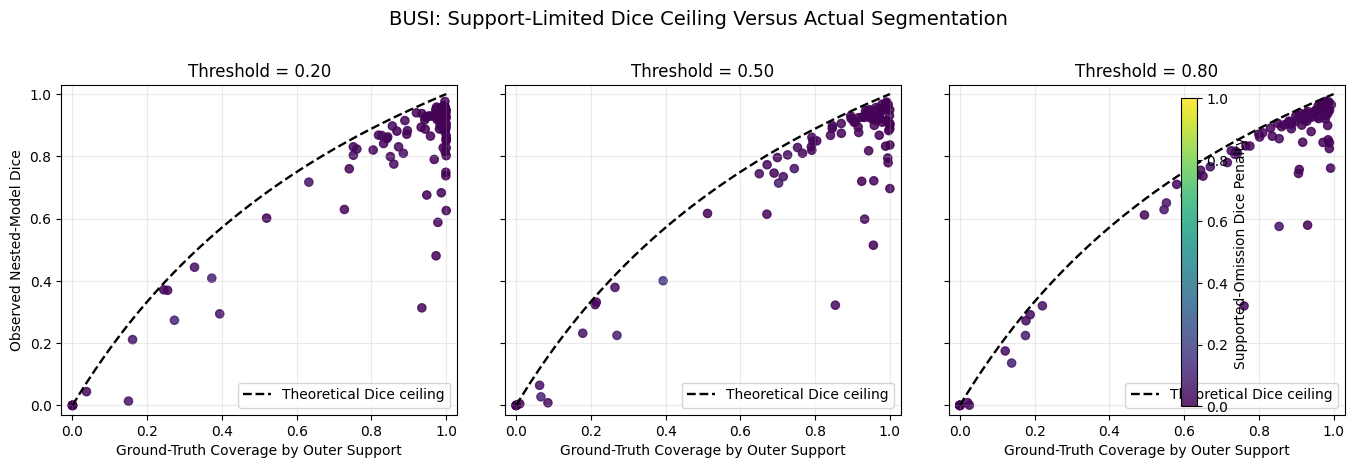

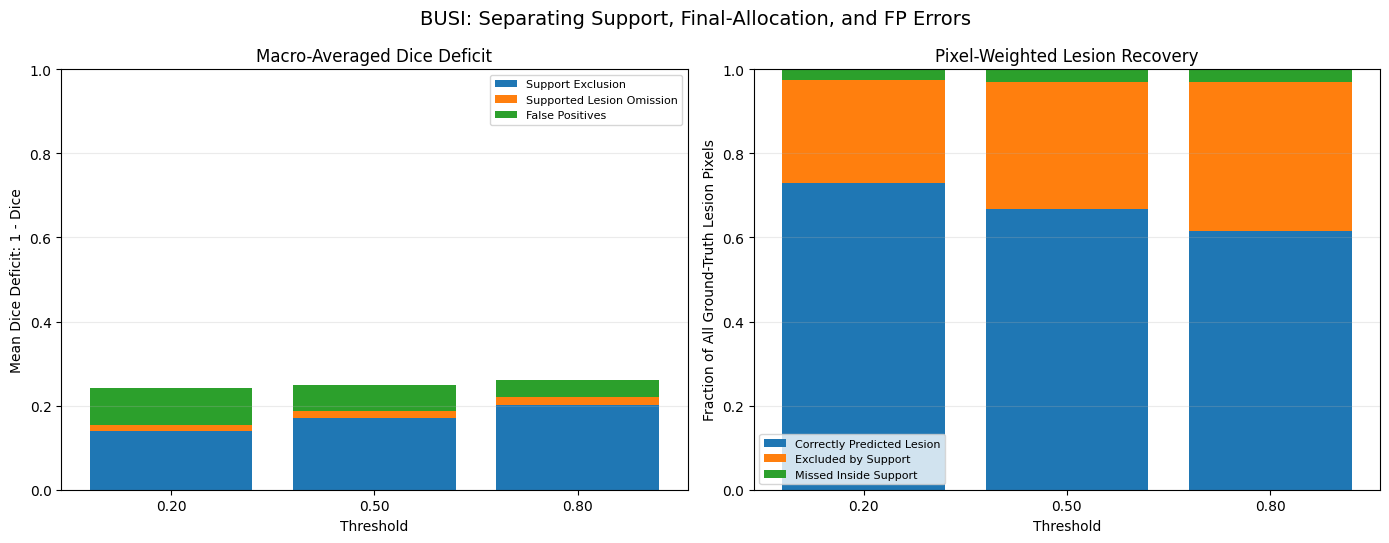

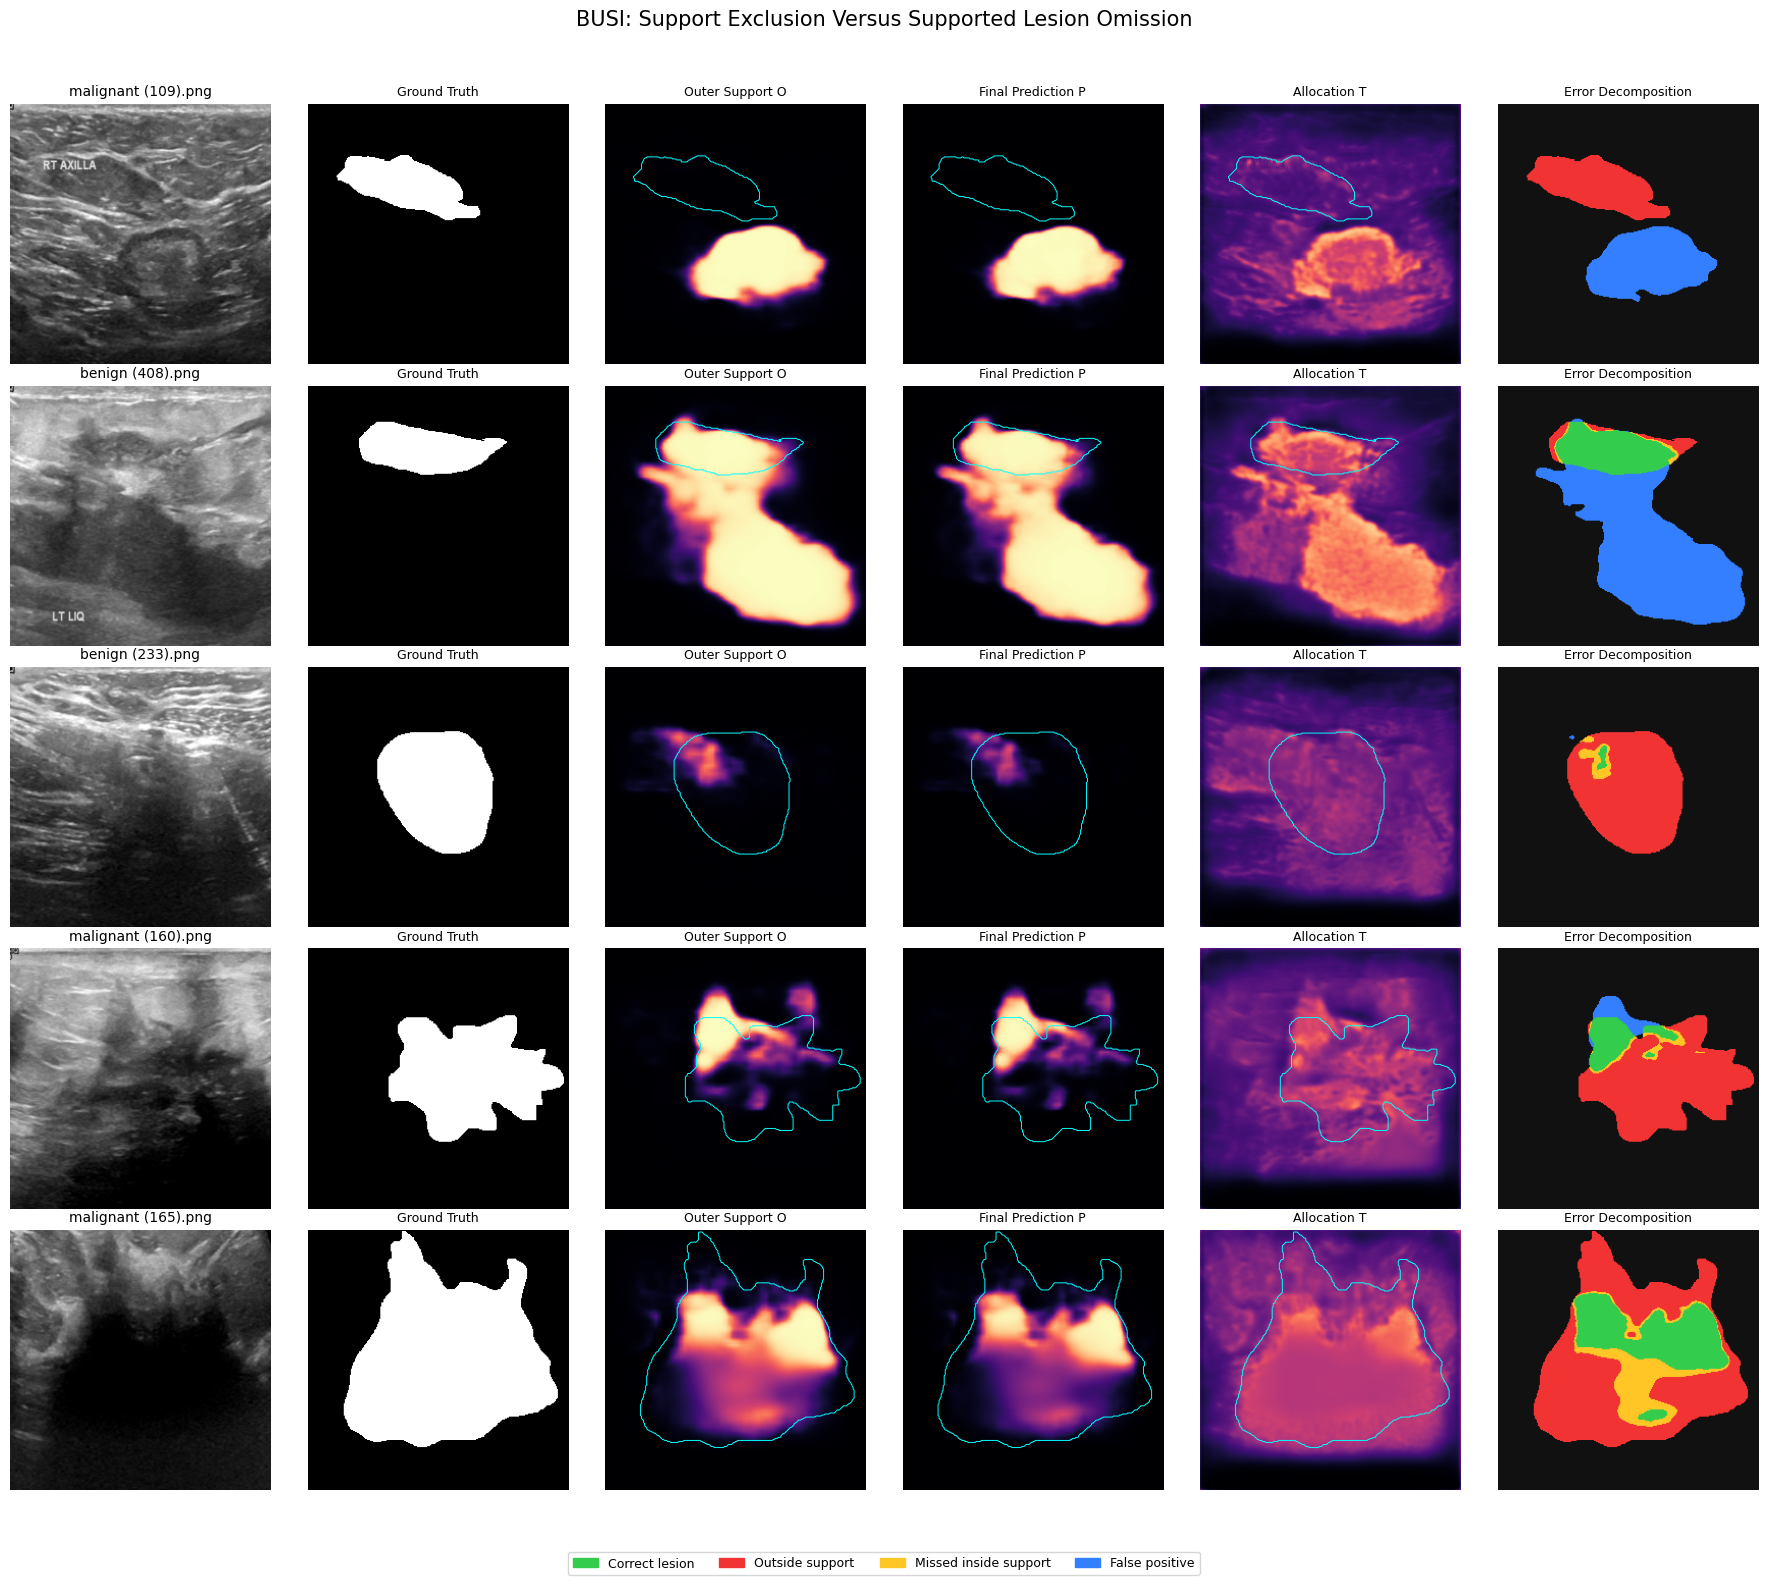


FIVE PREVIOUSLY IDENTIFIED FAILURE CASES
                                             image  final_dice  auxiliary_dice  support_coverage_fraction  oracle_dice_ceiling  support_exclusion_dice_penalty  supported_omission_dice_penalty  false_positive_dice_penalty dominant_error_mechanism
Dataset_BUSI_with_GT/malignant/malignant (109).png      0.0000          0.6700                     0.0000               0.0000                          1.0000                           0.0000                       0.0000        Support exclusion
      Dataset_BUSI_with_GT/benign/benign (408).png      0.3219          0.8881                     0.8540               0.9213                          0.0787                           0.0275                       0.5718          False positives
      Dataset_BUSI_with_GT/benign/benign (233).png      0.0274          0.5878                     0.0663               0.1244                          0.8756                           0.0969                       0.0000

In [36]:

# ============================================================
# CELL 22: FULL SUPPORT-BOTTLENECK ANALYSIS
#
# Dataset: BUSI
# Source: Cell 21 in-memory predictions
# Images: 97 lesion + 20 normal validation images
#
# Quantifies:
#   1. Outer-support coverage
#   2. Theoretical Dice ceiling
#   3. Supported lesion omissions
#   4. Allocation-head threshold shortfall
#   5. False-positive Dice penalty
#   6. Exact Dice-deficit decomposition
#   7. Background suppression on normal images
#
# Thresholds: 0.20, 0.50, 0.80
#
# NO TRAINING
# NO CHECKPOINT RELOADING
# NO TEST DATA
# ============================================================

import json
import uuid

from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Patch


# ============================================================
# 1. CHECK THAT CELL 21 OUTPUTS ARE AVAILABLE
# ============================================================

required_variables = [
    "model_outputs",
    "truth_masks",
    "image_ids",
    "val_dataset21",
    "records",
    "val",
    "data_root",
    "SOURCE_DIR"
]

missing_variables = [
    key for key in required_variables
    if key not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Cell 22 requires Cell 21 in-memory results. "
        "Rerun Cell 21 first.\nMissing: "
        + ", ".join(missing_variables)
    )

SOURCE_DIR22 = Path(SOURCE_DIR)

if not SOURCE_DIR22.is_dir():
    raise FileNotFoundError(
        f"Saved experiment folder unavailable: "
        f"{SOURCE_DIR22}"
    )

THRESHOLDS22 = [0.20, 0.50, 0.80]
PRIMARY_THRESHOLD22 = 0.50

image_ids22 = [str(x) for x in image_ids]

truth22 = np.asarray(
    truth_masks,
    dtype=bool
)

n_images, H, W = truth22.shape

if n_images != len(image_ids22):
    raise ValueError(
        "Image list and ground-truth count disagree."
    )

if len(image_ids22) != len(set(image_ids22)):
    raise ValueError(
        "Duplicate image IDs detected."
    )

for model_name in [
    "baseline",
    "auxiliary",
    "proposed"
]:
    if model_name not in model_outputs:
        raise RuntimeError(
            f"Missing Cell 21 model: {model_name}"
        )


# ============================================================
# 2. VERIFY THE ORIGINAL VALIDATION SPLIT AND ORDER
# ============================================================

manifest22 = pd.read_csv(
    SOURCE_DIR22 / "split_manifest_train_val.csv"
)

saved_val_order = (
    manifest22.loc[
        manifest22["split"] == "val",
        "image"
    ]
    .astype(str)
    .tolist()
)

if saved_val_order != image_ids22:
    raise RuntimeError(
        "Validation image ORDER differs from Cell 19. "
        "Do not continue with mismatched predictions."
    )

active_ids22 = [
    str(
        Path(records[int(i)]["image"]).relative_to(
            Path(data_root)
        )
    )
    for i in val
]

if active_ids22 != image_ids22:
    raise RuntimeError(
        "Active validation indices differ from "
        "the saved Cell 21 prediction order."
    )

if len(val_dataset21) != n_images:
    raise RuntimeError(
        "The visualization dataset has a different size."
    )


# ============================================================
# 3. LOAD THE CACHED PROBABILITY ARRAYS
# ============================================================

nested22 = model_outputs["proposed"]

for key in ["p", "c", "o", "t"]:
    if key not in nested22:
        raise RuntimeError(
            f"Missing nested output: {key}"
        )

P22 = np.asarray(nested22["p"])
C22 = np.asarray(nested22["c"])
O22 = np.asarray(nested22["o"])
T22 = np.asarray(nested22["t"])

B22 = np.asarray(
    model_outputs["baseline"]["p"]
)

AUX22 = np.asarray(
    model_outputs["auxiliary"]["p"]
)

arrays22 = {
    "P": P22,
    "C": C22,
    "O": O22,
    "T": T22,
    "Baseline": B22,
    "Auxiliary": AUX22
}

for name, array in arrays22.items():

    if array.shape != truth22.shape:
        raise ValueError(
            f"{name} shape mismatch: "
            f"{array.shape} vs {truth22.shape}"
        )

    if not np.isfinite(array).all():
        raise ValueError(
            f"{name} contains non-finite values."
        )

    if array.min() < -1e-5 or array.max() > 1.00001:
        raise ValueError(
            f"{name} contains invalid probabilities."
        )


# ============================================================
# 4. CHECK THE NESTED MATHEMATICAL CONSTRAINT
# ============================================================

EPS22 = 1e-5

if np.any(C22 > P22 + EPS22):
    raise RuntimeError(
        "Core exceeds final probability."
    )

if np.any(P22 > O22 + EPS22):
    raise RuntimeError(
        "Final probability exceeds outer support."
    )

reconstructed22 = (
    C22 + (O22 - C22) * T22
)

max_reconstruction_error = float(
    np.max(np.abs(reconstructed22 - P22))
)

if max_reconstruction_error > 1e-5:
    raise RuntimeError(
        "Cached predictions do not match "
        "P=C+(O-C)*T."
    )

print("=" * 70)
print("CELL 22: SUPPORT-BOTTLENECK ANALYSIS")
print("=" * 70)

print("Validation split identity/order: PASSED")
print("Nested probability ordering: PASSED")
print(
    "Maximum formula reconstruction error:",
    max_reconstruction_error
)

print("Total images:", n_images)
print(
    "Lesion images:",
    int(np.count_nonzero(truth22.any(axis=(1, 2))))
)
print(
    "Normal images:",
    int(np.count_nonzero(~truth22.any(axis=(1, 2))))
)


# ============================================================
# 5. CREATE A NEW UNIQUE GOOGLE DRIVE OUTPUT FOLDER
# ============================================================

run_stamp22 = (
    datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%SZ"
    )
    + "_"
    + uuid.uuid4().hex[:6]
)

OUT22 = (
    SOURCE_DIR22
    / "cell22_support_bottleneck"
    / run_stamp22
)

OUT22.mkdir(
    parents=True,
    exist_ok=False
)

print("\nGoogle Drive output folder:")
print(OUT22)


# ============================================================
# 6. METRIC HELPER
# ============================================================

def dice_binary22(prediction, reference):

    pred_count = int(prediction.sum())
    gt_count = int(reference.sum())

    if gt_count == 0:
        return np.nan

    intersection = int(
        np.logical_and(
            prediction, reference
        ).sum()
    )

    return float(
        2 * intersection
        / (gt_count + pred_count)
    )


# ============================================================
# 7. EVALUATE EVERY VALIDATION IMAGE
# ============================================================

lesion_rows22 = []
normal_rows22 = []

for threshold in THRESHOLDS22:

    print(
        f"\nAnalyzing threshold {threshold:.2f}..."
    )

    for i in range(n_images):

        gt = truth22[i]
        gt_count = int(gt.sum())

        c = C22[i]
        o = O22[i]
        p = P22[i]
        t = T22[i]

        core_mask = c >= threshold
        support_mask = o >= threshold
        final_mask = p >= threshold

        baseline_mask = B22[i] >= threshold
        auxiliary_mask = AUX22[i] >= threshold

        # Because P <= O:
        # every predicted-positive pixel must
        # also be inside thresholded support.
        if np.any(final_mask & ~support_mask):
            raise RuntimeError(
                f"Nested mask containment failed: "
                f"{image_ids22[i]}"
            )

        if gt_count == 0:

            normal_rows22.append({

                "image": image_ids22[i],

                "threshold": threshold,

                "support_fp_pixels": int(
                    support_mask.sum()
                ),

                "final_fp_pixels": int(
                    final_mask.sum()
                ),

                "core_fp_pixels": int(
                    core_mask.sum()
                ),

                "baseline_fp_pixels": int(
                    baseline_mask.sum()
                ),

                "auxiliary_fp_pixels": int(
                    auxiliary_mask.sum()
                ),

                "support_background_removed":
                    int(
                        np.logical_and(
                            support_mask,
                            ~final_mask
                        ).sum()
                    ),

                "final_false_positive_image":
                    int(final_mask.any()),

                "auxiliary_false_positive_image":
                    int(auxiliary_mask.any()),

                "baseline_false_positive_image":
                    int(baseline_mask.any())

            })

            continue

        # ----------------------------------------------------
        # A. TRUE POSITIVES AND FALSE POSITIVES
        # ----------------------------------------------------

        supported_gt = gt & support_mask

        true_positive = gt & final_mask

        excluded_gt = gt & ~support_mask

        supported_but_missed = (
            gt & support_mask & ~final_mask
        )

        final_fp = final_mask & ~gt

        support_fp = support_mask & ~gt

        # Background pixels that support admits
        # but the final segmentation removes.
        background_removed = (
            support_mask & ~final_mask & ~gt
        )

        n_supported_gt = int(supported_gt.sum())

        n_tp = int(true_positive.sum())

        n_excluded = int(excluded_gt.sum())

        n_supported_missed = int(
            supported_but_missed.sum()
        )

        n_final_fp = int(final_fp.sum())

        n_support_fp = int(support_fp.sum())

        n_final_pred = int(final_mask.sum())

        n_support_pred = int(support_mask.sum())

        # Every ground-truth lesion pixel belongs
        # to exactly one of these three classes.
        assert (
            n_tp + n_excluded + n_supported_missed
            == gt_count
        )

        # ----------------------------------------------------
        # B. SUPPORT COVERAGE AND DICE CEILING
        # ----------------------------------------------------

        support_coverage = (
            n_supported_gt / gt_count
        )

        final_recall = (
            n_tp / gt_count
        )

        # Oracle: predict ONLY ground-truth pixels
        # inside the predicted support region.
        # This is a theoretical bound, NOT a model.
        dice_ceiling = (
            2 * n_supported_gt
            / (gt_count + n_supported_gt)
        )

        observed_dice = (
            2 * n_tp
            / (gt_count + n_final_pred)
        )

        support_only_dice = (
            2 * n_supported_gt
            / (gt_count + n_support_pred)
        )

        core_only_dice = dice_binary22(
            core_mask, gt
        )

        # ----------------------------------------------------
        # C. EXACT DICE-DEFICIT DECOMPOSITION
        # ----------------------------------------------------

        # Counterfactual: retain only the current
        # final true-positive pixels; delete all
        # current final false positives.
        dice_without_fp = (
            2 * n_tp
            / (gt_count + n_tp)
        )

        # Penalty 1: true lesion excluded by O.
        support_penalty = (
            1.0 - dice_ceiling
        )

        # Penalty 2: supported true lesion pixels
        # still missed by the final prediction.
        supported_omission_penalty = (
            dice_ceiling - dice_without_fp
        )

        # Penalty 3: current false-positive pixels.
        false_positive_penalty = (
            dice_without_fp - observed_dice
        )

        total_decomposed = (
            support_penalty
            + supported_omission_penalty
            + false_positive_penalty
        )

        if abs(
            total_decomposed
            - (1.0 - observed_dice)
        ) > 1e-8:

            raise RuntimeError(
                "Dice decomposition failed for "
                f"{image_ids22[i]}"
            )

        if min(
            support_penalty,
            supported_omission_penalty,
            false_positive_penalty
        ) < -1e-8:

            raise RuntimeError(
                "A decomposed Dice penalty "
                "is unexpectedly negative."
            )

        # ----------------------------------------------------
        # D. ALLOCATION THRESHOLD SHORTFALL
        # ----------------------------------------------------

        # For supported ground-truth pixels with
        # C < threshold <= O, the required allocation
        # is:
        #
        # T_required = (threshold-C)/(O-C)
        #
        # If the final segmentation misses the pixel,
        # T is below that requirement (up to rounding).
        #
        # This is a threshold-conditioned diagnostic,
        # not proof that the allocation head alone
        # caused the failure.

        if n_supported_missed > 0:

            c_missing = c[supported_but_missed]

            o_missing = o[supported_but_missed]

            t_missing = t[supported_but_missed]

            denominator = (
                o_missing - c_missing
            )

            required_t = np.divide(

                threshold - c_missing,

                denominator,

                out=np.full_like(
                    denominator,
                    np.nan,
                    dtype=np.float64
                ),

                where=denominator > 1e-10
            )

            required_t = np.clip(
                required_t, 0, 1
            )

            t_shortfall = np.maximum(
                required_t - t_missing,
                0
            )

            mean_actual_t_missed = float(
                np.nanmean(t_missing)
            )

            mean_required_t_missed = float(
                np.nanmean(required_t)
            )

            mean_t_shortfall = float(
                np.nanmean(t_shortfall)
            )

        else:

            mean_actual_t_missed = np.nan
            mean_required_t_missed = np.nan
            mean_t_shortfall = np.nan

        # ----------------------------------------------------
        # E. REFERENCE MODEL SCORES
        # ----------------------------------------------------

        baseline_dice = dice_binary22(
            baseline_mask, gt
        )

        auxiliary_dice = dice_binary22(
            auxiliary_mask, gt
        )

        # ----------------------------------------------------
        # F. STORE THE PER-IMAGE DIAGNOSTICS
        # ----------------------------------------------------

        lesion_rows22.append({

            "image": image_ids22[i],

            "category": records[
                int(val[i])
            ]["label"],

            "threshold": threshold,

            "gt_pixels": gt_count,

            "support_pixels": n_support_pred,

            "final_pred_pixels": n_final_pred,

            "core_pred_pixels": int(
                core_mask.sum()
            ),

            "supported_gt_pixels":
                n_supported_gt,

            "final_true_positive_pixels": n_tp,

            "gt_excluded_by_support_pixels":
                n_excluded,

            "gt_missed_inside_support_pixels":
                n_supported_missed,

            "support_false_positive_pixels":
                n_support_fp,

            "final_false_positive_pixels":
                n_final_fp,

            "background_pixels_removed_from_support":
                int(background_removed.sum()),

            "support_coverage_fraction":
                support_coverage,

            "support_exclusion_fraction":
                n_excluded / gt_count,

            "supported_omission_fraction":
                n_supported_missed / gt_count,

            "final_recall":
                final_recall,

            "final_precision": (
                n_tp / n_final_pred
                if n_final_pred > 0
                else 0.0
            ),

            "support_only_dice":
                support_only_dice,

            "core_only_dice":
                core_only_dice,

            "final_dice":
                observed_dice,

            "baseline_dice":
                baseline_dice,

            "auxiliary_dice":
                auxiliary_dice,

            "oracle_dice_ceiling":
                dice_ceiling,

            "dice_without_false_positives":
                dice_without_fp,

            "dice_ceiling_minus_actual":
                dice_ceiling - observed_dice,

            "support_exclusion_dice_penalty":
                support_penalty,

            "supported_omission_dice_penalty":
                supported_omission_penalty,

            "false_positive_dice_penalty":
                false_positive_penalty,

            "max_support_global":
                float(o.max()),

            "max_support_on_lesion":
                float(o[gt].max()),

            "mean_support_on_lesion":
                float(o[gt].mean()),

            "max_final_probability_on_lesion":
                float(p[gt].max()),

            "mean_allocation_T_on_supported_gt": (
                float(t[supported_gt].mean())
                if n_supported_gt else np.nan
            ),

            "mean_T_on_supported_missed_gt":
                mean_actual_t_missed,

            "mean_required_T_on_supported_missed_gt":
                mean_required_t_missed,

            "mean_T_shortfall_on_supported_missed_gt":
                mean_t_shortfall,

            "zero_overlap": int(n_tp == 0)

        })


# ============================================================
# 8. SAVE THE COMPLETE 97-IMAGE RESULTS
# ============================================================

lesion_df22 = pd.DataFrame(
    lesion_rows22
)

normal_df22 = pd.DataFrame(
    normal_rows22
)

primary22 = lesion_df22[
    np.isclose(
        lesion_df22["threshold"],
        PRIMARY_THRESHOLD22
    )
].copy()

assert len(primary22) == 97, (
    "Expected 97 foreground BUSI validation images."
)

assert len(normal_df22) == (
    20 * len(THRESHOLDS22)
), "Expected 20 normal images at each threshold."

lesion_df22.to_csv(
    OUT22 / "all_lesions_all_thresholds.csv",
    index=False
)

primary22.to_csv(
    OUT22 / "all_97_lesions_threshold_0p50.csv",
    index=False
)

normal_df22.to_csv(
    OUT22 / "normal_image_background_suppression.csv",
    index=False
)


# ============================================================
# 9. SUMMARIZE THE ERROR MECHANISMS
# ============================================================

summary_rows22 = []

for threshold in THRESHOLDS22:

    cases = lesion_df22[
        np.isclose(
            lesion_df22["threshold"],
            threshold
        )
    ]

    normals = normal_df22[
        np.isclose(
            normal_df22["threshold"],
            threshold
        )
    ]

    total_gt = int(
        cases["gt_pixels"].sum()
    )

    total_tp = int(
        cases["final_true_positive_pixels"].sum()
    )

    total_excluded = int(
        cases["gt_excluded_by_support_pixels"].sum()
    )

    total_supported_missed = int(
        cases["gt_missed_inside_support_pixels"].sum()
    )

    assert (
        total_gt
        == total_tp
        + total_excluded
        + total_supported_missed
    )

    summary_rows22.append({

        "threshold": threshold,

        "lesion_images": len(cases),

        "normal_images": len(normals),

        "mean_final_dice":
            cases["final_dice"].mean(),

        "mean_auxiliary_dice":
            cases["auxiliary_dice"].mean(),

        "mean_baseline_dice":
            cases["baseline_dice"].mean(),

        "mean_oracle_support_dice_ceiling":
            cases["oracle_dice_ceiling"].mean(),

        "mean_support_coverage":
            cases["support_coverage_fraction"].mean(),

        "mean_support_exclusion_penalty":
            cases["support_exclusion_dice_penalty"].mean(),

        "mean_supported_omission_penalty":
            cases["supported_omission_dice_penalty"].mean(),

        "mean_false_positive_penalty":
            cases["false_positive_dice_penalty"].mean(),

        "images_support_coverage_below_0p5":
            int(
                (
                    cases["support_coverage_fraction"] < 0.5
                ).sum()
            ),

        "images_ceiling_below_0p7":
            int(
                (
                    cases["oracle_dice_ceiling"] < 0.7
                ).sum()
            ),

        "images_support_coverage_above_0p8_but_dice_below_0p5":
            int(
                (
                    (cases["support_coverage_fraction"] >= 0.8)
                    & (cases["final_dice"] < 0.5)
                ).sum()
            ),

        "zero_overlap_lesions":
            int(cases["zero_overlap"].sum()),

        "micro_fraction_true_positive":
            total_tp / total_gt,

        "micro_fraction_excluded_by_support":
            total_excluded / total_gt,

        "micro_fraction_missed_inside_support":
            total_supported_missed / total_gt,

        "normal_final_fp_rate":
            normals[
                "final_false_positive_image"
            ].mean(),

        "normal_auxiliary_fp_rate":
            normals[
                "auxiliary_false_positive_image"
            ].mean(),

        "normal_baseline_fp_rate":
            normals[
                "baseline_false_positive_image"
            ].mean(),

        "mean_normal_final_fp_pixels":
            normals["final_fp_pixels"].mean(),

        "mean_normal_support_fp_pixels":
            normals["support_fp_pixels"].mean()

    })


summary22 = pd.DataFrame(
    summary_rows22
)

summary22.to_csv(
    OUT22 / "support_bottleneck_summary.csv",
    index=False
)

print("\n" + "=" * 70)
print("SUMMARY: ALL 97 LESION IMAGES")
print("=" * 70)

summary_display_cols = [

    "threshold",

    "mean_final_dice",

    "mean_oracle_support_dice_ceiling",

    "mean_support_coverage",

    "mean_support_exclusion_penalty",

    "mean_supported_omission_penalty",

    "mean_false_positive_penalty",

    "zero_overlap_lesions",

    "normal_final_fp_rate"

]

print(
    summary22[
        summary_display_cols
    ].round(4).to_string(index=False)
)


# ============================================================
# 10. RANK THE WORST SUPPORT/ALLOCATION CASES
# ============================================================

ranked22 = primary22.copy()

ranked22["rank_support_exclusion"] = (
    ranked22[
        "support_exclusion_dice_penalty"
    ].rank(
        ascending=False,
        method="min"
    )
)

ranked22["rank_supported_omission"] = (
    ranked22[
        "supported_omission_dice_penalty"
    ].rank(
        ascending=False,
        method="min"
    )
)

ranked22["rank_false_positive"] = (
    ranked22[
        "false_positive_dice_penalty"
    ].rank(
        ascending=False,
        method="min"
    )
)

penalty_columns22 = [

    "support_exclusion_dice_penalty",

    "supported_omission_dice_penalty",

    "false_positive_dice_penalty"

]

penalty_names22 = [
    "Support exclusion",
    "Supported lesion omission",
    "False positives"
]

penalty_values22 = ranked22[
    penalty_columns22
].to_numpy()

dominant_indices22 = np.argmax(
    penalty_values22,
    axis=1
)

ranked22["dominant_error_mechanism"] = [
    (
        penalty_names22[index]
        if row.max() > 1e-10
        else "No Dice deficit"
    )
    for row, index in zip(
        penalty_values22,
        dominant_indices22
    )
]

ranked22.to_csv(
    OUT22 / "ranked_97_lesion_error_mechanisms.csv",
    index=False
)

print("\nDOMINANT DICE-DEFICIT MECHANISMS AT 0.50")

print(
    ranked22[
        "dominant_error_mechanism"
    ].value_counts().to_string()
)

print("\n10 WORST SUPPORT-EXCLUSION CASES")

print(
    ranked22.nlargest(
        10,
        "support_exclusion_dice_penalty"
    )[
        [
            "image",
            "final_dice",
            "support_coverage_fraction",
            "oracle_dice_ceiling",
            "support_exclusion_dice_penalty"
        ]
    ].round(4).to_string(index=False)
)

print("\n10 WORST SUPPORTED-OMISSION CASES")

print(
    ranked22.nlargest(
        10,
        "supported_omission_dice_penalty"
    )[
        [
            "image",
            "final_dice",
            "supported_omission_fraction",
            "supported_omission_dice_penalty",
            "mean_T_shortfall_on_supported_missed_gt"
        ]
    ].round(4).to_string(index=False)
)


# ============================================================
# 11. GRAPH 1: SUPPORT COVERAGE VS ACTUAL DICE
# ============================================================

fig, axes = plt.subplots(
    1,
    len(THRESHOLDS22),
    figsize=(17, 5),
    sharex=True,
    sharey=True
)

coverage_grid = np.linspace(
    0,
    1,
    300
)

theoretical_curve = (
    2 * coverage_grid
    / (1 + coverage_grid)
)

scatter_artist = None

for ax, threshold in zip(
    axes,
    THRESHOLDS22
):

    cases = lesion_df22[
        np.isclose(
            lesion_df22["threshold"],
            threshold
        )
    ]

    scatter_artist = ax.scatter(

        cases["support_coverage_fraction"],

        cases["final_dice"],

        c=cases[
            "supported_omission_dice_penalty"
        ],

        cmap="viridis",

        vmin=0,

        vmax=1,

        s=35,

        alpha=0.85
    )

    ax.plot(

        coverage_grid,

        theoretical_curve,

        linestyle="--",

        color="black",

        linewidth=1.7,

        label="Theoretical Dice ceiling"
    )

    ax.set_title(
        f"Threshold = {threshold:.2f}"
    )

    ax.set_xlabel(
        "Ground-Truth Coverage by Outer Support"
    )

    ax.set_xlim(-0.03, 1.03)
    ax.set_ylim(-0.03, 1.03)

    ax.grid(alpha=0.25)

    ax.legend(loc="lower right")

axes[0].set_ylabel(
    "Observed Nested-Model Dice"
)

fig.colorbar(
    scatter_artist,
    ax=list(axes),
    shrink=0.8,
    label="Supported-Omission Dice Penalty"
)

fig.suptitle(
    "BUSI: Support-Limited Dice Ceiling "
    "Versus Actual Segmentation",
    fontsize=14
)

fig.subplots_adjust(
    top=0.83,
    bottom=0.17,
    right=0.88,
    wspace=0.12
)

scatter_path22 = (
    OUT22 / "support_coverage_vs_actual_dice.png"
)

fig.savefig(
    scatter_path22,
    dpi=250,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)


# ============================================================
# 12. GRAPH 2: EXACT DICE-DEFICIT DECOMPOSITION
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5.5)
)

x_positions = np.arange(
    len(THRESHOLDS22)
)

threshold_labels = [
    f"{x:.2f}"
    for x in THRESHOLDS22
]

components = [

    (
        "mean_support_exclusion_penalty",
        "Support Exclusion"
    ),

    (
        "mean_supported_omission_penalty",
        "Supported Lesion Omission"
    ),

    (
        "mean_false_positive_penalty",
        "False Positives"
    )

]

bottoms = np.zeros(
    len(summary22)
)

for column, label in components:

    values = summary22[
        column
    ].to_numpy()

    axes[0].bar(
        x_positions,
        values,
        bottom=bottoms,
        label=label
    )

    bottoms += values

axes[0].set_xticks(
    x_positions,
    threshold_labels
)

axes[0].set_ylim(0, 1)

axes[0].set_xlabel("Threshold")

axes[0].set_ylabel(
    "Mean Dice Deficit: 1 - Dice"
)

axes[0].set_title(
    "Macro-Averaged Dice Deficit"
)

axes[0].legend(
    fontsize=8
)

axes[0].grid(
    axis="y",
    alpha=0.25
)

# The second graph uses all lesion pixels as
# one pool rather than equal image weighting.
pixel_components = [

    (
        "micro_fraction_true_positive",
        "Correctly Predicted Lesion"
    ),

    (
        "micro_fraction_excluded_by_support",
        "Excluded by Support"
    ),

    (
        "micro_fraction_missed_inside_support",
        "Missed Inside Support"
    )

]

bottoms = np.zeros(
    len(summary22)
)

for column, label in pixel_components:

    values = summary22[
        column
    ].to_numpy()

    axes[1].bar(
        x_positions,
        values,
        bottom=bottoms,
        label=label
    )

    bottoms += values

axes[1].set_xticks(
    x_positions,
    threshold_labels
)

axes[1].set_ylim(0, 1)

axes[1].set_xlabel("Threshold")

axes[1].set_ylabel(
    "Fraction of All Ground-Truth Lesion Pixels"
)

axes[1].set_title(
    "Pixel-Weighted Lesion Recovery"
)

axes[1].legend(
    fontsize=8
)

axes[1].grid(
    axis="y",
    alpha=0.25
)

fig.suptitle(
    "BUSI: Separating Support, "
    "Final-Allocation, and FP Errors",
    fontsize=14
)

fig.tight_layout()

decomposition_path22 = (
    OUT22 / "dice_deficit_decomposition.png"
)

fig.savefig(
    decomposition_path22,
    dpi=250,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)


# ============================================================
# 13. GRAPH 3: WORST-CASE PIXEL-LEVEL DIAGNOSTICS
# ============================================================

# Use the same severe cases from Cell 21,
# so their behavior can be compared directly.

requested_cases22 = [

    "malignant (109).png",

    "benign (408).png",

    "benign (233).png",

    "malignant (160).png",

    "malignant (165).png"

]

id_to_position22 = {
    image_id: i
    for i, image_id in enumerate(image_ids22)
}

focus_ids22 = []

for filename in requested_cases22:

    matches = [
        image_id
        for image_id in image_ids22
        if Path(image_id).name == filename
    ]

    if len(matches) == 1:
        focus_ids22.append(matches[0])

# Fall back to worst support-exclusion cases
# if any of the named cases are unavailable.

if len(focus_ids22) < 5:

    for image_id in ranked22.sort_values(
        "support_exclusion_dice_penalty",
        ascending=False
    )["image"]:

        if image_id not in focus_ids22:
            focus_ids22.append(image_id)

        if len(focus_ids22) == 5:
            break


imagenet_mean22 = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

imagenet_std22 = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)

fig, axes = plt.subplots(

    len(focus_ids22),

    6,

    figsize=(18, 3.2 * len(focus_ids22)),

    squeeze=False
)

for row_index, image_id in enumerate(
    focus_ids22
):

    index = id_to_position22[image_id]

    x, _, _, _, _ = val_dataset21[index]

    rgb = (
        x.permute(1, 2, 0).numpy()
        * imagenet_std22
        + imagenet_mean22
    )

    rgb = np.clip(rgb, 0, 1)

    gt = truth22[index]

    o = O22[index]
    p = P22[index]
    t = T22[index]

    support = (
        o >= PRIMARY_THRESHOLD22
    )

    prediction = (
        p >= PRIMARY_THRESHOLD22
    )

    # Pixel-level error classification.
    #
    # Green  = correctly segmented lesion
    # Red    = lesion excluded by outer support
    # Yellow = lesion supported but missed by P
    # Blue   = final false positive
    # Dark   = remaining background

    diagnostic_image = np.full(
        (H, W, 3),
        0.07,
        dtype=np.float32
    )

    diagnostic_image[
        gt & prediction
    ] = [0.2, 0.8, 0.3]

    diagnostic_image[
        gt & ~support
    ] = [0.95, 0.2, 0.2]

    diagnostic_image[
        gt & support & ~prediction
    ] = [1.0, 0.78, 0.15]

    diagnostic_image[
        ~gt & prediction
    ] = [0.2, 0.5, 1.0]

    images_for_display = [

        ("Ultrasound", rgb),

        ("Ground Truth", gt.astype(float)),

        ("Outer Support O", o),

        ("Final Prediction P", p),

        ("Allocation T", t),

        ("Error Decomposition", diagnostic_image)

    ]

    for col_index, (title, img) in enumerate(
        images_for_display
    ):

        ax = axes[
            row_index, col_index
        ]

        if col_index in [0, 5]:

            ax.imshow(img)

        elif col_index == 1:

            ax.imshow(
                img,
                cmap="gray",
                vmin=0,
                vmax=1
            )

        else:

            ax.imshow(
                img,
                cmap="magma",
                vmin=0,
                vmax=1
            )

            ax.contour(
                gt.astype(float),
                levels=[0.5],
                colors="cyan",
                linewidths=0.7
            )

        if col_index == 0:

            ax.set_title(
                Path(image_id).name,
                fontsize=10
            )

        else:

            ax.set_title(
                title,
                fontsize=9
            )

        ax.axis("off")


legend_items22 = [

    Patch(
        color=(0.2, 0.8, 0.3),
        label="Correct lesion"
    ),

    Patch(
        color=(0.95, 0.2, 0.2),
        label="Outside support"
    ),

    Patch(
        color=(1.0, 0.78, 0.15),
        label="Missed inside support"
    ),

    Patch(
        color=(0.2, 0.5, 1.0),
        label="False positive"
    )

]

fig.legend(
    handles=legend_items22,
    loc="lower center",
    ncol=4,
    fontsize=9
)

fig.suptitle(
    "BUSI: Support Exclusion Versus "
    "Supported Lesion Omission",
    fontsize=15
)

fig.tight_layout(
    rect=[0, 0.045, 1, 0.96]
)

failure_path22 = (
    OUT22 / "five_failure_pixel_diagnostics.png"
)

fig.savefig(
    failure_path22,
    dpi=220,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)


# ============================================================
# 14. PRINT PREVIOUSLY IDENTIFIED FAILURE CASES
# ============================================================

focus_report22 = ranked22[
    ranked22["image"].isin(focus_ids22)
].copy()

focus_report22 = (
    focus_report22
    .set_index("image")
    .loc[focus_ids22]
    .reset_index()
)

focus_columns22 = [

    "image",

    "final_dice",

    "auxiliary_dice",

    "support_coverage_fraction",

    "oracle_dice_ceiling",

    "support_exclusion_dice_penalty",

    "supported_omission_dice_penalty",

    "false_positive_dice_penalty",

    "dominant_error_mechanism"

]

focus_report22[
    focus_columns22
].to_csv(
    OUT22 / "five_failure_mechanism_summary.csv",
    index=False
)

print("\n" + "=" * 70)
print("FIVE PREVIOUSLY IDENTIFIED FAILURE CASES")
print("=" * 70)

print(
    focus_report22[
        focus_columns22
    ].round(4).to_string(index=False)
)


# ============================================================
# 15. SAVE REPRODUCIBILITY METADATA
# ============================================================

metadata22 = {

    "analysis": (
        "Full BUSI support-bottleneck "
        "and Dice-deficit decomposition"
    ),

    "source_experiment": str(
        SOURCE_DIR22
    ),

    "thresholds": THRESHOLDS22,

    "primary_threshold":
        PRIMARY_THRESHOLD22,

    "images_analyzed": n_images,

    "foreground_images": len(primary22),

    "normal_images": int(
        n_images - len(primary22)
    ),

    "data_source": (
        "Cell 21 cached validation probabilities"
    ),

    "mathematical_constraint": (
        "C <= P <= O; P=C+(O-C)*T"
    ),

    "oracle_dice_ceiling": (
        "2*GT_intersection_support / "
        "(GT_pixels + GT_intersection_support)"
    ),

    "dice_loss_decomposition": {

        "support_exclusion": (
            "1 - oracle_dice_ceiling"
        ),

        "supported_omission": (
            "oracle_dice_ceiling "
            "- dice_without_false_positives"
        ),

        "false_positive": (
            "dice_without_false_positives "
            "- actual_dice"
        )

    },

    "important_limitations": [

        "The ceiling uses ground truth and is "
        "not a deployable segmentation prediction.",

        "Supported lesion omission is not "
        "proof of an allocation-head defect.",

        "The deficit decomposition is exact "
        "but sequential and descriptive.",

        "BUSI patient independence is unverified.",

        "No held-out test set was evaluated."
    ],

    "training_performed": False,

    "test_set_used": False
}

(OUT22 / "cell22_analysis_config.json").write_text(
    json.dumps(
        metadata22,
        indent=2
    )
)


# ============================================================
# 16. FINAL FILE REPORT
# ============================================================

print("\n" + "=" * 70)
print("CELL 22 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nGoogle Drive output directory:")
print(OUT22)

print("\nGenerated files:")

for path in sorted(
    OUT22.iterdir()
):

    if path.is_file():
        print(" -", path.name)

print("\nVerified:", len(primary22), "lesion images")
print("Evaluated thresholds:", THRESHOLDS22)

print("\nNo model retraining performed.")
print("No checkpoints were modified.")
print("No test images were evaluated.")
